# Modal Shift Analysis — 4 GENeSYS-MOD Scenarios

Visualization for manuscript Section 4.4: Role of modal shift to rail.

Compares **baseline (road-only)** vs **road + rail** for all 4 electricity price scenarios:
- Go RES, NECPEssentials, REPowerEU++, Trinity

Figures produced:
1. Modal split volume over time (stacked bars: Rail / Road ICEV / Road BEV)
2. BEV fleet comparison baseline vs rail
3. Charging demand by latitude: baseline vs rail
4. Rail transport allocation by latitude (where is rail shift happening?)

In [61]:
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
from scipy.ndimage import gaussian_filter1d
import ast
import re
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
})
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    'font.serif': 'mathpazo',
    'font.size': 20,
    'axes.labelsize': 20
})

BASE_DIR = Path('.').resolve()
RESULTS_DIR = BASE_DIR / 'results'
INPUT_DIR = BASE_DIR / 'input_data'
FIG_DIR = BASE_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)

print(f'Base directory: {BASE_DIR}')

Base directory: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM


In [62]:
# ============================================================
# Scenario configuration
# ============================================================
SCENARIOS = {
    'Go RES': {
        'baseline_dir': RESULTS_DIR / 'uncertainty_scenarios_v2' / 'scenario_000',
        'baseline_prefix': 'scenario_000_cs_2026-02-14_18-25-42',
        'rail_dir': RESULTS_DIR / 'rail' / 'scenario_004',
        'rail_prefix': 'scenario_004_cs_2026-02-14_20-52-20',
        'input_baseline': INPUT_DIR / 'uncertainty_scenarios' / 'scenario_000',
        'input_rail': INPUT_DIR / 'uncertainty_scenarios_rail' / 'scenario_000',
    },
    'NECPEssentials': {
        'baseline_dir': RESULTS_DIR / 'uncertainty_scenarios_v2' / 'scenario_001',
        'baseline_prefix': 'scenario_001_cs_2026-02-14_20-00-45',
        'rail_dir': RESULTS_DIR / 'rail' / 'scenario_010',
        'rail_prefix': 'scenario_010_cs_2026-02-14_21-34-41',
        'input_baseline': INPUT_DIR / 'uncertainty_scenarios' / 'scenario_001',
        'input_rail': INPUT_DIR / 'uncertainty_scenarios_rail' / 'scenario_001',
    },
    'REPowerEU++': {
        'baseline_dir': RESULTS_DIR / 'uncertainty_scenarios_v2' / 'scenario_002',
        'baseline_prefix': 'scenario_002_cs_2026-02-14_22-18-02',
        'rail_dir': RESULTS_DIR / 'rail' / 'scenario_016',
        'rail_prefix': 'scenario_016_cs_2026-02-14_22-16-25',
        'input_baseline': INPUT_DIR / 'uncertainty_scenarios' / 'scenario_002',
        'input_rail': INPUT_DIR / 'uncertainty_scenarios_rail' / 'scenario_002',
    },
    'Trinity': {
        'baseline_dir': RESULTS_DIR / 'uncertainty_scenarios_v2' / 'scenario_003',
        'baseline_prefix': 'scenario_003_cs_2026-02-15_00-33-53',
        'rail_dir': RESULTS_DIR / 'rail' / 'scenario_022',
        'rail_prefix': 'scenario_022_cs_2026-02-14_22-49-14',
        'input_baseline': INPUT_DIR / 'uncertainty_scenarios' / 'scenario_003',
        'input_rail': INPUT_DIR / 'uncertainty_scenarios_rail' / 'scenario_003',
    },
}

# Colors
COLOR_RAIL   = '#3498DB'   # Blue
COLOR_ICEV   = '#E74C3C'   # Red
COLOR_BEV    = '#2ECC71'   # Green
COLOR_BASELINE = '#555555' # Dark gray for baseline lines

SCENARIO_COLORS = {
    'Go RES':         '#1f77b4',
    'NECPEssentials':  '#ff7f0e',
    'REPowerEU++':    '#2ca02c',
    'Trinity':        '#d62728',
}

COUNTRY_COLORS = {
    'NO': '#4e79a7', 'SE': '#f28e2c', 'FI': '#76b7b2',
    'DK': '#e15759', 'DE': '#59a14f', 'AT': '#edc949', 'IT': '#af7aa1',
}

# Model years (4-year timestep from 2020)
MODEL_YEARS = list(range(2020, 2061, 4))

print('Configuration loaded:', list(SCENARIOS.keys()))

Configuration loaded: ['Go RES', 'NECPEssentials', 'REPowerEU++', 'Trinity']


In [63]:
plt.rcParams.update({
    'text.usetex': False,
    'font.family': 'serif',
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'figure.figsize': (12, 8),
    'axes.facecolor': '#f0f0f0',
    'figure.facecolor': 'white',
})

In [64]:
# ============================================================
# Data loading utilities
# ============================================================

def load_yaml(filepath):
    """Load a YAML file."""
    with open(filepath, 'r', encoding='utf-8') as f:
        return yaml.safe_load(f)


def parse_f_dict_key(key_str):
    """Parse f_dict key string: (year, (prod, odpair, path), (mode, tv), gen) -> tuple."""
    try:
        return ast.literal_eval(key_str)
    except:
        return None


def parse_cartesian_index(key_str):
    """Parse CartesianIndex(a, b, c, ...) -> tuple of ints."""
    m = re.findall(r'CartesianIndex\(([^)]+)\)', str(key_str))
    if m:
        return tuple(int(x.strip()) for x in m[0].split(','))
    return None


def load_f_dict(results_dir, prefix):
    """Load and parse f_dict (flow variable)."""
    fpath = results_dir / f'{prefix}_f_dict.yaml'
    raw = load_yaml(fpath)
    parsed = {}
    for k, v in raw.items():
        key = parse_f_dict_key(k)
        if key is not None:
            parsed[key] = float(v)
    return parsed


def load_h_dict(results_dir, prefix):
    """Load h_dict (fleet variable)."""
    fpath = results_dir / f'{prefix}_h_dict.yaml'
    raw = load_yaml(fpath)
    parsed = {}
    for k, v in raw.items():
        key = parse_f_dict_key(k)  # same tuple format
        if key is not None:
            parsed[key] = float(v)
    return parsed


def load_q_fuel_infr_plus(results_dir, prefix):
    """Load q_fuel_infr_plus_dict (charging infrastructure capacity)."""
    fpath = results_dir / f'{prefix}_q_fuel_infr_plus_dict.yaml'
    raw = load_yaml(fpath)
    parsed = {}
    for k, v in raw.items():
        idx = parse_cartesian_index(k)
        if idx is not None:
            parsed[idx] = float(v)
    return parsed


def load_input_data(input_dir):
    """Load geographic elements, paths, odpairs from input folder."""
    geo = load_yaml(input_dir / 'GeographicElement.yaml')
    paths = load_yaml(input_dir / 'Path.yaml')
    odpairs = load_yaml(input_dir / 'Odpair.yaml')
    
    # Build lookup dictionaries
    geo_by_id = {g['id']: g for g in geo}
    path_by_id = {p['id']: p for p in paths}
    odpair_by_id = {o['id']: o for o in odpairs}
    
    return {
        'geo_elements': geo,
        'geo_by_id': geo_by_id,
        'paths': paths,
        'path_by_id': path_by_id,
        'odpairs': odpairs,
        'odpair_by_id': odpair_by_id,
    }


print('Loading functions defined.')

Loading functions defined.


In [65]:
# ============================================================
# Load all scenario data
# ============================================================
data = {}

for scen_name, cfg in SCENARIOS.items():
    print(f'Loading {scen_name}...')
    data[scen_name] = {}
    
    # Baseline (road-only)
    data[scen_name]['baseline'] = {
        'f': load_f_dict(cfg['baseline_dir'], cfg['baseline_prefix']),
        'input': load_input_data(cfg['input_baseline']),
    }
    
    # Rail
    data[scen_name]['rail'] = {
        'f': load_f_dict(cfg['rail_dir'], cfg['rail_prefix']),
        'q_infr': load_q_fuel_infr_plus(cfg['rail_dir'], cfg['rail_prefix']),
        'input': load_input_data(cfg['input_rail']),
    }
    
    # Also load baseline q_infr for latitude comparison
    data[scen_name]['baseline']['q_infr'] = load_q_fuel_infr_plus(
        cfg['baseline_dir'], cfg['baseline_prefix']
    )
    
    n_f_base = len(data[scen_name]['baseline']['f'])
    n_f_rail = len(data[scen_name]['rail']['f'])
    print(f'  Baseline: {n_f_base:,} flow entries, Rail: {n_f_rail:,} flow entries')

print('\nAll data loaded.')

Loading Go RES...
  Baseline: 92,605 flow entries, Rail: 60,115 flow entries
Loading NECPEssentials...
  Baseline: 94,474 flow entries, Rail: 60,695 flow entries
Loading REPowerEU++...
  Baseline: 93,100 flow entries, Rail: 60,610 flow entries
Loading Trinity...
  Baseline: 95,191 flow entries, Rail: 60,957 flow entries

All data loaded.


In [66]:
# ============================================================
# Calculate transport volumes by mode and technology
# ============================================================

def calculate_tkm_by_mode_tech(f_dict, input_data):
    """
    Calculate tonne-km by mode and technology for each year.
    
    Returns: {year: {'road_icev': tkm, 'road_bev': tkm, 'rail': tkm}}
    """
    path_by_id = input_data['path_by_id']
    result = {}
    
    for key, tonnes in f_dict.items():
        year = key[0]
        path_id = key[1][2]
        mode_id = key[2][0]
        tv_id = key[2][1]
        
        if year not in result:
            result[year] = {'road_icev': 0.0, 'road_bev': 0.0, 'rail': 0.0}
        
        # Get path length
        path_info = path_by_id.get(path_id)
        if path_info is None:
            continue
        length_km = path_info['length']
        tkm = tonnes * length_km
        
        if mode_id == 2:  # rail
            result[year]['rail'] += tkm
        elif mode_id == 1:  # road
            if tv_id == 1:  # BEV
                result[year]['road_bev'] += tkm
            else:  # ICEV (tv_id=0)
                result[year]['road_icev'] += tkm
    
    return result


def calculate_tonnes_by_mode_tech(f_dict):
    """
    Calculate tonnes by mode and technology for each year.
    
    Returns: {year: {'road_icev': t, 'road_bev': t, 'rail': t}}
    """
    result = {}
    for key, tonnes in f_dict.items():
        year = key[0]
        mode_id = key[2][0]
        tv_id = key[2][1]
        
        if year not in result:
            result[year] = {'road_icev': 0.0, 'road_bev': 0.0, 'rail': 0.0}
        
        if mode_id == 2:
            result[year]['rail'] += tonnes
        elif mode_id == 1:
            if tv_id == 1:
                result[year]['road_bev'] += tonnes
            else:
                result[year]['road_icev'] += tonnes
    
    return result


# Compute for all scenarios
tkm_data = {}
tonnes_data = {}

for scen_name in SCENARIOS:
    tkm_data[scen_name] = {}
    tonnes_data[scen_name] = {}
    for run_type in ['baseline', 'rail']:
        tkm_data[scen_name][run_type] = calculate_tkm_by_mode_tech(
            data[scen_name][run_type]['f'],
            data[scen_name][run_type]['input']
        )
        tonnes_data[scen_name][run_type] = calculate_tonnes_by_mode_tech(
            data[scen_name][run_type]['f']
        )

# Print summary for Go RES rail
print('=== Go RES — Rail scenario — TKM by mode (billions) ===')
for y in sorted(tkm_data['Go RES']['rail'].keys()):
    d = tkm_data['Go RES']['rail'][y]
    total = sum(d.values())
    rail_pct = d['rail'] / total * 100 if total > 0 else 0
    bev_pct = d['road_bev'] / total * 100 if total > 0 else 0
    print(f"  {y}: ICEV={d['road_icev']/1e9:.2f}  BEV={d['road_bev']/1e9:.2f}  "
          f"Rail={d['rail']/1e9:.2f}  Total={total/1e9:.2f}  "
          f"Rail%={rail_pct:.1f}%  BEV%={bev_pct:.1f}%")

=== Go RES — Rail scenario — TKM by mode (billions) ===
  2020: ICEV=0.03  BEV=0.00  Rail=0.00  Total=0.03  Rail%=0.0%  BEV%=0.0%
  2024: ICEV=0.03  BEV=0.00  Rail=0.00  Total=0.03  Rail%=0.0%  BEV%=0.0%
  2028: ICEV=0.03  BEV=0.00  Rail=0.00  Total=0.03  Rail%=2.4%  BEV%=2.8%
  2032: ICEV=0.03  BEV=0.00  Rail=0.00  Total=0.04  Rail%=4.4%  BEV%=6.4%
  2036: ICEV=0.03  BEV=0.01  Rail=0.00  Total=0.04  Rail%=6.1%  BEV%=25.3%
  2040: ICEV=0.02  BEV=0.01  Rail=0.00  Total=0.04  Rail%=7.6%  BEV%=35.0%
  2044: ICEV=0.02  BEV=0.02  Rail=0.00  Total=0.04  Rail%=9.1%  BEV%=47.1%
  2048: ICEV=0.01  BEV=0.03  Rail=0.00  Total=0.04  Rail%=10.4%  BEV%=59.9%
  2052: ICEV=0.01  BEV=0.03  Rail=0.01  Total=0.05  Rail%=11.7%  BEV%=73.7%
  2056: ICEV=0.01  BEV=0.03  Rail=0.01  Total=0.05  Rail%=13.0%  BEV%=72.3%
  2060: ICEV=0.00  BEV=0.01  Rail=0.00  Total=0.01  Rail%=30.0%  BEV%=70.0%


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

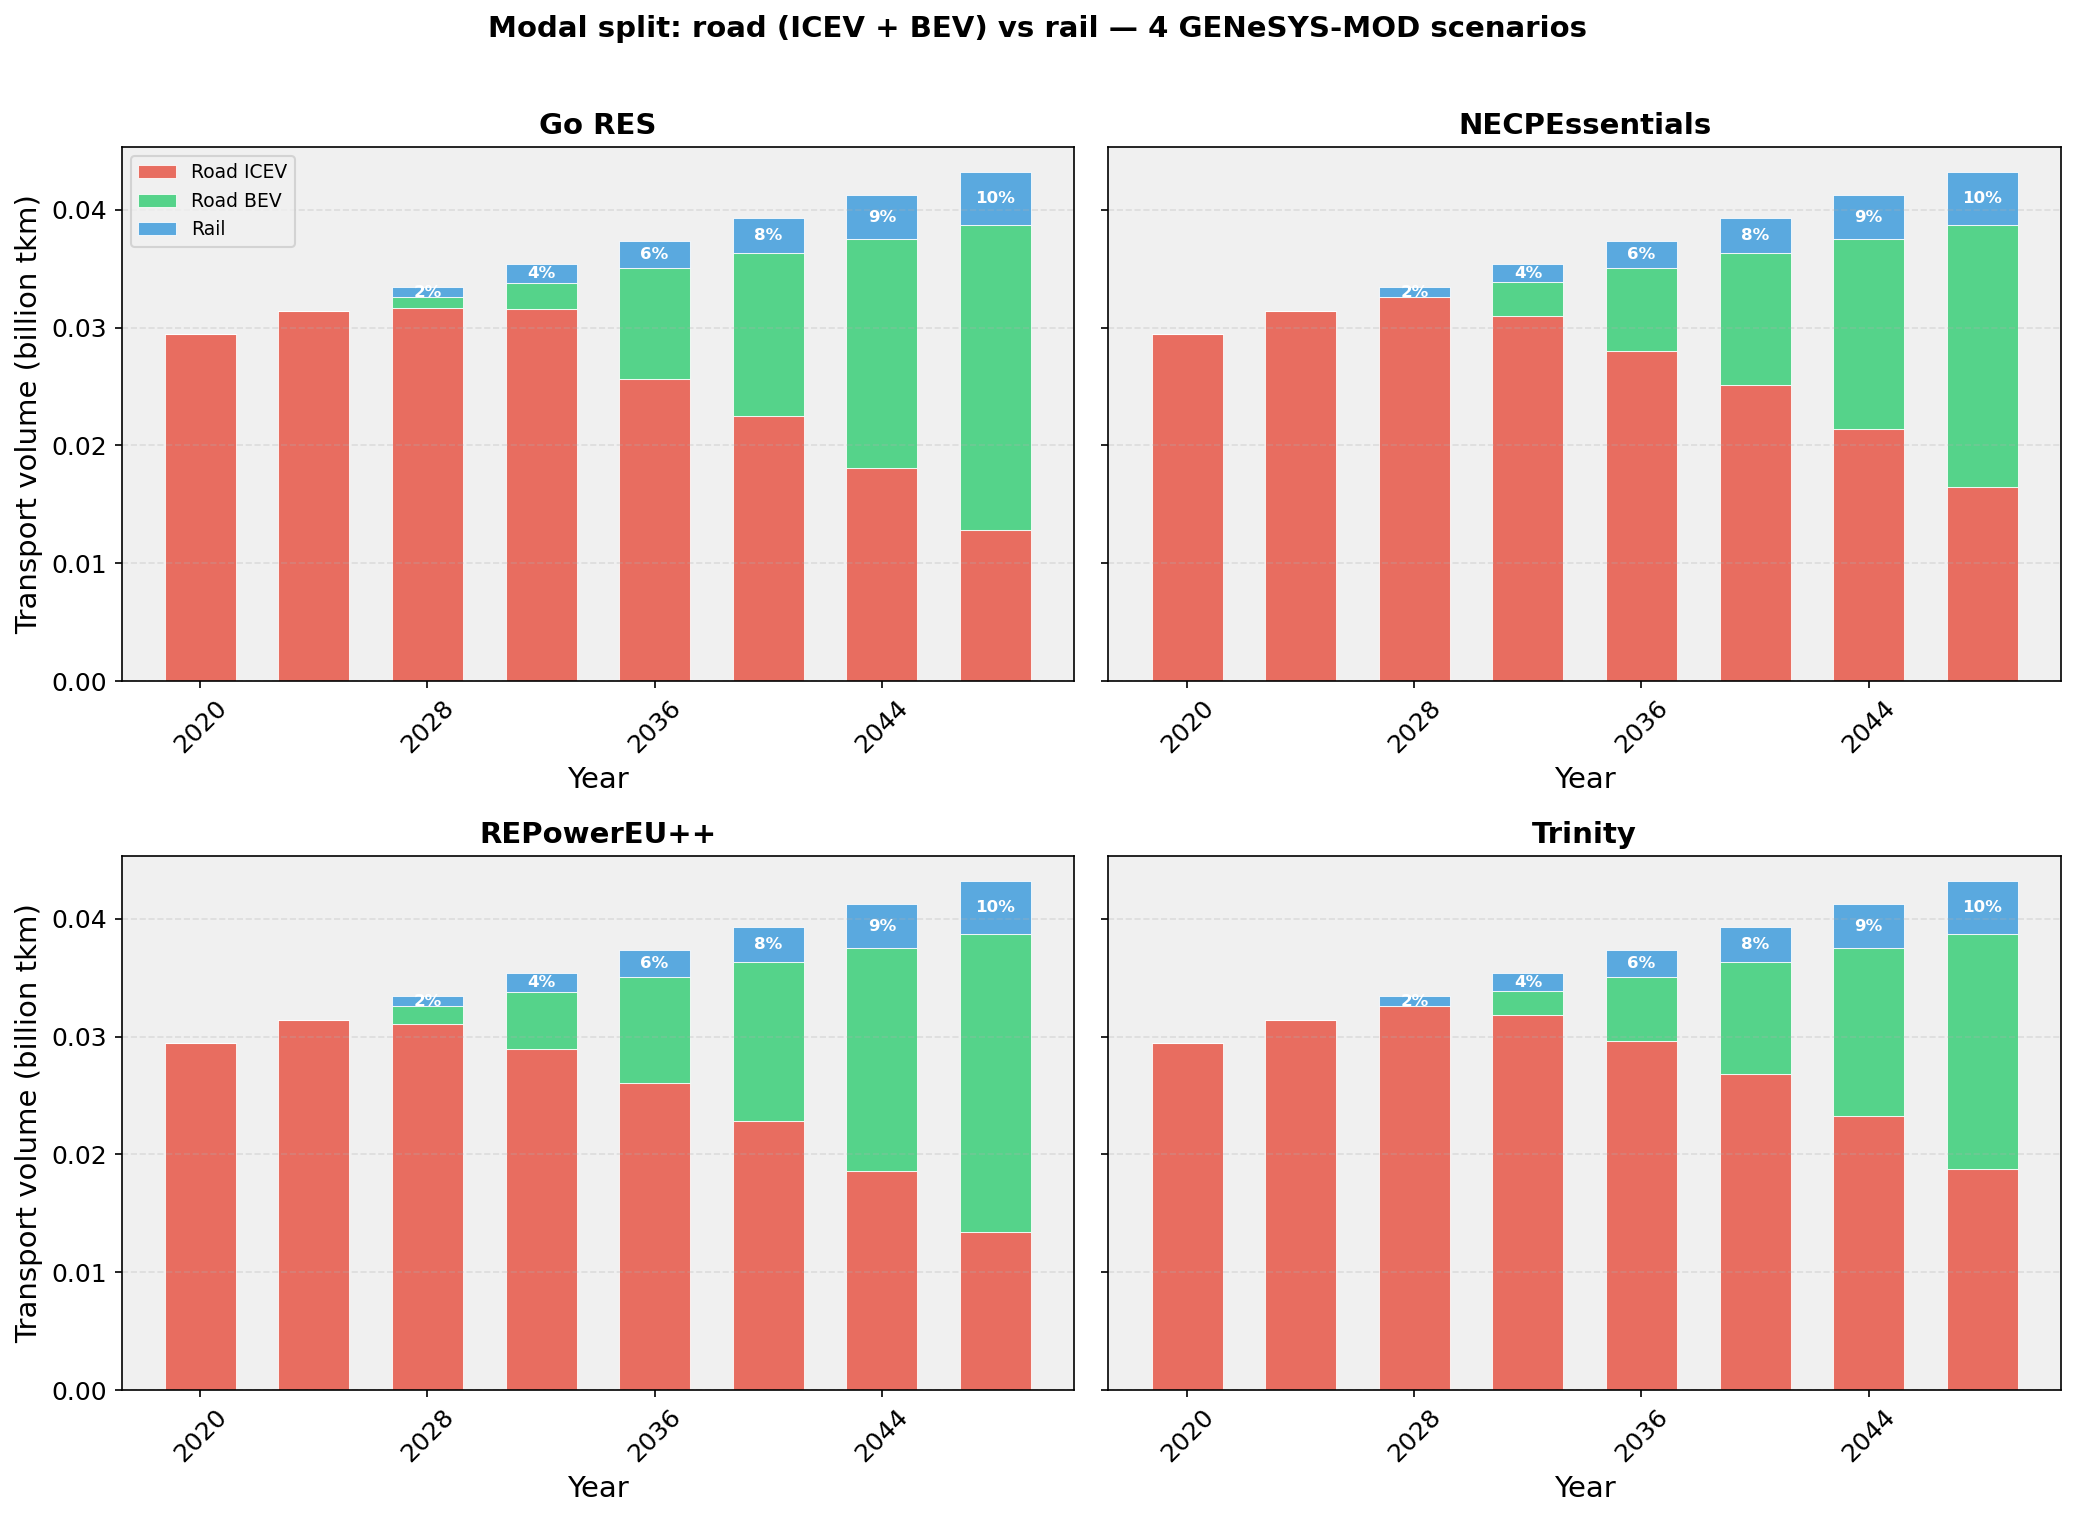

Saved: figures/modal_split_4scenarios_tkm.pdf


In [67]:
# ============================================================
# Figure 1: Modal split volume over time — 4 scenarios
# (Stacked bars: Rail / Road ICEV / Road BEV)
# => For manuscript fig:modalshift_road_rail
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
axes_flat = axes.flatten()

for idx, (scen_name, ax) in enumerate(zip(SCENARIOS.keys(), axes_flat)):
    vol = tkm_data[scen_name]['rail']  # rail scenario results
    years = sorted([y for y in vol.keys() if y in MODEL_YEARS and y <= 2048])
    
    rail_vals = [vol[y]['rail'] / 1e9 for y in years]
    icev_vals = [vol[y]['road_icev'] / 1e9 for y in years]
    bev_vals  = [vol[y]['road_bev'] / 1e9 for y in years]
    
    bar_width = 2.5
    
    # Stack: bottom = ICEV, middle = BEV, top = Rail
    ax.bar(years, icev_vals, width=bar_width, color=COLOR_ICEV, alpha=0.8,
           label='Road ICEV', edgecolor='white', linewidth=0.5)
    ax.bar(years, bev_vals, width=bar_width, bottom=icev_vals, color=COLOR_BEV, alpha=0.8,
           label='Road BEV', edgecolor='white', linewidth=0.5)
    bottom_rail = [i + b for i, b in zip(icev_vals, bev_vals)]
    ax.bar(years, rail_vals, width=bar_width, bottom=bottom_rail, color=COLOR_RAIL, alpha=0.8,
           label='Rail', edgecolor='white', linewidth=0.5)
    
    # Add rail percentage labels
    for yi, y in enumerate(years):
        total = icev_vals[yi] + bev_vals[yi] + rail_vals[yi]
        if total > 0 and rail_vals[yi] / total > 0.02:
            rail_pct = rail_vals[yi] / total * 100
            ax.text(y, bottom_rail[yi] + rail_vals[yi] / 2, f'{rail_pct:.0f}%',
                    ha='center', va='center', fontsize=8, fontweight='bold', color='white')
    
    ax.set_title(scen_name, fontweight='bold')
    ax.set_xlabel('Year')
    if idx % 2 == 0:
        ax.set_ylabel('Transport volume (billion tkm)')
    ax.set_xticks(years[::2])  # every other year label
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3, linestyle='--', axis='y')
    if idx == 0:
        ax.legend(loc='upper left', fontsize=9)

fig.suptitle('Modal split: road (ICEV + BEV) vs rail — 4 GENeSYS-MOD scenarios',
             fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'modal_split_4scenarios_tkm.pdf')
plt.savefig(FIG_DIR / 'modal_split_4scenarios_tkm.png')
plt.show()
print('Saved: figures/modal_split_4scenarios_tkm.pdf')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

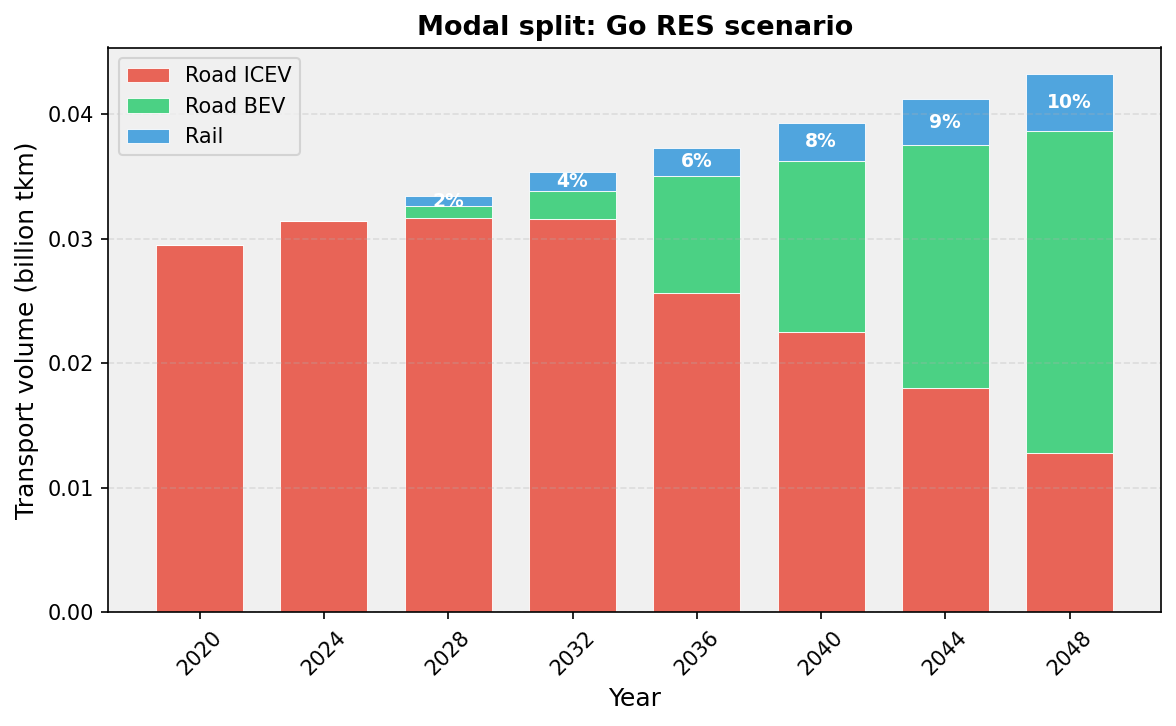

Saved: figures/modal_split_GoRES_tkm.pdf


In [68]:
# ============================================================
# Figure 1b: Modal split — Go RES only (single panel)
# ============================================================

scen_name = 'Go RES'
vol = tkm_data[scen_name]['rail']
years = sorted([y for y in vol.keys() if y in MODEL_YEARS and y <= 2048])

rail_vals = [vol[y]['rail'] / 1e9 for y in years]
icev_vals = [vol[y]['road_icev'] / 1e9 for y in years]
bev_vals  = [vol[y]['road_bev'] / 1e9 for y in years]

fig, ax = plt.subplots(figsize=(8, 5))
bar_width = 2.8

ax.bar(years, icev_vals, width=bar_width, color=COLOR_ICEV, alpha=0.85,
       label='Road ICEV', edgecolor='white', linewidth=0.5)
ax.bar(years, bev_vals, width=bar_width, bottom=icev_vals, color=COLOR_BEV, alpha=0.85,
       label='Road BEV', edgecolor='white', linewidth=0.5)
bottom_rail = [i + b for i, b in zip(icev_vals, bev_vals)]
ax.bar(years, rail_vals, width=bar_width, bottom=bottom_rail, color=COLOR_RAIL, alpha=0.85,
       label='Rail', edgecolor='white', linewidth=0.5)

# Rail percentage labels
for yi, y in enumerate(years):
    total = icev_vals[yi] + bev_vals[yi] + rail_vals[yi]
    if total > 0 and rail_vals[yi] / total > 0.02:
        rail_pct = rail_vals[yi] / total * 100
        ax.text(y, bottom_rail[yi] + rail_vals[yi] / 2, f'{rail_pct:.0f}%',
                ha='center', va='center', fontsize=9, fontweight='bold', color='white')

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Transport volume (billion tkm)', fontsize=12)
ax.set_title(f'Modal split: {scen_name} scenario', fontweight='bold', fontsize=13)
ax.set_xticks(years)
ax.tick_params(axis='x', rotation=45, labelsize=10)
ax.tick_params(axis='y', labelsize=10)
ax.grid(True, alpha=0.3, linestyle='--', axis='y')
ax.legend(fontsize=10, loc='upper left')

plt.tight_layout()
plt.savefig(FIG_DIR / 'modal_split_GoRES_tkm.pdf')
plt.savefig(FIG_DIR / 'modal_split_GoRES_tkm.png')
plt.show()
print('Saved: figures/modal_split_GoRES_tkm.pdf')


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

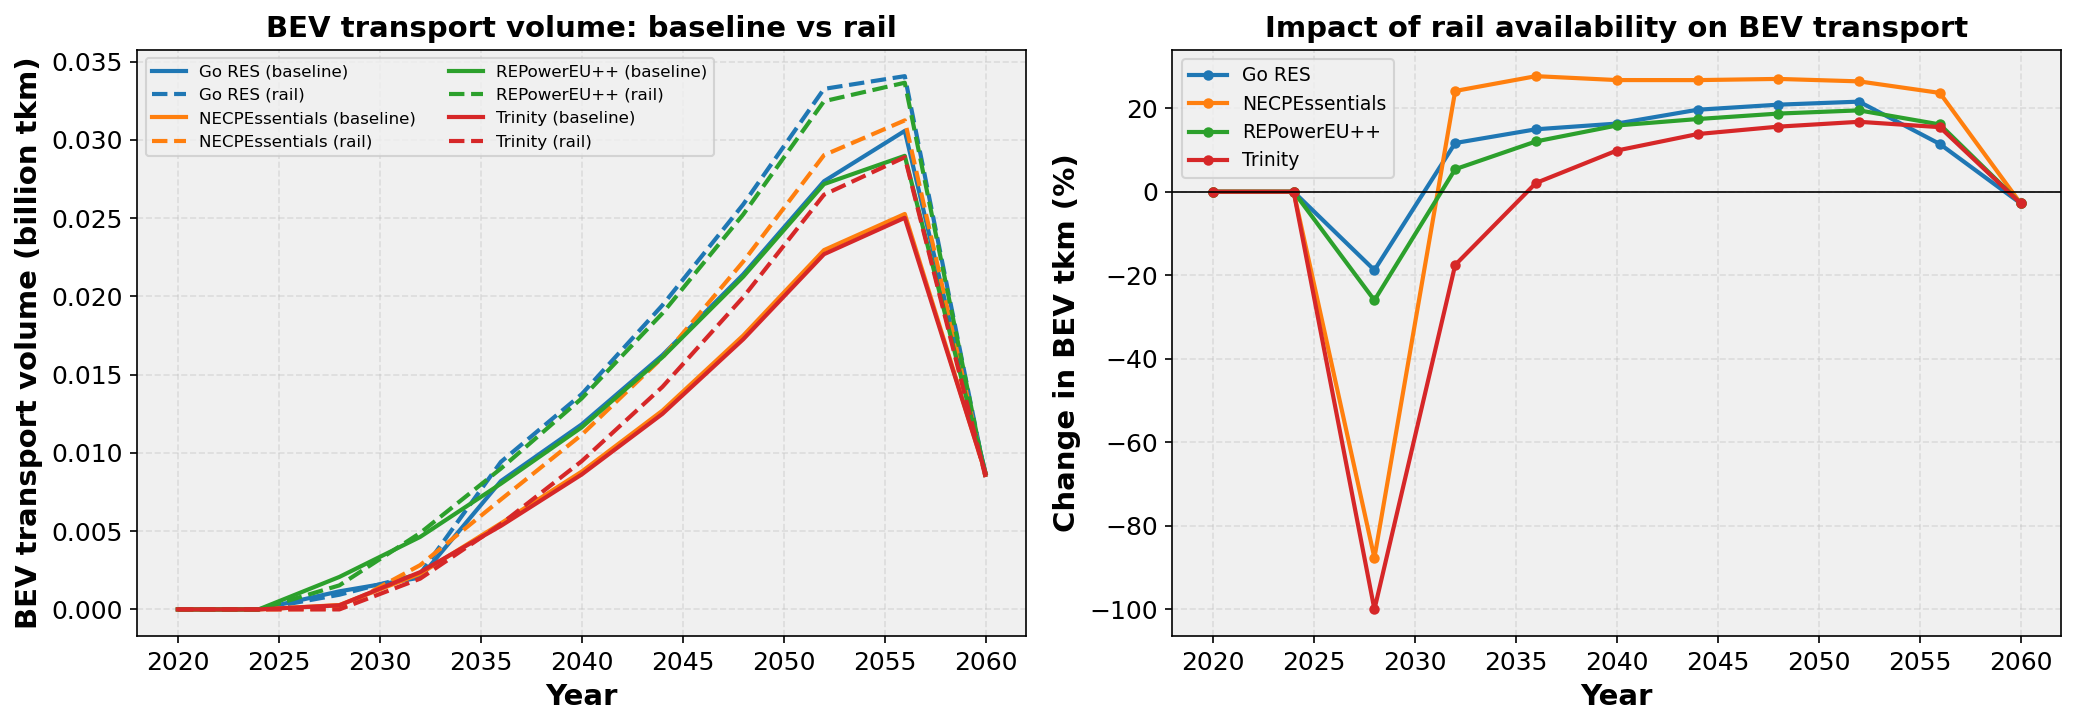

Saved: figures/bev_adoption_baseline_vs_rail.pdf


In [69]:
# ============================================================
# Figure 2: BEV adoption — baseline vs rail (all 4 scenarios)
# Shows how enabling rail changes BEV fleet trajectory
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: absolute BEV tkm
ax = axes[0]
for scen_name in SCENARIOS:
    color = SCENARIO_COLORS[scen_name]
    
    # Baseline
    base_vol = tkm_data[scen_name]['baseline']
    years_b = sorted([y for y in base_vol.keys() if y in MODEL_YEARS])
    bev_base = [base_vol[y]['road_bev'] / 1e9 for y in years_b]
    ax.plot(years_b, bev_base, color=color, linewidth=2, linestyle='-',
            label=f'{scen_name} (baseline)')
    
    # Rail
    rail_vol = tkm_data[scen_name]['rail']
    years_r = sorted([y for y in rail_vol.keys() if y in MODEL_YEARS])
    bev_rail = [rail_vol[y]['road_bev'] / 1e9 for y in years_r]
    ax.plot(years_r, bev_rail, color=color, linewidth=2, linestyle='--',
            label=f'{scen_name} (rail)')

ax.set_xlabel('Year', fontweight='bold')
ax.set_ylabel('BEV transport volume (billion tkm)', fontweight='bold')
ax.set_title('BEV transport volume: baseline vs rail', fontweight='bold')
ax.legend(fontsize=8, ncol=2, loc='upper left')
ax.grid(True, alpha=0.3, linestyle='--')

# Right panel: delta (rail - baseline) in %
ax = axes[1]
for scen_name in SCENARIOS:
    color = SCENARIO_COLORS[scen_name]
    base_vol = tkm_data[scen_name]['baseline']
    rail_vol = tkm_data[scen_name]['rail']
    years = sorted([y for y in base_vol.keys() if y in MODEL_YEARS and y in rail_vol])
    
    deltas = []
    for y in years:
        bev_b = base_vol[y]['road_bev']
        bev_r = rail_vol[y]['road_bev']
        if bev_b > 0:
            deltas.append((bev_r - bev_b) / bev_b * 100)
        else:
            deltas.append(0.0)
    
    ax.plot(years, deltas, color=color, linewidth=2, marker='o', markersize=4,
            label=scen_name)

ax.axhline(0, color='black', linewidth=0.8, linestyle='-')
ax.set_xlabel('Year', fontweight='bold')
ax.set_ylabel('Change in BEV tkm (%)', fontweight='bold')
ax.set_title('Impact of rail availability on BEV transport', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig(FIG_DIR / 'bev_adoption_baseline_vs_rail.pdf')
plt.savefig(FIG_DIR / 'bev_adoption_baseline_vs_rail.png')
plt.show()
print('Saved: figures/bev_adoption_baseline_vs_rail.pdf')

In [70]:
# ============================================================
# Helper: aggregate charging infrastructure by latitude
# ============================================================

# Year index mapping (model years to q_fuel_infr_plus year indices)
# q_fuel_infr_plus uses investment years; index mapping depends on model
# From the data: indices 1-14 for years 2020-2060 (4-year steps)
YEAR_TO_QIDX = {y: i+1 for i, y in enumerate(range(2020, 2065, 4))}
# But let's verify from actual data
sample_q = data['Go RES']['rail']['q_infr']
year_indices_seen = sorted(set(k[0] for k in sample_q.keys()))
print(f'Year indices in q_fuel_infr_plus: {year_indices_seen}')
print(f'Number of year indices: {len(year_indices_seen)}')

# Check geo indices
geo_indices_seen = sorted(set(k[2] for k in sample_q.keys()))
print(f'Geo element indices range: {min(geo_indices_seen)} - {max(geo_indices_seen)}')
print(f'Number of unique geo elements: {len(geo_indices_seen)}')

# Check fueling infr type indices  
fl_indices_seen = sorted(set(k[1] for k in sample_q.keys()))
print(f'Fueling infr type indices: {fl_indices_seen}')

Year indices in q_fuel_infr_plus: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Number of year indices: 11
Geo element indices range: 1 - 81
Number of unique geo elements: 73
Fueling infr type indices: [1, 3]


In [71]:
# ============================================================
# Build year-index mapping from actual data
# ============================================================
# The year indices in q_fuel_infr_plus correspond to investment years
# For 4-year timestep starting 2020: index 1->2020, 2->2024, ..., 11->2060
# But this might also be annual. Let's infer from the count.

n_year_idx = len(year_indices_seen)
if n_year_idx <= 12:  # 4-year timestep
    # Indices 1..11 for years 2020,2024,...,2060
    IDX_TO_YEAR = {i: 2020 + (i - min(year_indices_seen)) * 4 for i in year_indices_seen}
else:  # annual
    IDX_TO_YEAR = {i: 2020 + (i - min(year_indices_seen)) for i in year_indices_seen}

YEAR_TO_IDX = {v: k for k, v in IDX_TO_YEAR.items()}
print('Year index mapping:')
for idx in sorted(IDX_TO_YEAR.keys()):
    print(f'  index {idx} -> year {IDX_TO_YEAR[idx]}')

Year index mapping:
  index 1 -> year 2020
  index 2 -> year 2024
  index 3 -> year 2028
  index 4 -> year 2032
  index 5 -> year 2036
  index 6 -> year 2040
  index 7 -> year 2044
  index 8 -> year 2048
  index 9 -> year 2052
  index 10 -> year 2056
  index 11 -> year 2060


In [72]:
# ============================================================
# Calculate cumulative charging capacity by latitude
# ============================================================

def charging_capacity_by_latitude(q_infr, geo_by_id, target_year, year_to_idx, idx_to_year):
    """
    Calculate cumulative charging infrastructure capacity (kW) by geographic element,
    summed over all years up to target_year.
    
    Returns: list of (latitude, country, capacity_kw, geo_id)
    """
    target_idx = year_to_idx.get(target_year)
    if target_idx is None:
        print(f'Warning: year {target_year} not in index mapping')
        return []
    
    # Sum capacity by geo element (cumulative up to target year)
    capacity_by_geo = {}
    for (y_idx, fl_type, geo_id), cap_kw in q_infr.items():
        # Only BEV charging (fl_type 1=slow, 2=fast, 3=?) — include all electric
        if y_idx > target_idx:
            continue
        if geo_id not in capacity_by_geo:
            capacity_by_geo[geo_id] = 0.0
        capacity_by_geo[geo_id] += cap_kw
    
    # Map to latitude
    result = []
    for geo_id, cap in capacity_by_geo.items():
        geo = geo_by_id.get(geo_id)
        if geo is not None and cap > 0:
            result.append((
                geo['coordinate_lat'],
                geo.get('country', '??'),
                cap,
                geo_id
            ))
    
    return sorted(result, key=lambda x: x[0])


# Test
test_lat = charging_capacity_by_latitude(
    data['Go RES']['rail']['q_infr'],
    data['Go RES']['rail']['input']['geo_by_id'],
    2040, YEAR_TO_IDX, IDX_TO_YEAR
)
print(f'Go RES rail 2040: {len(test_lat)} locations with charging capacity')
total_kw = sum(x[2] for x in test_lat)
print(f'Total capacity: {total_kw:,.0f} kW = {total_kw/1000:,.0f} MW')

Go RES rail 2040: 72 locations with charging capacity
Total capacity: 2,738,275 kW = 2,738 MW


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

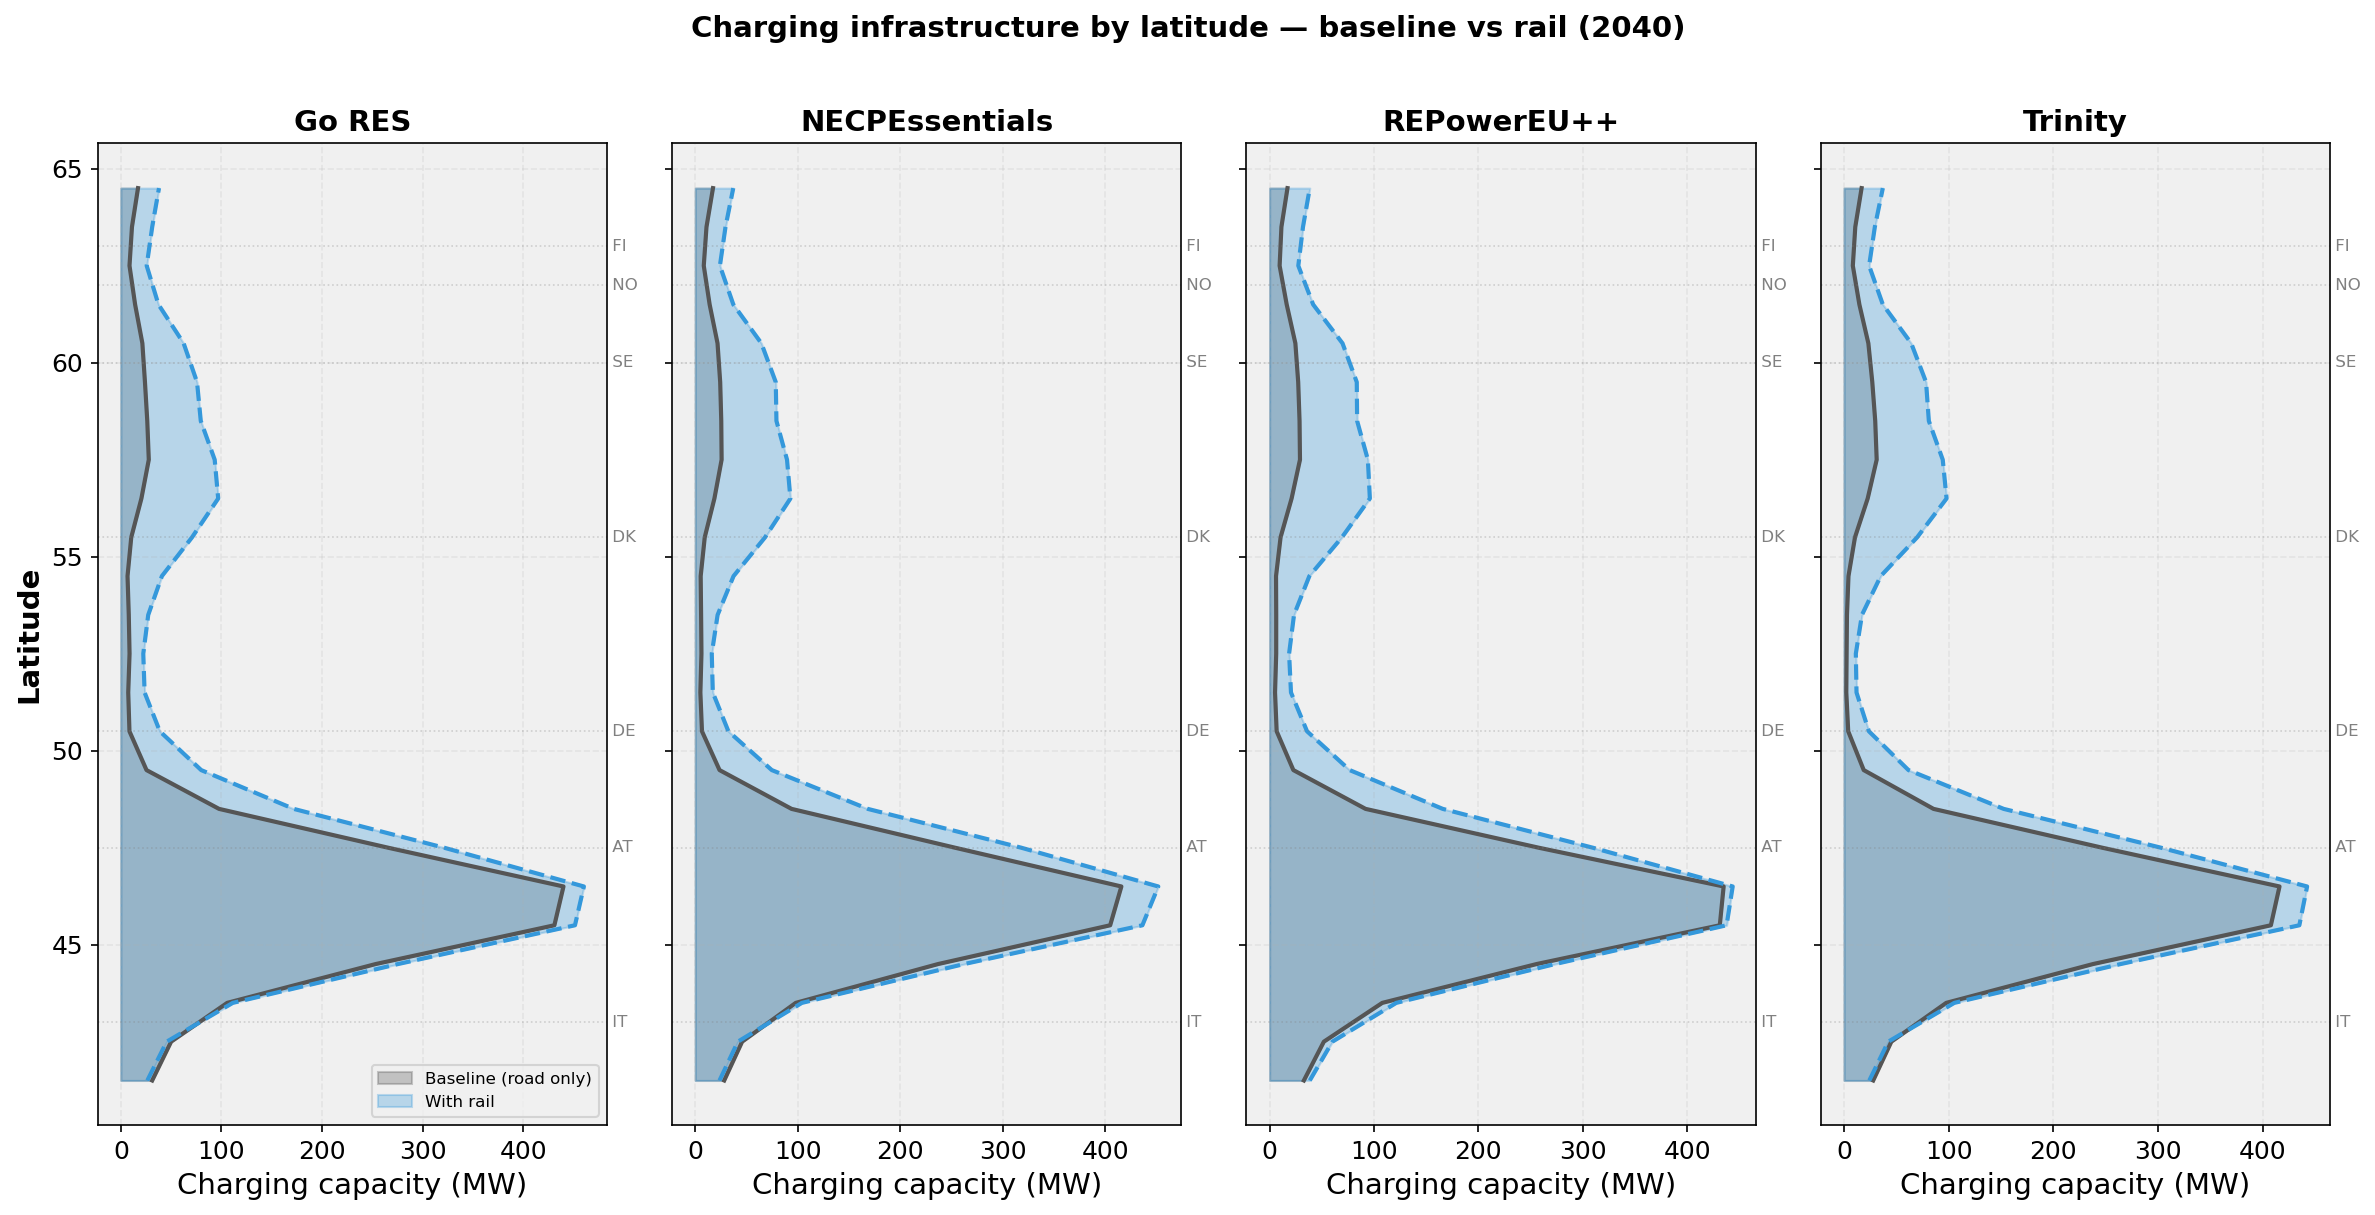

Saved: figures/charging_by_latitude_baseline_vs_rail_2040.pdf


In [73]:
# ============================================================
# Figure 3: Charging demand by latitude — baseline vs rail
# For all 4 scenarios, year 2040
# => For manuscript fig:modalshift_latitude
# ============================================================

TARGET_YEAR = 2040

# Country latitude bands (approximate centroids for corridor)
COUNTRY_LAT_CENTROIDS = {
    'IT': 43.0, 'AT': 47.5, 'DE': 50.5, 'DK': 55.5, 'SE': 60.0, 'NO': 62.0, 'FI': 63.0
}

fig, axes = plt.subplots(1, 4, figsize=(16, 8), sharey=True)

for idx, (scen_name, ax) in enumerate(zip(SCENARIOS.keys(), axes)):
    # Baseline
    base_lat = charging_capacity_by_latitude(
        data[scen_name]['baseline']['q_infr'],
        data[scen_name]['baseline']['input']['geo_by_id'],
        TARGET_YEAR, YEAR_TO_IDX, IDX_TO_YEAR
    )
    # Rail
    rail_lat = charging_capacity_by_latitude(
        data[scen_name]['rail']['q_infr'],
        data[scen_name]['rail']['input']['geo_by_id'],
        TARGET_YEAR, YEAR_TO_IDX, IDX_TO_YEAR
    )
    
    # Bin by latitude (1-degree bins)
    lat_min, lat_max = 41, 65
    bins = np.arange(lat_min, lat_max + 1, 1)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    
    base_binned = np.zeros(len(bin_centers))
    rail_binned = np.zeros(len(bin_centers))
    
    for lat, country, cap, gid in base_lat:
        bi = np.searchsorted(bins, lat) - 1
        if 0 <= bi < len(bin_centers):
            base_binned[bi] += cap
    
    for lat, country, cap, gid in rail_lat:
        bi = np.searchsorted(bins, lat) - 1
        if 0 <= bi < len(bin_centers):
            rail_binned[bi] += cap
    
    # Convert to MW
    base_mw = base_binned / 1000
    rail_mw = rail_binned / 1000
    
    # Smooth
    if len(base_mw) > 3:
        base_smooth = gaussian_filter1d(base_mw, sigma=1.2)
        rail_smooth = gaussian_filter1d(rail_mw, sigma=1.2)
    else:
        base_smooth = base_mw
        rail_smooth = rail_mw
    
    # Plot
    ax.fill_betweenx(bin_centers, 0, base_smooth, alpha=0.3, color=COLOR_BASELINE,
                     label='Baseline (road only)')
    ax.plot(base_smooth, bin_centers, color=COLOR_BASELINE, linewidth=2, linestyle='-')
    
    ax.fill_betweenx(bin_centers, 0, rail_smooth, alpha=0.3, color=COLOR_RAIL,
                     label='With rail')
    ax.plot(rail_smooth, bin_centers, color=COLOR_RAIL, linewidth=2, linestyle='--')
    
    # Country labels
    for country, clat in COUNTRY_LAT_CENTROIDS.items():
        ax.axhline(clat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
        ax.text(ax.get_xlim()[1] if ax.get_xlim()[1] > 0 else 1, clat, f' {country}',
                va='center', fontsize=8, color='gray')
    
    ax.set_title(scen_name, fontweight='bold')
    ax.set_xlabel('Charging capacity (MW)')
    if idx == 0:
        ax.set_ylabel('Latitude', fontweight='bold')
        ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.2, linestyle='--')

fig.suptitle(f'Charging infrastructure by latitude — baseline vs rail ({TARGET_YEAR})',
             fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / f'charging_by_latitude_baseline_vs_rail_{TARGET_YEAR}.pdf')
plt.savefig(FIG_DIR / f'charging_by_latitude_baseline_vs_rail_{TARGET_YEAR}.png')
plt.show()
print(f'Saved: figures/charging_by_latitude_baseline_vs_rail_{TARGET_YEAR}.pdf')

In [74]:
# ============================================================
# Calculate rail transport allocation by latitude
# (Where is rail shift happening geographically?)
# ============================================================

def rail_tkm_by_origin_latitude(f_dict, input_data, target_year=None):
    """
    Calculate rail TKM attributed to the origin latitude of each OD pair.
    
    Returns: DataFrame with columns [year, latitude, country, rail_tkm, road_tkm]
    """
    geo_by_id = input_data['geo_by_id']
    path_by_id = input_data['path_by_id']
    odpair_by_id = input_data['odpair_by_id']
    
    rows = []
    for key, tonnes in f_dict.items():
        year = key[0]
        if target_year is not None and year != target_year:
            continue
        
        odpair_id = key[1][1]
        path_id = key[1][2]
        mode_id = key[2][0]
        tv_id = key[2][1]
        
        # Get origin geo element
        odpair = odpair_by_id.get(odpair_id)
        if odpair is None:
            continue
        origin_geo_id = odpair['from']
        dest_geo_id = odpair['to']
        
        origin_geo = geo_by_id.get(origin_geo_id)
        dest_geo = geo_by_id.get(dest_geo_id)
        if origin_geo is None or dest_geo is None:
            continue
        
        # Use midpoint latitude for geographic attribution
        midpoint_lat = (origin_geo['coordinate_lat'] + dest_geo['coordinate_lat']) / 2
        origin_country = origin_geo.get('country', '??')
        dest_country = dest_geo.get('country', '??')
        
        # Get path length for tkm
        path_info = path_by_id.get(path_id)
        if path_info is None:
            continue
        tkm = tonnes * path_info['length']
        
        cat = 'rail' if mode_id == 2 else 'road'
        rows.append({
            'year': year,
            'midpoint_lat': midpoint_lat,
            'origin_country': origin_country,
            'dest_country': dest_country,
            'country_pair': f'{origin_country}-{dest_country}',
            'mode': cat,
            'tkm': tkm,
        })
    
    return pd.DataFrame(rows)


# Compute for all scenarios (rail runs only)
rail_lat_dfs = {}
for scen_name in SCENARIOS:
    print(f'Computing rail latitude data for {scen_name}...')
    rail_lat_dfs[scen_name] = rail_tkm_by_origin_latitude(
        data[scen_name]['rail']['f'],
        data[scen_name]['rail']['input']
    )
    n_rail = len(rail_lat_dfs[scen_name][rail_lat_dfs[scen_name]['mode'] == 'rail'])
    print(f'  {len(rail_lat_dfs[scen_name])} total entries, {n_rail} rail entries')

print('Done.')

Computing rail latitude data for Go RES...
  60115 total entries, 1912 rail entries
Computing rail latitude data for NECPEssentials...
  60695 total entries, 2022 rail entries
Computing rail latitude data for REPowerEU++...
  60610 total entries, 1986 rail entries
Computing rail latitude data for Trinity...
  60957 total entries, 2035 rail entries
Done.


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

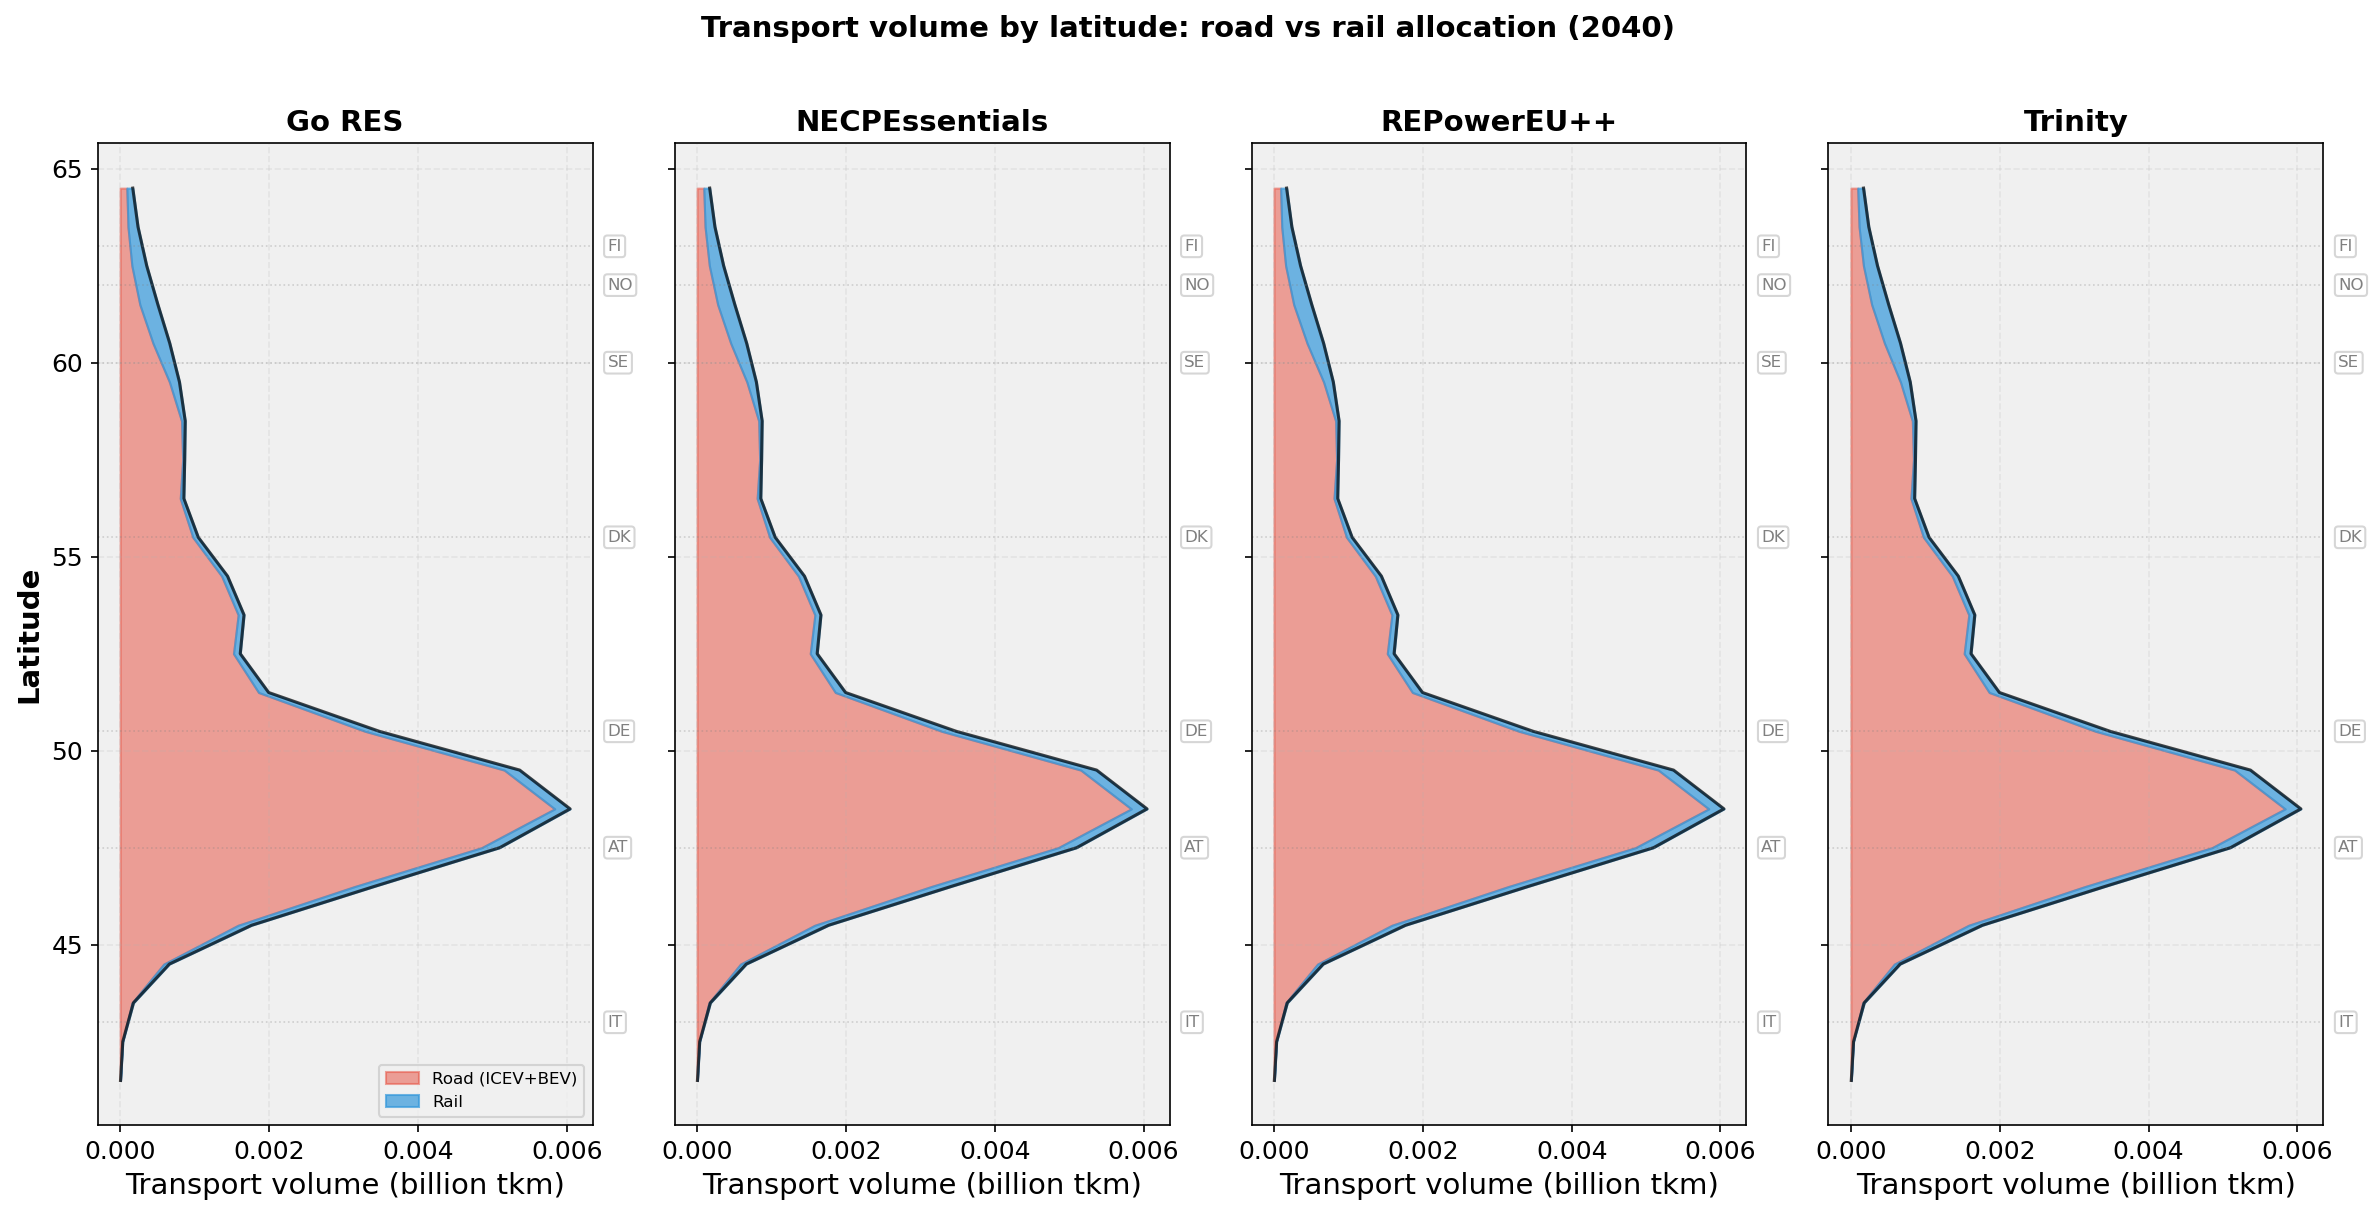

Saved: figures/rail_allocation_by_latitude_2040.pdf


In [75]:
# ============================================================
# Figure 4: Rail TKM allocation by latitude
# Shows WHERE rail shift is happening geographically
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(16, 8), sharey=True)

for idx, (scen_name, ax) in enumerate(zip(SCENARIOS.keys(), axes)):
    df = rail_lat_dfs[scen_name]
    df_year = df[df['year'] == TARGET_YEAR].copy()
    
    if len(df_year) == 0:
        ax.set_title(f'{scen_name}\n(no data for {TARGET_YEAR})', fontweight='bold')
        continue
    
    # Bin by latitude
    lat_min, lat_max = 41, 65
    bins = np.arange(lat_min, lat_max + 1, 1)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    
    rail_binned = np.zeros(len(bin_centers))
    road_binned = np.zeros(len(bin_centers))
    
    for _, row in df_year.iterrows():
        bi = np.searchsorted(bins, row['midpoint_lat']) - 1
        if 0 <= bi < len(bin_centers):
            if row['mode'] == 'rail':
                rail_binned[bi] += row['tkm']
            else:
                road_binned[bi] += row['tkm']
    
    # Convert to billion tkm
    rail_btkm = rail_binned / 1e9
    road_btkm = road_binned / 1e9
    
    # Smooth
    rail_smooth = gaussian_filter1d(rail_btkm, sigma=1.2)
    road_smooth = gaussian_filter1d(road_btkm, sigma=1.2)
    
    # Stacked horizontal: road (bottom) + rail (on top)
    ax.fill_betweenx(bin_centers, 0, road_smooth, alpha=0.5, color=COLOR_ICEV,
                     label='Road (ICEV+BEV)')
    ax.fill_betweenx(bin_centers, road_smooth, road_smooth + rail_smooth,
                     alpha=0.7, color=COLOR_RAIL, label='Rail')
    ax.plot(road_smooth + rail_smooth, bin_centers, color='black', linewidth=1.5, alpha=0.7)
    
    # Country labels
    for country, clat in COUNTRY_LAT_CENTROIDS.items():
        ax.axhline(clat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
    
    # Add country code labels on right
    x_max = ax.get_xlim()[1] if ax.get_xlim()[1] > 0 else 1
    for country, clat in COUNTRY_LAT_CENTROIDS.items():
        ax.text(1.03, clat, country, transform=ax.get_yaxis_transform(),
                va='center', fontsize=8, color='gray',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          edgecolor='#ccc', alpha=0.8))
    
    ax.set_title(scen_name, fontweight='bold')
    ax.set_xlabel('Transport volume (billion tkm)')
    if idx == 0:
        ax.set_ylabel('Latitude', fontweight='bold')
        ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.2, linestyle='--')

fig.suptitle(f'Transport volume by latitude: road vs rail allocation ({TARGET_YEAR})',
             fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / f'rail_allocation_by_latitude_{TARGET_YEAR}.pdf')
plt.savefig(FIG_DIR / f'rail_allocation_by_latitude_{TARGET_YEAR}.png')
plt.show()
print(f'Saved: figures/rail_allocation_by_latitude_{TARGET_YEAR}.pdf')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

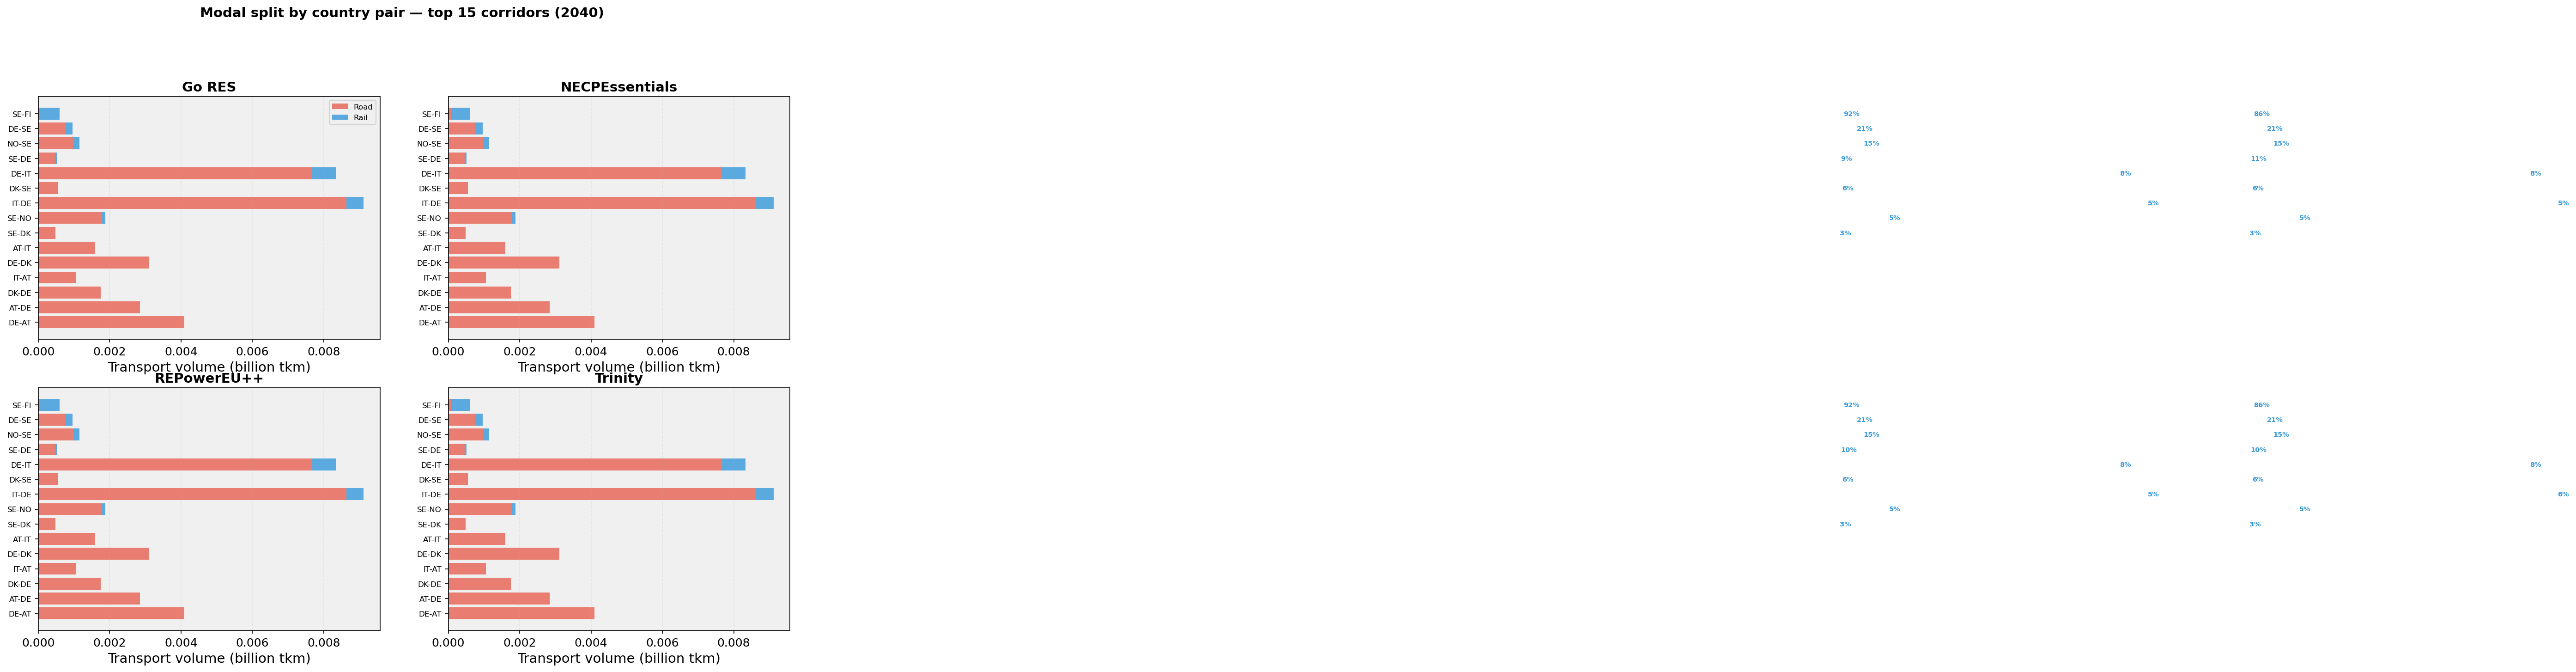

Saved: figures/rail_share_by_country_pair_2040.pdf


In [76]:
# ============================================================
# Figure 5: Rail share by country pair
# Which OD country pairs shift most to rail?
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes_flat = axes.flatten()

for idx, (scen_name, ax) in enumerate(zip(SCENARIOS.keys(), axes_flat)):
    df = rail_lat_dfs[scen_name]
    df_year = df[df['year'] == TARGET_YEAR].copy()
    
    if len(df_year) == 0:
        continue
    
    # Aggregate by country pair and mode
    agg = df_year.groupby(['country_pair', 'mode'])['tkm'].sum().reset_index()
    pivot = agg.pivot_table(index='country_pair', columns='mode', values='tkm', fill_value=0)
    
    if 'rail' not in pivot.columns:
        pivot['rail'] = 0
    if 'road' not in pivot.columns:
        pivot['road'] = 0
    
    pivot['total'] = pivot['rail'] + pivot['road']
    pivot['rail_pct'] = pivot['rail'] / pivot['total'] * 100
    
    # Top 15 by total volume
    top = pivot.nlargest(15, 'total').sort_values('rail_pct', ascending=True)
    
    # Horizontal bar chart
    y_pos = range(len(top))
    ax.barh(y_pos, top['road'] / 1e9, color=COLOR_ICEV, alpha=0.7, label='Road')
    ax.barh(y_pos, top['rail'] / 1e9, left=top['road'] / 1e9, color=COLOR_RAIL,
            alpha=0.8, label='Rail')
    
    # Add rail % labels
    for yi, (cp, row) in enumerate(top.iterrows()):
        if row['rail_pct'] > 1:
            ax.text(row['total'] / 1e9 + 0.05, yi, f"{row['rail_pct']:.0f}%",
                    va='center', fontsize=7, color=COLOR_RAIL, fontweight='bold')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(top.index, fontsize=8)
    ax.set_xlabel('Transport volume (billion tkm)')
    ax.set_title(scen_name, fontweight='bold')
    if idx == 0:
        ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2, linestyle='--', axis='x')

fig.suptitle(f'Modal split by country pair — top 15 corridors ({TARGET_YEAR})',
             fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / f'rail_share_by_country_pair_{TARGET_YEAR}.pdf')
plt.savefig(FIG_DIR / f'rail_share_by_country_pair_{TARGET_YEAR}.png')
plt.show()
print(f'Saved: figures/rail_share_by_country_pair_{TARGET_YEAR}.pdf')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

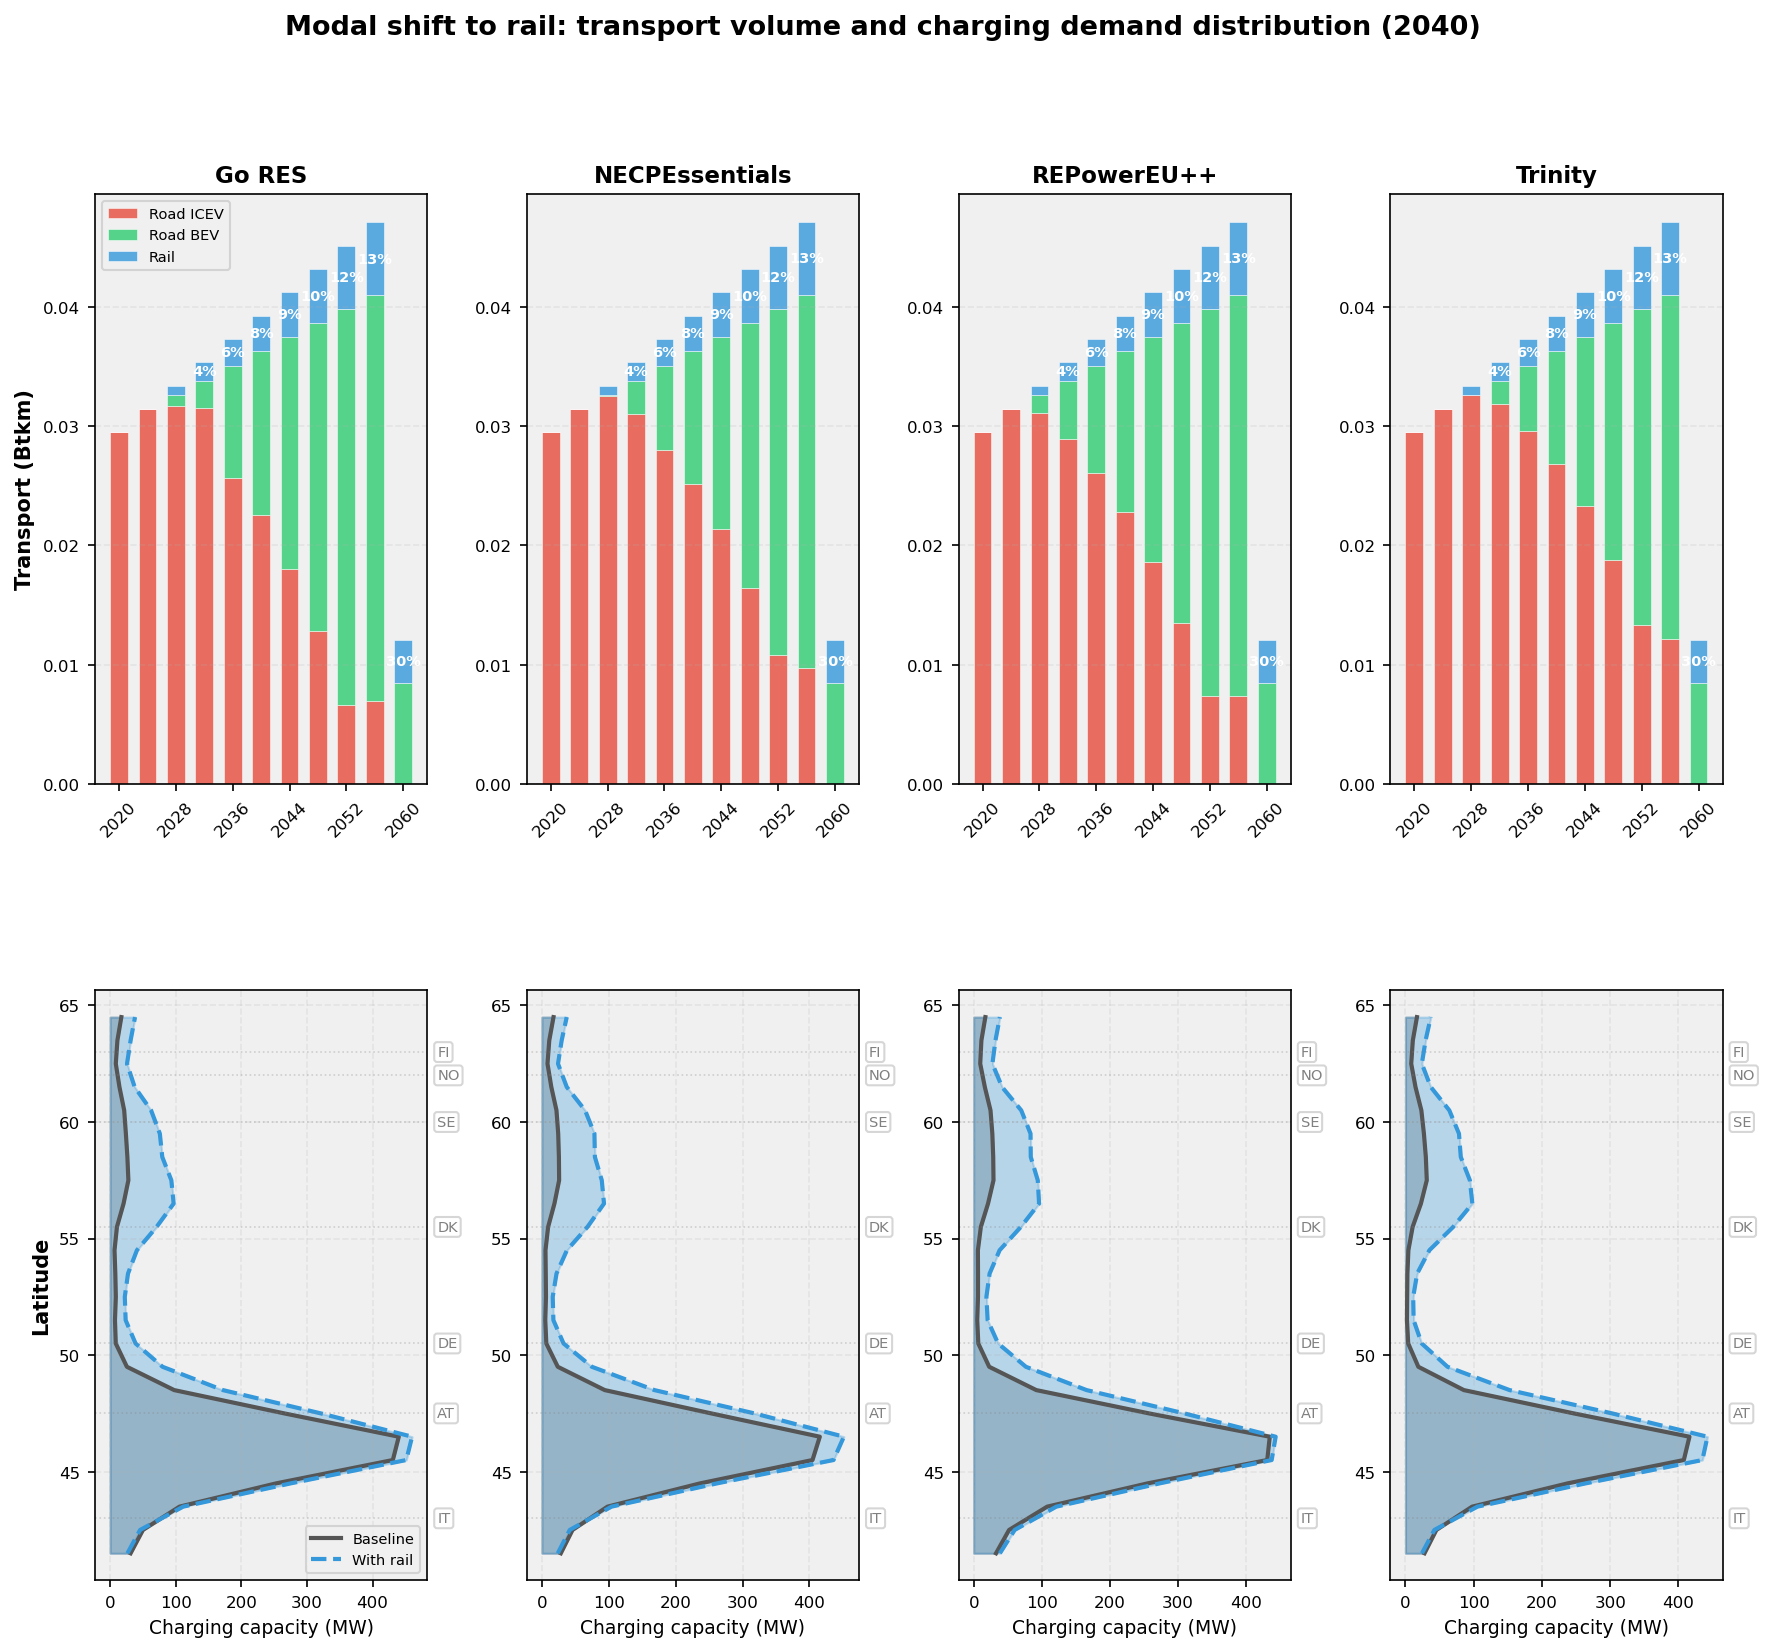

Saved: figures/modal_shift_combined_4scenarios_2040.pdf


In [77]:
# ============================================================
# Figure 6: Combined manuscript figure — modal shift overview
# Top: stacked bars (all 4 scenarios, Go RES highlighted)
# Bottom: latitude comparison (baseline vs rail)
# ============================================================

fig = plt.figure(figsize=(14, 12))
gs = fig.add_gridspec(2, 4, hspace=0.35, wspace=0.3)

# --- Top row: modal split for each scenario ---
for col, scen_name in enumerate(SCENARIOS.keys()):
    ax = fig.add_subplot(gs[0, col])
    vol = tkm_data[scen_name]['rail']
    years = sorted([y for y in vol.keys() if y in MODEL_YEARS])
    
    rail_vals = [vol[y]['rail'] / 1e9 for y in years]
    icev_vals = [vol[y]['road_icev'] / 1e9 for y in years]
    bev_vals  = [vol[y]['road_bev'] / 1e9 for y in years]
    
    bar_w = 2.5
    ax.bar(years, icev_vals, width=bar_w, color=COLOR_ICEV, alpha=0.8,
           label='Road ICEV', edgecolor='white', linewidth=0.3)
    ax.bar(years, bev_vals, width=bar_w, bottom=icev_vals, color=COLOR_BEV, alpha=0.8,
           label='Road BEV', edgecolor='white', linewidth=0.3)
    bottom_r = [i + b for i, b in zip(icev_vals, bev_vals)]
    ax.bar(years, rail_vals, width=bar_w, bottom=bottom_r, color=COLOR_RAIL, alpha=0.8,
           label='Rail', edgecolor='white', linewidth=0.3)
    
    # Rail % labels
    for yi, y in enumerate(years):
        total = icev_vals[yi] + bev_vals[yi] + rail_vals[yi]
        if total > 0 and rail_vals[yi] / total > 0.03:
            ax.text(y, bottom_r[yi] + rail_vals[yi]/2, f'{rail_vals[yi]/total*100:.0f}%',
                    ha='center', va='center', fontsize=7, fontweight='bold', color='white')
    
    ax.set_title(scen_name, fontweight='bold', fontsize=11)
    ax.set_xticks(years[::2])
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    if col == 0:
        ax.set_ylabel('Transport (Btkm)', fontweight='bold', fontsize=10)
        ax.legend(fontsize=7, loc='upper left')
    ax.grid(True, alpha=0.2, linestyle='--', axis='y')

# --- Bottom row: latitude comparison ---
for col, scen_name in enumerate(SCENARIOS.keys()):
    ax = fig.add_subplot(gs[1, col])
    
    base_lat = charging_capacity_by_latitude(
        data[scen_name]['baseline']['q_infr'],
        data[scen_name]['baseline']['input']['geo_by_id'],
        TARGET_YEAR, YEAR_TO_IDX, IDX_TO_YEAR
    )
    rail_lat = charging_capacity_by_latitude(
        data[scen_name]['rail']['q_infr'],
        data[scen_name]['rail']['input']['geo_by_id'],
        TARGET_YEAR, YEAR_TO_IDX, IDX_TO_YEAR
    )
    
    lat_min, lat_max = 41, 65
    bins = np.arange(lat_min, lat_max + 1, 1)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    
    base_binned = np.zeros(len(bin_centers))
    rail_binned = np.zeros(len(bin_centers))
    
    for lat, c, cap, gid in base_lat:
        bi = np.searchsorted(bins, lat) - 1
        if 0 <= bi < len(bin_centers):
            base_binned[bi] += cap
    for lat, c, cap, gid in rail_lat:
        bi = np.searchsorted(bins, lat) - 1
        if 0 <= bi < len(bin_centers):
            rail_binned[bi] += cap
    
    base_mw = gaussian_filter1d(base_binned / 1000, sigma=1.2)
    rail_mw = gaussian_filter1d(rail_binned / 1000, sigma=1.2)
    
    ax.fill_betweenx(bin_centers, 0, base_mw, alpha=0.3, color=COLOR_BASELINE)
    ax.plot(base_mw, bin_centers, color=COLOR_BASELINE, linewidth=2, label='Baseline')
    ax.fill_betweenx(bin_centers, 0, rail_mw, alpha=0.3, color=COLOR_RAIL)
    ax.plot(rail_mw, bin_centers, color=COLOR_RAIL, linewidth=2, linestyle='--', label='With rail')
    
    for country, clat in COUNTRY_LAT_CENTROIDS.items():
        ax.axhline(clat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
        ax.text(1.03, clat, country, transform=ax.get_yaxis_transform(),
                va='center', fontsize=7, color='gray',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          edgecolor='#ccc', alpha=0.8))
    
    ax.set_xlabel('Charging capacity (MW)', fontsize=9)
    ax.tick_params(labelsize=8)
    if col == 0:
        ax.set_ylabel('Latitude', fontweight='bold', fontsize=10)
        ax.legend(fontsize=7, loc='lower right')
    ax.grid(True, alpha=0.2, linestyle='--')

fig.suptitle(f'Modal shift to rail: transport volume and charging demand distribution ({TARGET_YEAR})',
             fontweight='bold', fontsize=13)
plt.savefig(FIG_DIR / f'modal_shift_combined_4scenarios_{TARGET_YEAR}.pdf')
plt.savefig(FIG_DIR / f'modal_shift_combined_4scenarios_{TARGET_YEAR}.png')
plt.show()
print(f'Saved: figures/modal_shift_combined_4scenarios_{TARGET_YEAR}.pdf')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

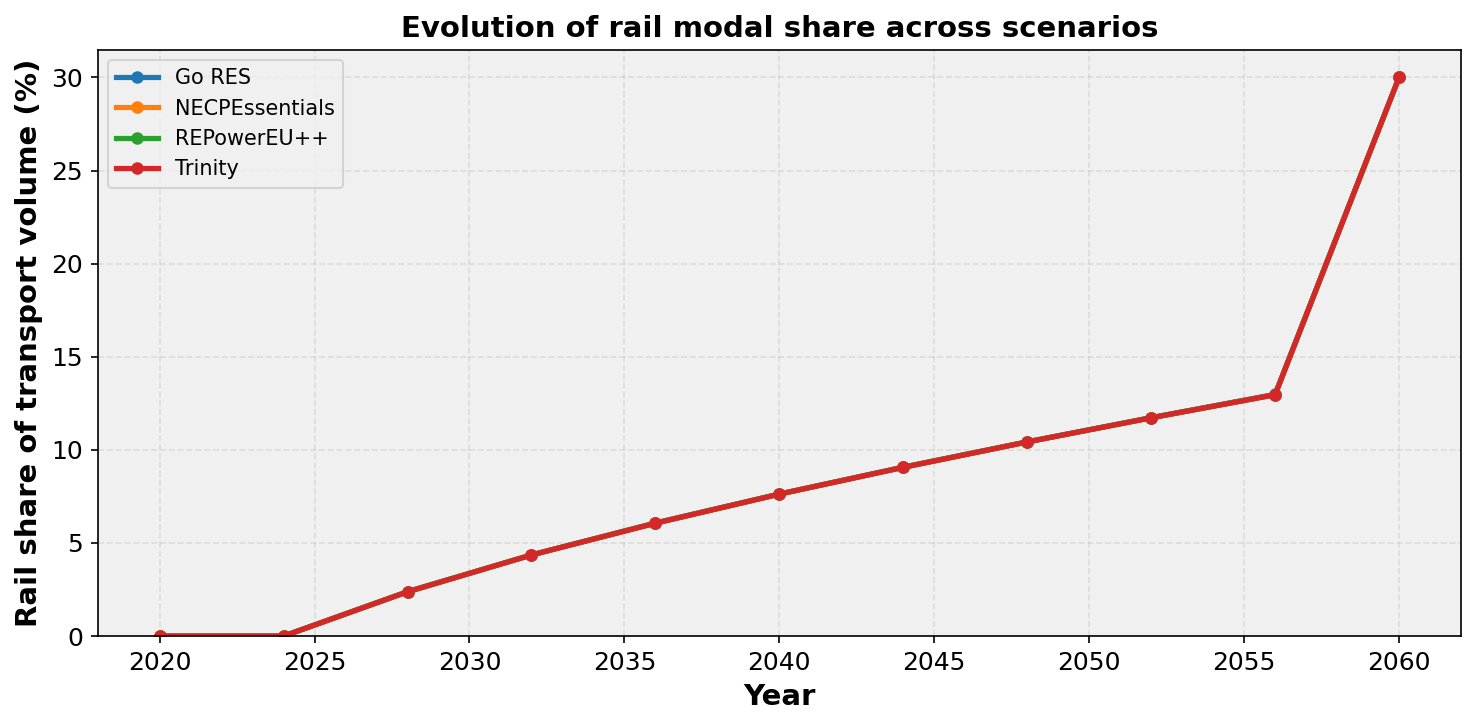

Saved: figures/rail_share_evolution_4scenarios.pdf


In [78]:
# ============================================================
# Figure 7: Rail share evolution over time (all 4 scenarios)
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))

for scen_name in SCENARIOS:
    color = SCENARIO_COLORS[scen_name]
    vol = tkm_data[scen_name]['rail']
    years = sorted([y for y in vol.keys() if y in MODEL_YEARS])
    
    rail_pct = []
    for y in years:
        total = sum(vol[y].values())
        rail_pct.append(vol[y]['rail'] / total * 100 if total > 0 else 0)
    
    ax.plot(years, rail_pct, color=color, linewidth=2.5, marker='o', markersize=5,
            label=scen_name)

ax.set_xlabel('Year', fontweight='bold')
ax.set_ylabel('Rail share of transport volume (%)', fontweight='bold')
ax.set_title('Evolution of rail modal share across scenarios', fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig(FIG_DIR / 'rail_share_evolution_4scenarios.pdf')
plt.savefig(FIG_DIR / 'rail_share_evolution_4scenarios.png')
plt.show()
print('Saved: figures/rail_share_evolution_4scenarios.pdf')

In [79]:
# ============================================================
# Summary statistics table
# ============================================================

print('=' * 100)
print(f'SUMMARY: Modal Shift Analysis — Year {TARGET_YEAR}')
print('=' * 100)

# Load objective values from summary_stats
print(f"\n{'Scenario':<18} {'Obj. baseline':>16} {'Obj. rail':>16} {'Delta':>14} {'Rel.':>8}")
print('-' * 80)

for scen_name, cfg in SCENARIOS.items():
    # Load summary stats
    base_stats = load_yaml(cfg['baseline_dir'] / 'summary_stats.yaml')
    rail_stats = load_yaml(cfg['rail_dir'] / 'summary_stats.yaml')
    
    # Cast to float — Julia YAML writer stores scientific notation as strings
    obj_b = float(base_stats['objective_value'])
    obj_r = float(rail_stats['objective_value'])
    delta = obj_r - obj_b
    rel = delta / obj_b * 100
    
    print(f'{scen_name:<18} {obj_b:>16.4e} {obj_r:>16.4e} {delta:>+14.4e} {rel:>+7.3f}%')

# Transport volume comparison
print(f"\n\n{'Scenario':<18} {'Baseline Btkm':>14} {'Rail Btkm':>14} {'Rail share':>12} "
      f"{'BEV road base':>14} {'BEV road rail':>14} {'BEV delta':>10}")
print('-' * 100)

for scen_name in SCENARIOS:
    b = tkm_data[scen_name]['baseline'].get(TARGET_YEAR, {})
    r = tkm_data[scen_name]['rail'].get(TARGET_YEAR, {})
    
    total_b = sum(b.values()) / 1e9 if b else 0
    total_r = sum(r.values()) / 1e9 if r else 0
    rail_tkm = r.get('rail', 0) / 1e9 if r else 0
    rail_pct = rail_tkm / total_r * 100 if total_r > 0 else 0
    bev_b = b.get('road_bev', 0) / 1e9 if b else 0
    bev_r = r.get('road_bev', 0) / 1e9 if r else 0
    bev_delta = (bev_r - bev_b) / bev_b * 100 if bev_b > 0 else 0
    
    print(f'{scen_name:<18} {total_b:>14.2f} {total_r:>14.2f} {rail_pct:>11.1f}% '
          f'{bev_b:>14.2f} {bev_r:>14.2f} {bev_delta:>+9.1f}%')

SUMMARY: Modal Shift Analysis — Year 2040

Scenario              Obj. baseline        Obj. rail          Delta     Rel.
--------------------------------------------------------------------------------
Go RES                   2.3683e+11       3.1632e+11    +7.9490e+10 +33.564%
NECPEssentials           2.3576e+11       3.1490e+11    +7.9143e+10 +33.569%
REPowerEU++              2.3652e+11       3.1592e+11    +7.9406e+10 +33.573%
Trinity                  2.3537e+11       3.1443e+11    +7.9059e+10 +33.589%


Scenario            Baseline Btkm      Rail Btkm   Rail share  BEV road base  BEV road rail  BEV delta
----------------------------------------------------------------------------------------------------
Go RES                       0.03           0.04         7.6%           0.01           0.01     +16.3%
NECPEssentials               0.03           0.04         7.6%           0.01           0.01     +26.7%
REPowerEU++                  0.03           0.04         7.6%           0.01   

In [80]:
# ============================================================
# Table: Where does rail shift happen? Top country pairs
# ============================================================

for scen_name in SCENARIOS:
    df = rail_lat_dfs[scen_name]
    df_year = df[(df['year'] == TARGET_YEAR) & (df['mode'] == 'rail')]
    
    if len(df_year) == 0:
        print(f'\n{scen_name}: no rail flows in {TARGET_YEAR}')
        continue
    
    by_pair = df_year.groupby('country_pair')['tkm'].sum().sort_values(ascending=False)
    total_rail = by_pair.sum()
    
    print(f'\n=== {scen_name} — Rail TKM by country pair ({TARGET_YEAR}) ===')
    print(f'{"Country pair":<15} {"Rail Btkm":>12} {"Share":>8}')
    print('-' * 40)
    for cp, tkm in by_pair.head(10).items():
        pct = tkm / total_rail * 100
        print(f'{cp:<15} {tkm/1e9:>12.3f} {pct:>7.1f}%')
    print(f'{"TOTAL":<15} {total_rail/1e9:>12.3f}')


=== Go RES — Rail TKM by country pair (2040) ===
Country pair       Rail Btkm    Share
----------------------------------------
DE-IT                  0.001    22.1%
SE-FI                  0.001    18.3%
IT-DE                  0.000    16.1%
DE-SE                  0.000     6.6%
IT-DK                  0.000     6.6%
NO-SE                  0.000     5.9%
DK-IT                  0.000     4.0%
FI-SE                  0.000     3.8%
DE-NO                  0.000     3.5%
SE-NO                  0.000     3.1%
TOTAL                  0.003

=== NECPEssentials — Rail TKM by country pair (2040) ===
Country pair       Rail Btkm    Share
----------------------------------------
DE-IT                  0.001    22.6%
SE-FI                  0.001    17.2%
IT-DE                  0.000    16.7%
DE-SE                  0.000     6.8%
IT-DK                  0.000     6.6%
NO-SE                  0.000     5.9%
DK-IT                  0.000     4.0%
FI-SE                  0.000     3.8%
DE-NO                

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

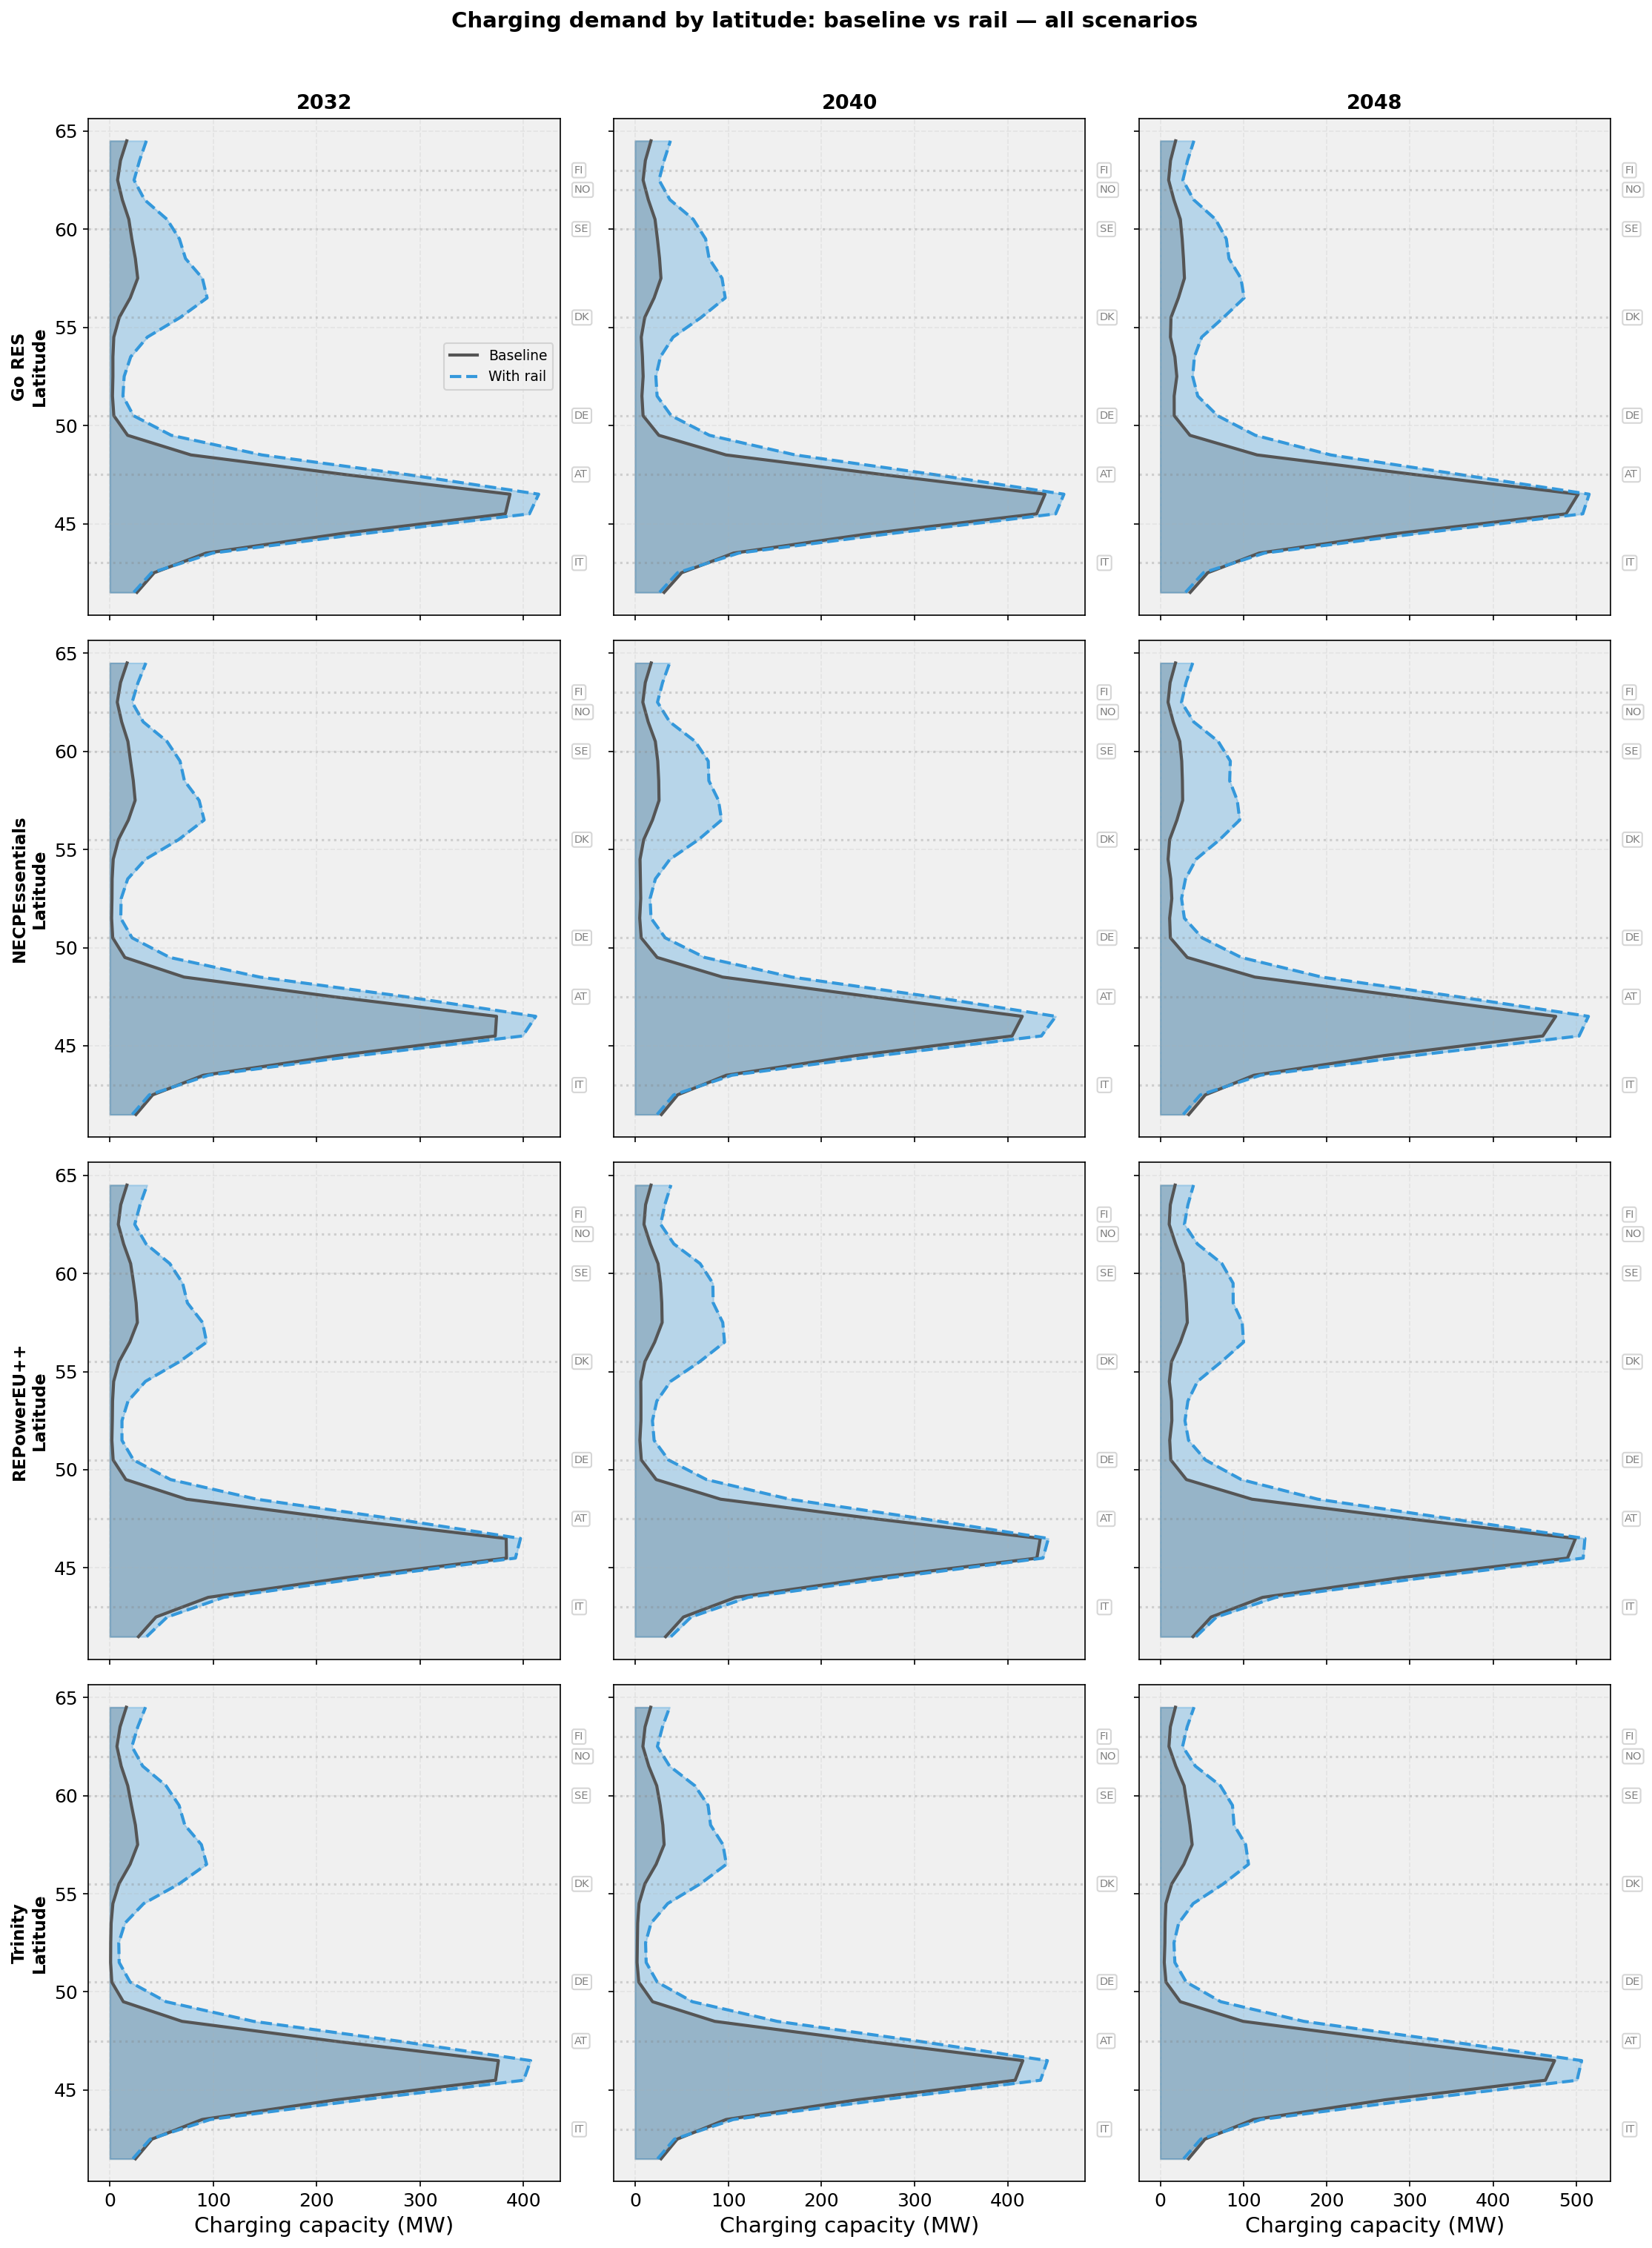

Saved: figures/charging_latitude_baseline_vs_rail_multi_year_all_scenarios.pdf


In [81]:
# ============================================================
# Figure 8: Charging by latitude — multi-year, ALL scenarios
# Shows evolution of baseline vs rail over time for each scenario
# Grid: 4 scenarios (rows) × 3 years (columns)
# ============================================================

PLOT_YEARS = [2032, 2040, 2048]
scenario_names = list(SCENARIOS.keys())
n_scenarios = len(scenario_names)

fig, axes = plt.subplots(n_scenarios, len(PLOT_YEARS),
                         figsize=(5*len(PLOT_YEARS), 5*n_scenarios),
                         sharey=True, sharex='col')

for si, scen_name in enumerate(scenario_names):
    for yi, year in enumerate(PLOT_YEARS):
        ax = axes[si, yi]

        base_lat = charging_capacity_by_latitude(
            data[scen_name]['baseline']['q_infr'],
            data[scen_name]['baseline']['input']['geo_by_id'],
            year, YEAR_TO_IDX, IDX_TO_YEAR
        )
        rail_lat = charging_capacity_by_latitude(
            data[scen_name]['rail']['q_infr'],
            data[scen_name]['rail']['input']['geo_by_id'],
            year, YEAR_TO_IDX, IDX_TO_YEAR
        )

        lat_min, lat_max = 41, 65
        bins = np.arange(lat_min, lat_max + 1, 1)
        bin_centers = (bins[:-1] + bins[1:]) / 2

        base_binned = np.zeros(len(bin_centers))
        rail_binned = np.zeros(len(bin_centers))

        for lat, c, cap, gid in base_lat:
            bi = np.searchsorted(bins, lat) - 1
            if 0 <= bi < len(bin_centers):
                base_binned[bi] += cap
        for lat, c, cap, gid in rail_lat:
            bi = np.searchsorted(bins, lat) - 1
            if 0 <= bi < len(bin_centers):
                rail_binned[bi] += cap

        base_mw = gaussian_filter1d(base_binned / 1000, sigma=1.2)
        rail_mw = gaussian_filter1d(rail_binned / 1000, sigma=1.2)

        ax.fill_betweenx(bin_centers, 0, base_mw, alpha=0.3, color=COLOR_BASELINE)
        ax.plot(base_mw, bin_centers, color=COLOR_BASELINE, linewidth=2, label='Baseline')
        ax.fill_betweenx(bin_centers, 0, rail_mw, alpha=0.3, color=COLOR_RAIL)
        ax.plot(rail_mw, bin_centers, color=COLOR_RAIL, linewidth=2, linestyle='--', label='With rail')

        for country, clat in COUNTRY_LAT_CENTROIDS.items():
            ax.axhline(clat, color='gray', linestyle=':', alpha=0.3)
            ax.text(1.03, clat, country, transform=ax.get_yaxis_transform(),
                    va='center', fontsize=7, color='gray',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                              edgecolor='#ccc', alpha=0.8))

        # Column title (year) on top row only
        if si == 0:
            ax.set_title(f'{year}', fontweight='bold', fontsize=13)

        # Row label (scenario) on left column only
        if yi == 0:
            ax.set_ylabel(f'{scen_name}\nLatitude', fontweight='bold', fontsize=11)

        # X-axis label on bottom row only
        if si == n_scenarios - 1:
            ax.set_xlabel('Charging capacity (MW)')

        # Legend on first subplot only
        if si == 0 and yi == 0:
            ax.legend(fontsize=9)

        ax.grid(True, alpha=0.2, linestyle='--')

fig.suptitle('Charging demand by latitude: baseline vs rail — all scenarios',
             fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'charging_latitude_baseline_vs_rail_multi_year_all_scenarios.pdf',
            bbox_inches='tight')
plt.savefig(FIG_DIR / 'charging_latitude_baseline_vs_rail_multi_year_all_scenarios.png',
            bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/charging_latitude_baseline_vs_rail_multi_year_all_scenarios.pdf')

In [82]:
# ============================================================
# System cost comparison: baseline vs rail
# ============================================================

print('=' * 90)
print('SYSTEM COST COMPARISON: Baseline (road only) vs Rail')
print('=' * 90)
print(f"{'Scenario':<18} {'Baseline (EUR)':>18} {'Rail (EUR)':>18} {'Savings':>16} {'Rel.':>8}")
print('-' * 90)

for scen_name, cfg in SCENARIOS.items():
    base_stats = load_yaml(cfg['baseline_dir'] / 'summary_stats.yaml')
    rail_stats = load_yaml(cfg['rail_dir'] / 'summary_stats.yaml')
    
    obj_b = float(base_stats['objective_value'])
    obj_r = float(rail_stats['objective_value'])
    savings = obj_b - obj_r  # positive = rail is cheaper
    rel = savings / obj_b * 100
    
    print(f'{scen_name:<18} {obj_b:>18.6e} {obj_r:>18.6e} {savings:>+16.4e} {rel:>+7.3f}%')

print('\nNote: Positive savings = rail scenario is cheaper (lower objective)')

SYSTEM COST COMPARISON: Baseline (road only) vs Rail
Scenario               Baseline (EUR)         Rail (EUR)          Savings     Rel.
------------------------------------------------------------------------------------------
Go RES                   2.368309e+11       3.163207e+11      -7.9490e+10 -33.564%
NECPEssentials           2.357609e+11       3.149043e+11      -7.9143e+10 -33.569%
REPowerEU++              2.365152e+11       3.159213e+11      -7.9406e+10 -33.573%
Trinity                  2.353711e+11       3.144304e+11      -7.9059e+10 -33.589%

Note: Positive savings = rail scenario is cheaper (lower objective)


In [83]:
# ============================================================
# Figure 9: "Non-regret" rail demand — OD pairs with rail
# shift in ALL or MOST scenarios
# ============================================================

def rail_tkm_by_odpair(f_dict, input_data, target_year):
    """
    Sum rail TKM by OD pair for a given year.
    Returns: {odpair_id: rail_tkm}
    """
    path_by_id = input_data['path_by_id']
    result = {}
    for key, tonnes in f_dict.items():
        year = key[0]
        if year != target_year:
            continue
        odpair_id = key[1][1]
        path_id = key[1][2]
        mode_id = key[2][0]
        if mode_id != 2:  # rail only
            continue
        path_info = path_by_id.get(path_id)
        if path_info is None:
            continue
        tkm = tonnes * path_info['length']
        result[odpair_id] = result.get(odpair_id, 0.0) + tkm
    return result


def total_tkm_by_odpair(f_dict, input_data, target_year):
    """Sum ALL TKM (road + rail) by OD pair for a given year."""
    path_by_id = input_data['path_by_id']
    result = {}
    for key, tonnes in f_dict.items():
        year = key[0]
        if year != target_year:
            continue
        odpair_id = key[1][1]
        path_id = key[1][2]
        path_info = path_by_id.get(path_id)
        if path_info is None:
            continue
        tkm = tonnes * path_info['length']
        result[odpair_id] = result.get(odpair_id, 0.0) + tkm
    return result


# --- Compute rail OD pairs per scenario ---
ANALYSIS_YEAR = 2040
scenario_names = list(SCENARIOS.keys())

rail_by_scen = {}    # {scen: {odpair_id: rail_tkm}}
total_by_scen = {}   # {scen: {odpair_id: total_tkm}}

for scen_name in scenario_names:
    rail_by_scen[scen_name] = rail_tkm_by_odpair(
        data[scen_name]['rail']['f'],
        data[scen_name]['rail']['input'],
        ANALYSIS_YEAR
    )
    total_by_scen[scen_name] = total_tkm_by_odpair(
        data[scen_name]['rail']['f'],
        data[scen_name]['rail']['input'],
        ANALYSIS_YEAR
    )

# --- Find overlap ---
# All OD pairs that have ANY rail flow in at least one scenario
all_rail_odpairs = set()
for scen_name in scenario_names:
    all_rail_odpairs |= set(rail_by_scen[scen_name].keys())

# Count how many scenarios each OD pair appears in + gather details
geo_by_id = data['Go RES']['rail']['input']['geo_by_id']
odpair_by_id = data['Go RES']['rail']['input']['odpair_by_id']

rows = []
for od_id in sorted(all_rail_odpairs):
    n_scenarios_with_rail = 0
    tkm_vals = []
    share_vals = []
    for scen_name in scenario_names:
        r_tkm = rail_by_scen[scen_name].get(od_id, 0.0)
        t_tkm = total_by_scen[scen_name].get(od_id, 0.0)
        if r_tkm > 0:
            n_scenarios_with_rail += 1
        tkm_vals.append(r_tkm)
        share_vals.append(r_tkm / t_tkm * 100 if t_tkm > 0 else 0.0)
    
    # Get origin/destination info
    od_info = odpair_by_id.get(od_id, {})
    origin_id = od_info.get('from', -1)
    dest_id = od_info.get('to', -1)
    origin_geo = geo_by_id.get(origin_id, {})
    dest_geo = geo_by_id.get(dest_id, {})
    
    rows.append({
        'odpair_id': od_id,
        'origin': origin_geo.get('name', '?'),
        'destination': dest_geo.get('name', '?'),
        'origin_country': origin_geo.get('country', '?'),
        'dest_country': dest_geo.get('country', '?'),
        'origin_lat': origin_geo.get('coordinate_lat', 0),
        'dest_lat': dest_geo.get('coordinate_lat', 0),
        'midpoint_lat': (origin_geo.get('coordinate_lat', 0) +
                         dest_geo.get('coordinate_lat', 0)) / 2,
        'n_scenarios': n_scenarios_with_rail,
        'avg_rail_tkm': np.mean(tkm_vals),
        'min_rail_tkm': min(tkm_vals),
        'max_rail_tkm': max(tkm_vals),
        'avg_rail_share': np.mean(share_vals),
        **{f'rail_tkm_{s}': v for s, v in zip(scenario_names, tkm_vals)},
        **{f'rail_share_{s}': v for s, v in zip(scenario_names, share_vals)},
    })

df_overlap = pd.DataFrame(rows).sort_values('avg_rail_tkm', ascending=False)

# --- Print summary ---
print('=' * 100)
print(f'"NON-REGRET" RAIL DEMAND ANALYSIS — Year {ANALYSIS_YEAR}')
print('=' * 100)
print(f'\nTotal OD pairs with rail flow in at least 1 scenario: {len(all_rail_odpairs)}')
for n in [4, 3, 2, 1]:
    count = len(df_overlap[df_overlap['n_scenarios'] >= n])
    total_tkm = df_overlap[df_overlap['n_scenarios'] >= n]['avg_rail_tkm'].sum()
    print(f'  In >= {n} scenarios: {count:>4} OD pairs  '
          f'(avg rail = {total_tkm/1e6:>8.1f} Mtkm)')

# --- Print top non-regret routes (in all 4 scenarios) ---
df_nonregret = df_overlap[df_overlap['n_scenarios'] == 4].copy()
print(f'\n--- TOP "NON-REGRET" ROUTES (rail in ALL 4 scenarios) ---')
print(f'{"OD":<6} {"Origin":<18} {"Dest":<18} {"Corridor":<8} '
      f'{"Avg rail tkm":>14} {"Avg share":>10} {"Min share":>10} {"Max share":>10}')
print('-' * 110)

for _, row in df_nonregret.head(20).iterrows():
    corridor = f"{row['origin_country']}-{row['dest_country']}"
    shares = [row[f'rail_share_{s}'] for s in scenario_names]
    print(f"{row['odpair_id']:<6} {row['origin']:<18} {row['destination']:<18} "
          f"{corridor:<8} {row['avg_rail_tkm']:>14.0f} {row['avg_rail_share']:>9.1f}% "
          f"{min(shares):>9.1f}% {max(shares):>9.1f}%")

nonregret_total = df_nonregret['avg_rail_tkm'].sum()
all_rail_total = df_overlap['avg_rail_tkm'].sum()
print(f'\nNon-regret rail (4/4 scenarios): {nonregret_total/1e6:.1f} Mtkm '
      f'= {nonregret_total/all_rail_total*100:.1f}% of total rail demand')

# --- Save CSV ---
csv_path = FIG_DIR / f'nonregret_rail_demand_{ANALYSIS_YEAR}.csv'
df_overlap.to_csv(csv_path, index=False)
print(f'\nSaved: {csv_path}')

"NON-REGRET" RAIL DEMAND ANALYSIS — Year 2040

Total OD pairs with rail flow in at least 1 scenario: 190
  In >= 4 scenarios:  177 OD pairs  (avg rail =      3.0 Mtkm)
  In >= 3 scenarios:  185 OD pairs  (avg rail =      3.0 Mtkm)
  In >= 2 scenarios:  188 OD pairs  (avg rail =      3.0 Mtkm)
  In >= 1 scenarios:  190 OD pairs  (avg rail =      3.0 Mtkm)

--- TOP "NON-REGRET" ROUTES (rail in ALL 4 scenarios) ---
OD     Origin             Dest               Corridor   Avg rail tkm  Avg share  Min share  Max share
--------------------------------------------------------------------------------------------------------------
5706   nuts2_SE22         nuts2_FI1D         SE-FI            180756     100.0%     100.0%     100.0%
5786   nuts2_SE23         nuts2_FI1D         SE-FI            131430     100.0%     100.0%     100.0%
4284   nuts2_ITH5         nuts2_DEF0         IT-DE             65987     100.0%     100.0%     100.0%
5415   nuts2_NO07         nuts2_SE23         NO-SE             60

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

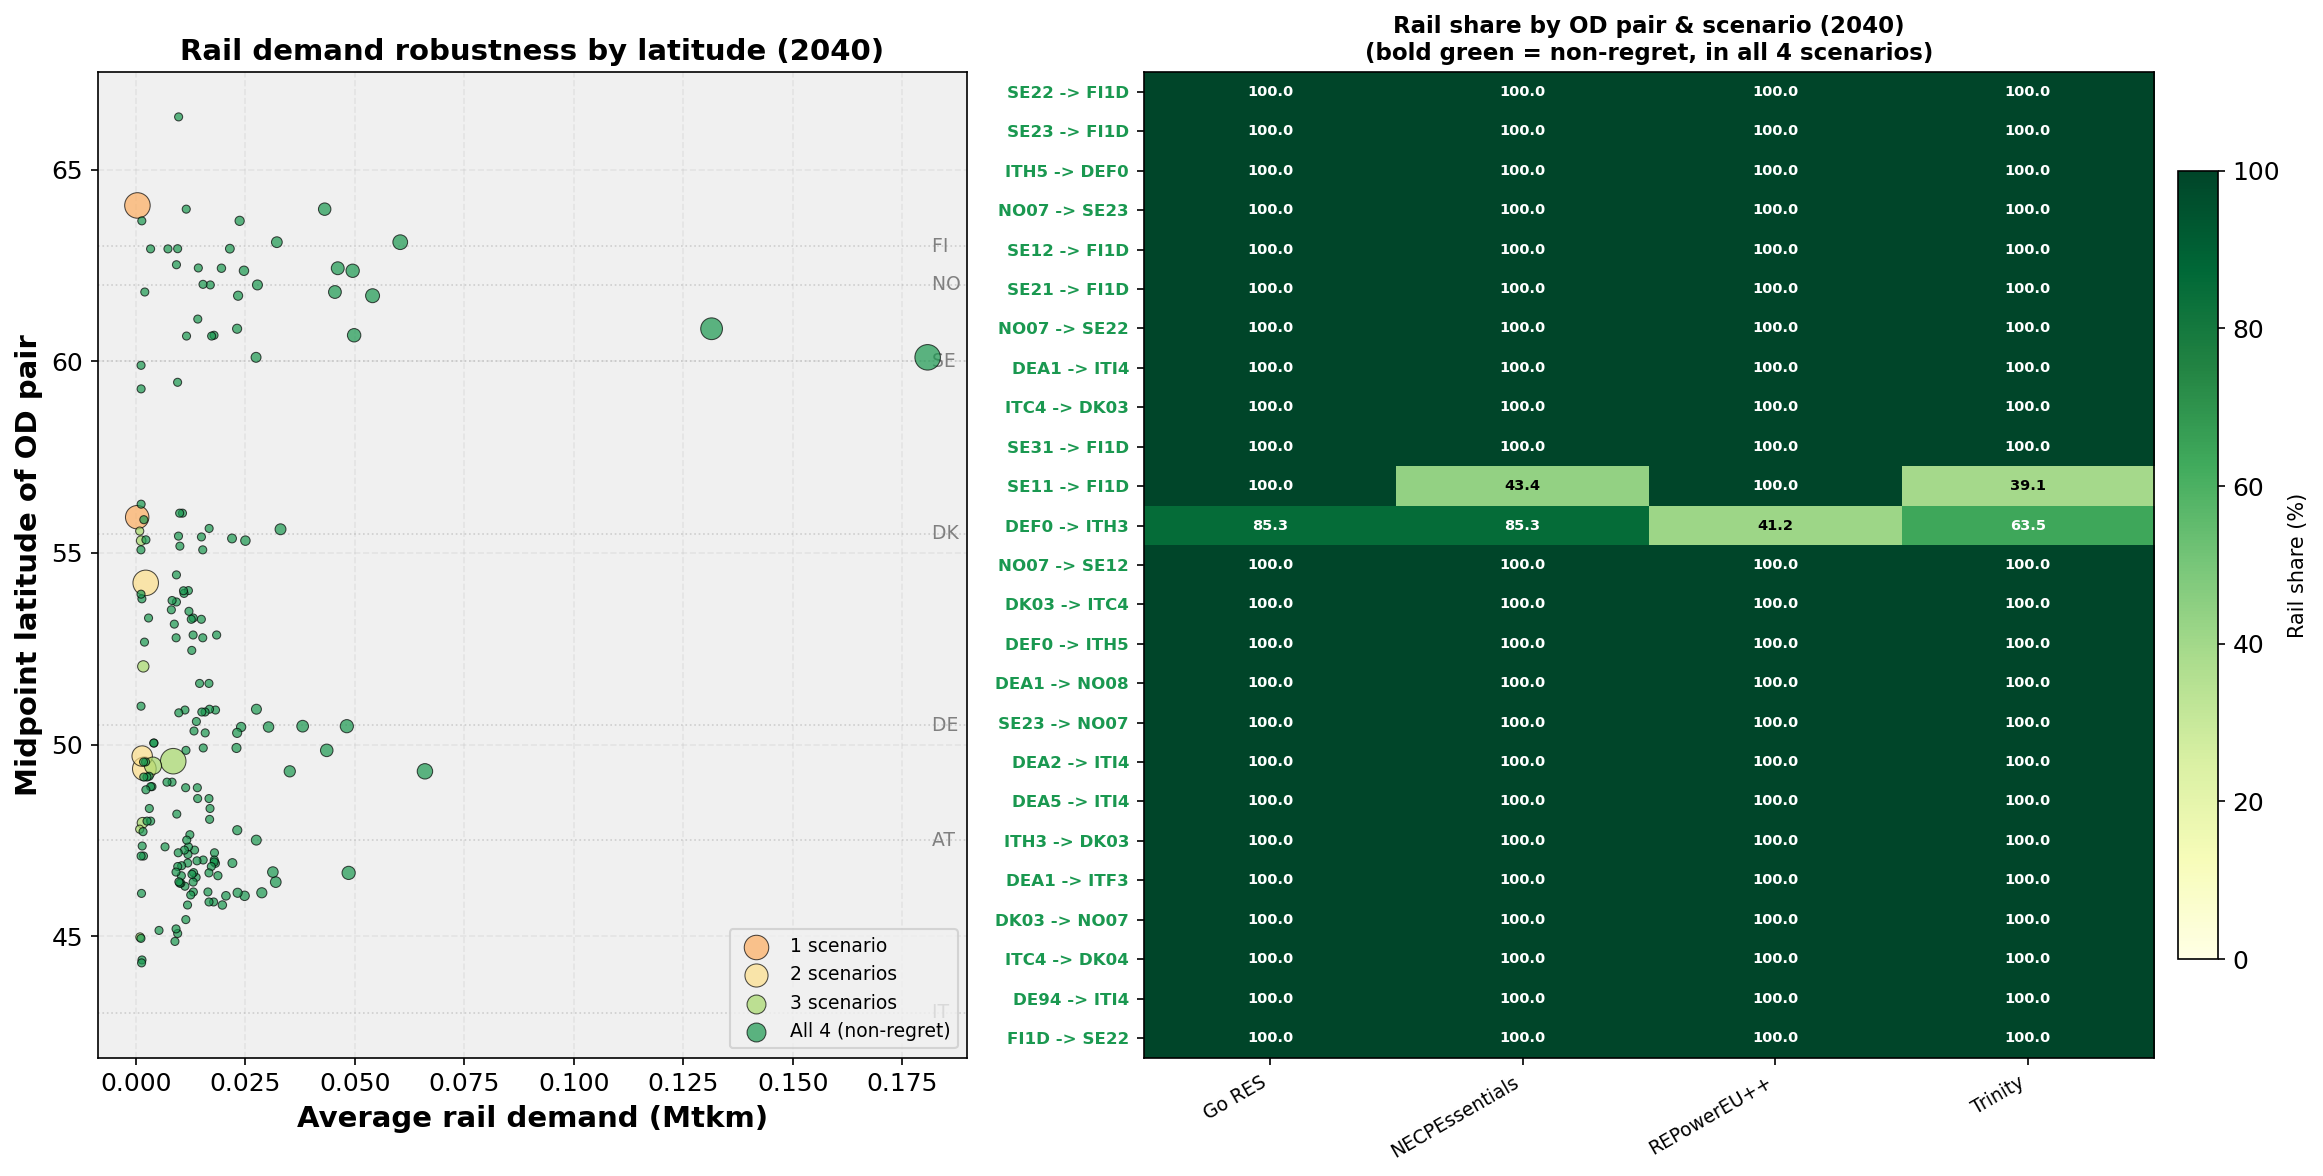

Saved: figures/nonregret_rail_demand_2040.pdf


In [84]:
# ============================================================
# Figure 9b: Non-regret rail demand visualization
# Left: Rail tkm by latitude, colored by # scenarios
# Right: Top OD pairs heatmap across scenarios
# ============================================================

from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 2, figsize=(16, 8),
                         gridspec_kw={'width_ratios': [1, 1.4]})

# ---- Left: Rail demand by latitude, colored by overlap count ----
ax = axes[0]
overlap_colors = {1: '#fdae61', 2: '#fee08b', 3: '#a6d96a', 4: '#1a9850'}
overlap_labels = {1: '1 scenario', 2: '2 scenarios', 3: '3 scenarios', 4: 'All 4 (non-regret)'}

for n_scen in [1, 2, 3, 4]:
    subset = df_overlap[df_overlap['n_scenarios'] == n_scen]
    if len(subset) == 0:
        continue
    ax.scatter(
        subset['avg_rail_tkm'] / 1e6,
        subset['midpoint_lat'],
        c=overlap_colors[n_scen],
        s=np.clip(subset['avg_rail_tkm'] / subset['avg_rail_tkm'].max() * 150, 15, 200),
        alpha=0.7,
        edgecolor='black',
        linewidth=0.5,
        label=overlap_labels[n_scen],
        zorder=n_scen + 2,
    )

for country, clat in COUNTRY_LAT_CENTROIDS.items():
    ax.axhline(clat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
    ax.text(ax.get_xlim()[1] * 0.95 if ax.get_xlim()[1] > 0 else 0.5, clat, f' {country}',
            va='center', fontsize=9, color='gray')

ax.set_xlabel('Average rail demand (Mtkm)', fontweight='bold')
ax.set_ylabel('Midpoint latitude of OD pair', fontweight='bold')
ax.set_title(f'Rail demand robustness by latitude ({ANALYSIS_YEAR})', fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, alpha=0.2, linestyle='--')

# ---- Right: Heatmap of top OD pairs across scenarios ----
ax2 = axes[1]

# Take top 25 OD pairs by average rail tkm
top_n = 25
df_top = df_overlap.nlargest(top_n, 'avg_rail_tkm').copy()

# Build heatmap data: rail share (%) per OD pair per scenario
heatmap_data = np.zeros((len(df_top), len(scenario_names)))
row_labels = []

for i, (_, row) in enumerate(df_top.iterrows()):
    corridor = f"{row['origin_country']}-{row['dest_country']}"
    # Shorten NUTS names: "nuts2_DE21" -> "DE21"
    orig_short = row['origin'].replace('nuts2_', '')
    dest_short = row['destination'].replace('nuts2_', '')
    n_mark = '*' * row['n_scenarios'] if row['n_scenarios'] < 4 else ''
    row_labels.append(f"{orig_short} -> {dest_short}")
    
    for j, scen_name in enumerate(scenario_names):
        heatmap_data[i, j] = row[f'rail_share_{scen_name}']

im = ax2.imshow(heatmap_data, cmap='YlGn', aspect='auto', vmin=0,
                vmax=max(heatmap_data.max(), 1))
ax2.set_xticks(range(len(scenario_names)))
ax2.set_xticklabels(scenario_names, rotation=30, ha='right', fontsize=9)
ax2.set_yticks(range(len(row_labels)))
ax2.set_yticklabels(row_labels, fontsize=8)

# Add text annotations
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        val = heatmap_data[i, j]
        if val > 0:
            color = 'white' if val > heatmap_data.max() * 0.6 else 'black'
            ax2.text(j, i, f'{val:.1f}', ha='center', va='center',
                     fontsize=7, color=color, fontweight='bold')
        else:
            ax2.text(j, i, '-', ha='center', va='center',
                     fontsize=7, color='lightgray')

# Mark non-regret rows (all 4 scenarios)
for i, (_, row) in enumerate(df_top.iterrows()):
    if row['n_scenarios'] == 4:
        ax2.get_yticklabels()[i].set_fontweight('bold')
        ax2.get_yticklabels()[i].set_color('#1a9850')

cbar = plt.colorbar(im, ax=ax2, shrink=0.8, pad=0.02)
cbar.set_label('Rail share (%)', fontsize=10)

ax2.set_title(f'Rail share by OD pair & scenario ({ANALYSIS_YEAR})\n'
              f'(bold green = non-regret, in all 4 scenarios)',
              fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig(FIG_DIR / f'nonregret_rail_demand_{ANALYSIS_YEAR}.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / f'nonregret_rail_demand_{ANALYSIS_YEAR}.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'Saved: figures/nonregret_rail_demand_{ANALYSIS_YEAR}.pdf')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

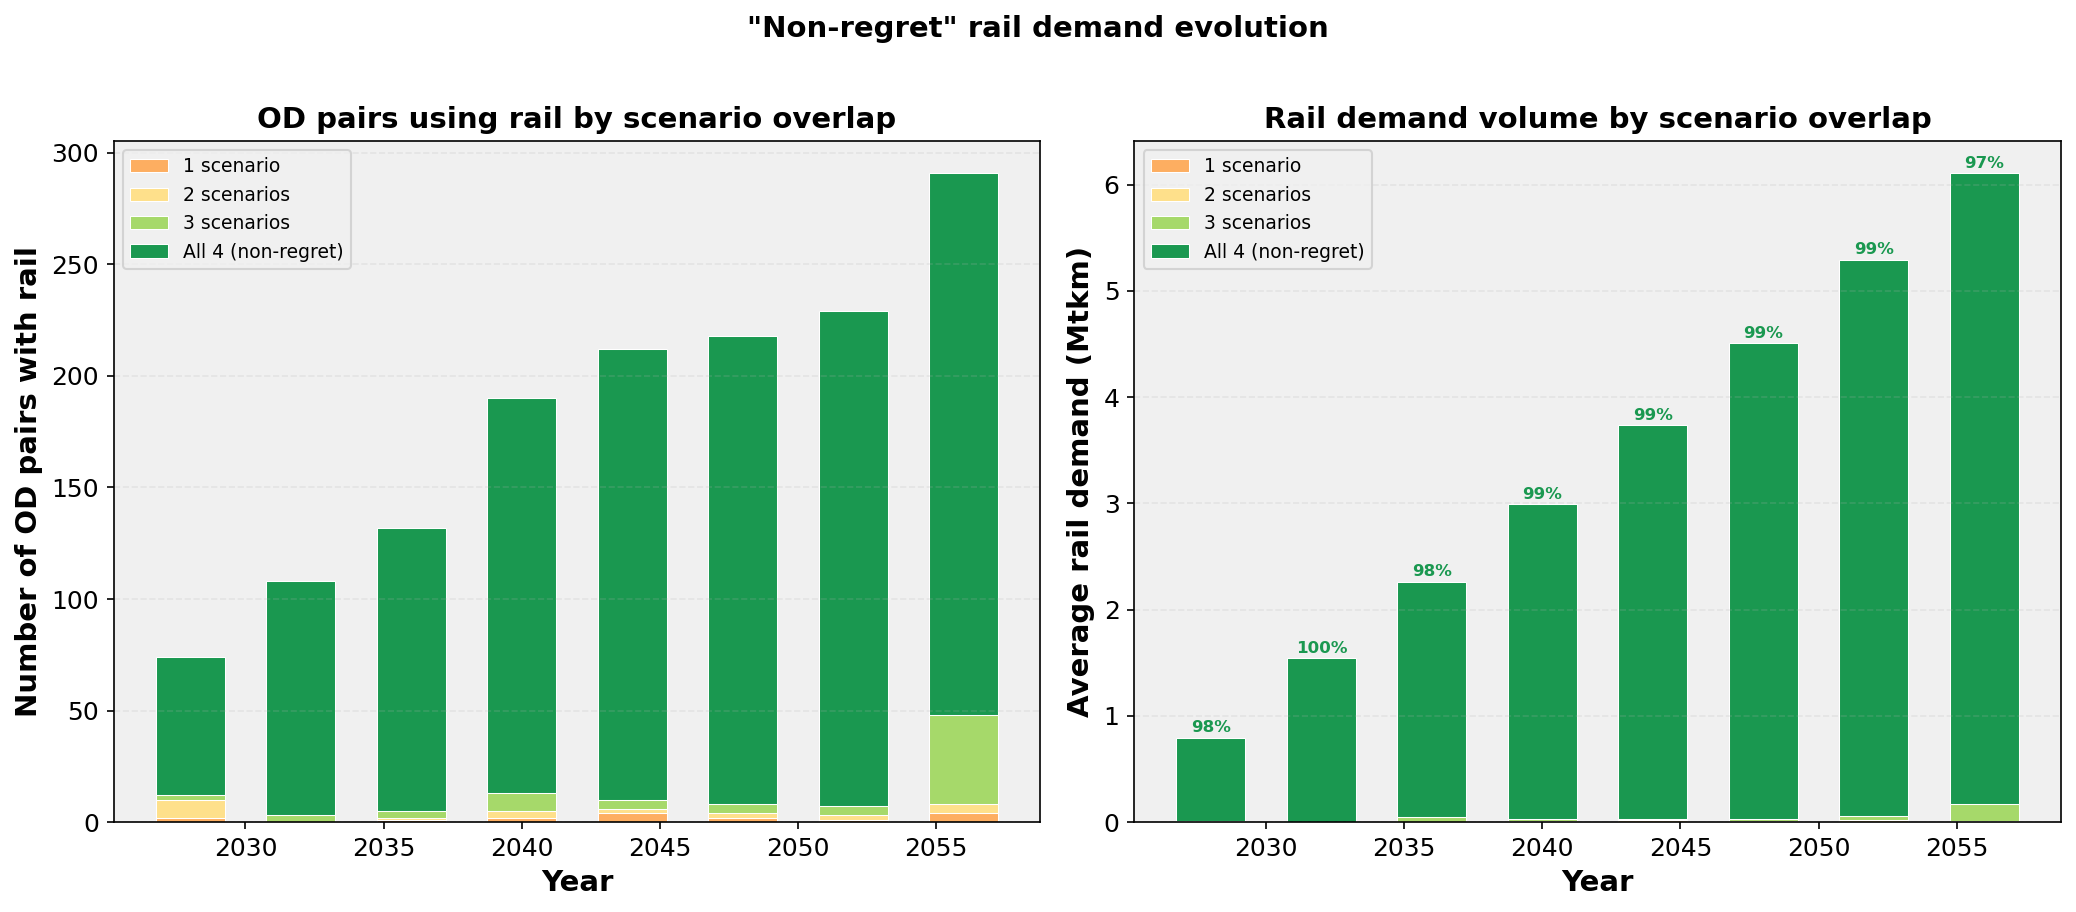

Saved: figures/nonregret_rail_evolution.pdf

Year    Total OD    4/4    3/4    2/4    1/4  NR tkm (M)    NR %
-----------------------------------------------------------------
2028          74     62      2      8      2        0.78   98.3%
2032         108    105      3      0      0        1.54   99.7%
2036         132    127      3      1      1        2.21   97.8%
2040         190    177      8      3      2        2.97   99.1%
2044         212    202      4      2      4        3.71   99.3%
2048         218    210      4      2      2        4.48   99.4%
2052         229    222      4      2      1        5.23   98.8%
2056         291    243     40      4      4        5.94   97.3%


In [85]:
# ============================================================
# Figure 9c: Non-regret rail demand evolution over time
# Bar chart: how many OD pairs have rail in N scenarios, per year
# + stacked rail tkm by overlap category
# ============================================================

CHECK_YEARS = [2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056]

# Compute overlap counts for each year
overlap_by_year = {}  # {year: {n_scenarios: (count_od, total_tkm)}}

for year in CHECK_YEARS:
    rail_sets = {}
    rail_tkm_per_scen = {}
    for scen_name in scenario_names:
        rail_map = rail_tkm_by_odpair(
            data[scen_name]['rail']['f'],
            data[scen_name]['rail']['input'],
            year
        )
        rail_sets[scen_name] = set(rail_map.keys())
        rail_tkm_per_scen[scen_name] = rail_map
    
    # All OD pairs with rail in this year
    all_od = set()
    for s in rail_sets.values():
        all_od |= s
    
    year_overlap = {1: [0, 0.0], 2: [0, 0.0], 3: [0, 0.0], 4: [0, 0.0]}
    for od_id in all_od:
        count = sum(1 for s in rail_sets.values() if od_id in s)
        avg_tkm = np.mean([rail_tkm_per_scen[s].get(od_id, 0.0) for s in scenario_names])
        year_overlap[count][0] += 1
        year_overlap[count][1] += avg_tkm
    
    overlap_by_year[year] = year_overlap

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: number of OD pairs by overlap category
ax = axes[0]
bar_width = 2.5
bottoms = np.zeros(len(CHECK_YEARS))

for n_scen in [1, 2, 3, 4]:
    vals = [overlap_by_year[y][n_scen][0] for y in CHECK_YEARS]
    ax.bar(CHECK_YEARS, vals, width=bar_width, bottom=bottoms,
           color=overlap_colors[n_scen], label=overlap_labels[n_scen],
           edgecolor='white', linewidth=0.5)
    bottoms += np.array(vals)

ax.set_xlabel('Year', fontweight='bold')
ax.set_ylabel('Number of OD pairs with rail', fontweight='bold')
ax.set_title('OD pairs using rail by scenario overlap', fontweight='bold')
ax.legend(fontsize=9, loc='upper left')
ax.grid(True, alpha=0.2, linestyle='--', axis='y')

# Right: rail tkm by overlap category
ax2 = axes[1]
bottoms2 = np.zeros(len(CHECK_YEARS))

for n_scen in [1, 2, 3, 4]:
    vals = [overlap_by_year[y][n_scen][1] / 1e6 for y in CHECK_YEARS]
    ax2.bar(CHECK_YEARS, vals, width=bar_width, bottom=bottoms2,
            color=overlap_colors[n_scen], label=overlap_labels[n_scen],
            edgecolor='white', linewidth=0.5)
    bottoms2 += np.array(vals)

# Add non-regret percentage labels
for yi, year in enumerate(CHECK_YEARS):
    total_tkm = sum(overlap_by_year[year][n][1] for n in [1,2,3,4])
    nr_tkm = overlap_by_year[year][4][1]
    if total_tkm > 0:
        pct = nr_tkm / total_tkm * 100
        ax2.text(year, bottoms2[yi] + 0.02, f'{pct:.0f}%',
                ha='center', va='bottom', fontsize=8, fontweight='bold',
                color=overlap_colors[4])

ax2.set_xlabel('Year', fontweight='bold')
ax2.set_ylabel('Average rail demand (Mtkm)', fontweight='bold')
ax2.set_title('Rail demand volume by scenario overlap', fontweight='bold')
ax2.legend(fontsize=9, loc='upper left')
ax2.grid(True, alpha=0.2, linestyle='--', axis='y')

fig.suptitle('"Non-regret" rail demand evolution', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nonregret_rail_evolution.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'nonregret_rail_evolution.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/nonregret_rail_evolution.pdf')

# Print summary table
print(f'\n{"Year":<6} {"Total OD":>9} {"4/4":>6} {"3/4":>6} {"2/4":>6} {"1/4":>6} '
      f'{"NR tkm (M)":>11} {"NR %":>7}')
print('-' * 65)
for year in CHECK_YEARS:
    ov = overlap_by_year[year]
    total_od = sum(ov[n][0] for n in [1,2,3,4])
    total_tkm = sum(ov[n][1] for n in [1,2,3,4])
    nr_tkm = ov[4][1]
    nr_pct = nr_tkm / total_tkm * 100 if total_tkm > 0 else 0
    print(f'{year:<6} {total_od:>9} {ov[4][0]:>6} {ov[3][0]:>6} {ov[2][0]:>6} {ov[1][0]:>6} '
          f'{nr_tkm/1e6:>11.2f} {nr_pct:>6.1f}%')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

  Go RES 2028: 58 nodes, 0.8 Mtkm rail
  Go RES 2032: 66 nodes, 1.5 Mtkm rail
  Go RES 2040: 74 nodes, 3.0 Mtkm rail
  Go RES 2048: 74 nodes, 4.5 Mtkm rail
  NECPEssentials 2028: 60 nodes, 0.8 Mtkm rail
  NECPEssentials 2032: 66 nodes, 1.5 Mtkm rail
  NECPEssentials 2040: 74 nodes, 3.0 Mtkm rail
  NECPEssentials 2048: 74 nodes, 4.5 Mtkm rail
  REPowerEU++ 2028: 58 nodes, 0.8 Mtkm rail
  REPowerEU++ 2032: 66 nodes, 1.5 Mtkm rail
  REPowerEU++ 2040: 74 nodes, 3.0 Mtkm rail
  REPowerEU++ 2048: 74 nodes, 4.5 Mtkm rail
  Trinity 2028: 60 nodes, 0.8 Mtkm rail
  Trinity 2032: 66 nodes, 1.5 Mtkm rail
  Trinity 2040: 74 nodes, 3.0 Mtkm rail
  Trinity 2048: 74 nodes, 4.5 Mtkm rail


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

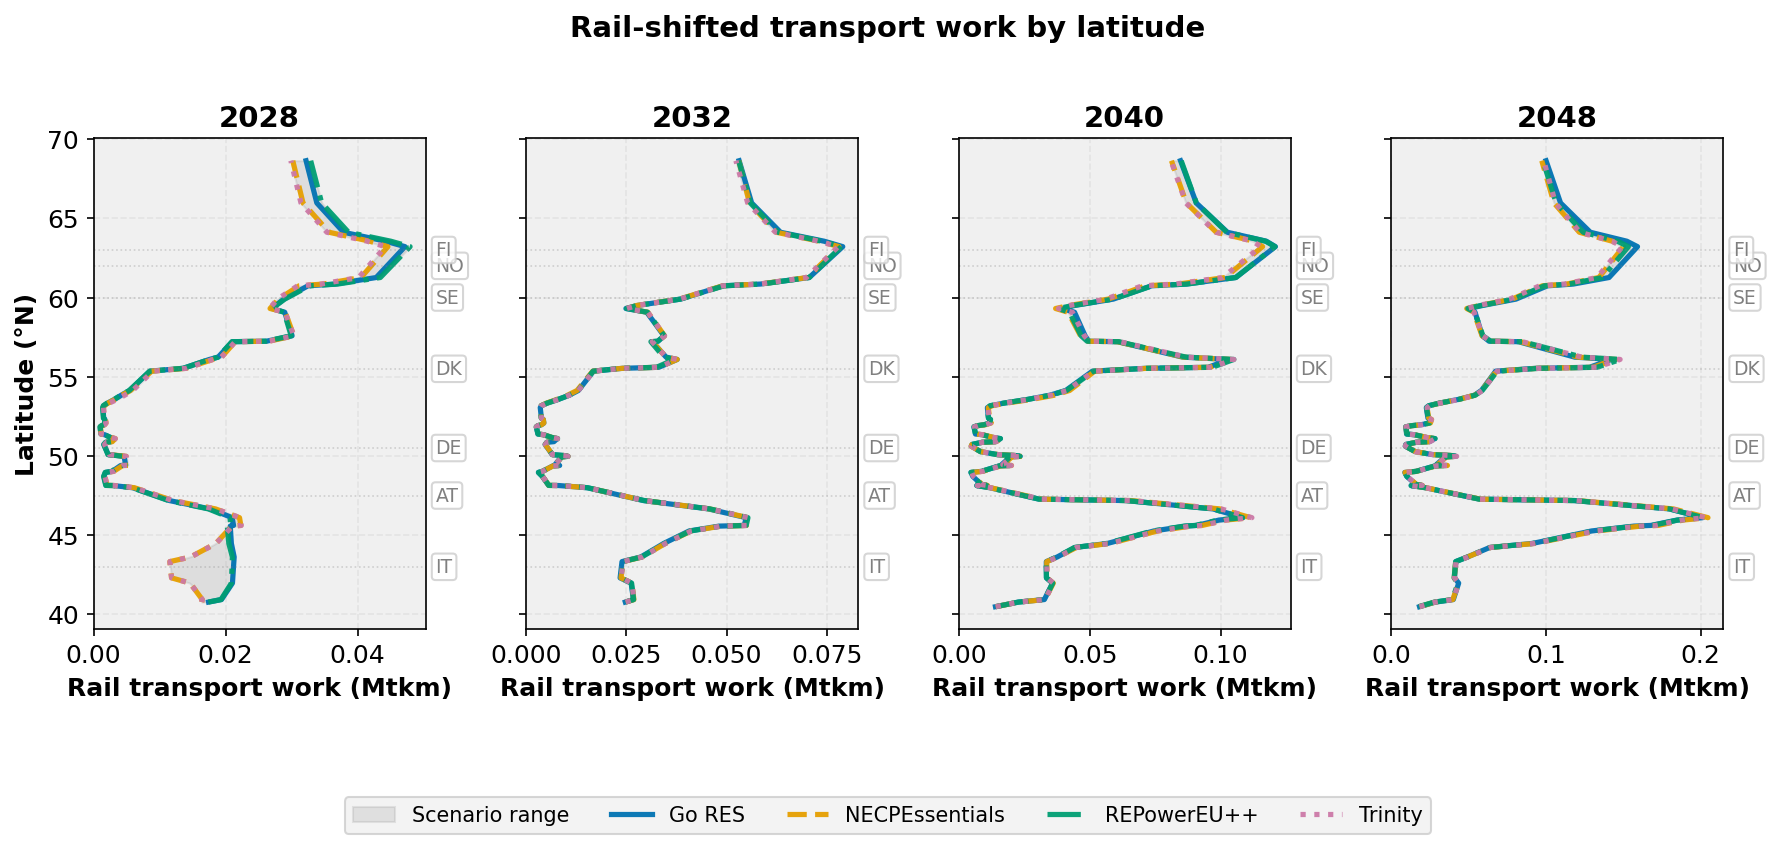

Saved: figures/rail_tkm_by_latitude_scenarios_overlap.pdf


In [86]:
# ============================================================
# Figure 10: Rail TKM by latitude — all scenarios overlapped
# Distributes rail tkm along path sequence nodes
# (matching tonnes_vs_tkm_by_latitude style)
# ============================================================

def rail_tkm_by_node_latitude(f_dict, input_data, target_year):
    """
    Distribute rail TKM along path sequence nodes.
    For each rail flow, walk the path sequence and attribute
    flow * segment_distance to each node.
    
    Returns: {geo_id: {'rail_tkm': float, 'lat': float, 'name': str}}
    """
    path_by_id = input_data['path_by_id']
    geo_by_id = input_data['geo_by_id']
    
    result = {}
    
    for key, tonnes in f_dict.items():
        year = key[0]
        if year != target_year:
            continue
        path_id = key[1][2]
        mode_id = key[2][0]
        if mode_id != 2:  # rail only
            continue
        if tonnes <= 0:
            continue
        
        path_info = path_by_id.get(path_id)
        if path_info is None:
            continue
        
        sequence = path_info['sequence']
        dist_from_prev = path_info['distance_from_previous']
        
        for i, node_id in enumerate(sequence):
            geo = geo_by_id.get(node_id)
            if geo is None:
                continue
            # Only nodes (not edges)
            if geo.get('type', 'node') != 'node':
                continue
            
            segment_km = dist_from_prev[i]
            tkm = tonnes * segment_km
            
            if node_id not in result:
                result[node_id] = {
                    'rail_tkm': 0.0,
                    'lat': geo['coordinate_lat'],
                    'name': geo.get('name', f'geo_{node_id}'),
                    'country': geo.get('country', '??'),
                }
            result[node_id]['rail_tkm'] += tkm
    
    return result


# --- Compute for all scenarios — 4 years ---
PLOT_YEARS = [2028, 2032, 2040, 2048]
rail_by_node = {}  # {scen_name: {year: {geo_id: {...}}}}

for scen_name in SCENARIOS:
    rail_by_node[scen_name] = {}
    for year in PLOT_YEARS:
        rail_by_node[scen_name][year] = rail_tkm_by_node_latitude(
            data[scen_name]['rail']['f'],
            data[scen_name]['rail']['input'],
            year
        )
        n_nodes = len(rail_by_node[scen_name][year])
        total = sum(v['rail_tkm'] for v in rail_by_node[scen_name][year].values())
        print(f'  {scen_name} {year}: {n_nodes} nodes, {total/1e6:.1f} Mtkm rail')


# --- Plot: 4 panels (one per year), envelope fill + 4 distinct lines ---
# Publication-ready palette: colorblind-friendly (Wong/Okabe-Ito)
RAIL_COLORS = {
    'Go RES':         '#0072B2',  # blue
    'NECPEssentials': '#E69F00',  # amber
    'REPowerEU++':    '#009E73',  # teal
    'Trinity':        '#CC79A7',  # rose
}
RAIL_LINESTYLES = {
    'Go RES':         '-',
    'NECPEssentials': '--',
    'REPowerEU++':    '-.',
    'Trinity':        ':',
}

fig, axes = plt.subplots(1, 4, figsize=(12, 5), sharey=True)

for yi, year in enumerate(PLOT_YEARS):
    ax = axes[yi]
    
    # Collect per-scenario (lats, smooth) pairs
    scenario_curves = {}
    for scen_name in SCENARIOS:
        node_data = rail_by_node[scen_name][year]
        if not node_data:
            continue
        sorted_nodes = sorted(node_data.values(), key=lambda x: x['lat'])
        lats = np.array([n['lat'] for n in sorted_nodes])
        tkm_vals = np.array([n['rail_tkm'] for n in sorted_nodes])
        if len(lats) > 3:
            tkm_smooth = gaussian_filter1d(tkm_vals / 1e6, sigma=1.5)
        else:
            tkm_smooth = tkm_vals / 1e6
        scenario_curves[scen_name] = (lats, tkm_smooth)
    
    # Interpolate all scenarios onto a common latitude grid for envelope
    if scenario_curves:
        all_lat_vals = np.concatenate([c[0] for c in scenario_curves.values()])
        common_lats = np.linspace(all_lat_vals.min(), all_lat_vals.max(), 300)
        
        interp_smooth = []
        for scen_name, (lats, smooth) in scenario_curves.items():
            interp_vals = np.interp(common_lats, lats, smooth)
            interp_smooth.append(interp_vals)
        
        smooth_stack = np.array(interp_smooth)
        env_min = smooth_stack.min(axis=0)
        env_max = smooth_stack.max(axis=0)
        ax.fill_betweenx(common_lats, env_min, env_max, alpha=0.18,
                         color='#888888', label='Scenario range')
    
    # Draw individual scenario lines on top
    for scen_name in SCENARIOS:
        if scen_name not in scenario_curves:
            continue
        lats, tkm_smooth = scenario_curves[scen_name]
        ax.plot(tkm_smooth, lats,
                color=RAIL_COLORS[scen_name],
                linestyle=RAIL_LINESTYLES[scen_name],
                linewidth=2.5, label=scen_name, alpha=0.95)
    
    # Country labels
    for country, clat in COUNTRY_LAT_CENTROIDS.items():
        ax.axhline(clat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
        ax.text(1.03, clat, country, transform=ax.get_yaxis_transform(),
                va='center', fontsize=9, color='gray',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          edgecolor='#ccc', alpha=0.8))
    
    ax.set_title(f'{year}', fontweight='bold', fontsize=14)
    ax.set_xlabel('Rail transport work (Mtkm)', fontweight='bold', fontsize=12)
    if yi == 0:
        ax.set_ylabel('Latitude (\u00b0N)', fontweight='bold', fontsize=12)
    ax.grid(True, alpha=0.2, linestyle='--')
    ax.set_xlim(left=0)

# Legend below the plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02),
           ncol=5, fontsize=10, frameon=True, edgecolor='#ccc')

fig.suptitle('Rail-shifted transport work by latitude',
             fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(FIG_DIR / 'rail_tkm_by_latitude_scenarios_overlap.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'rail_tkm_by_latitude_scenarios_overlap.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/rail_tkm_by_latitude_scenarios_overlap.pdf')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

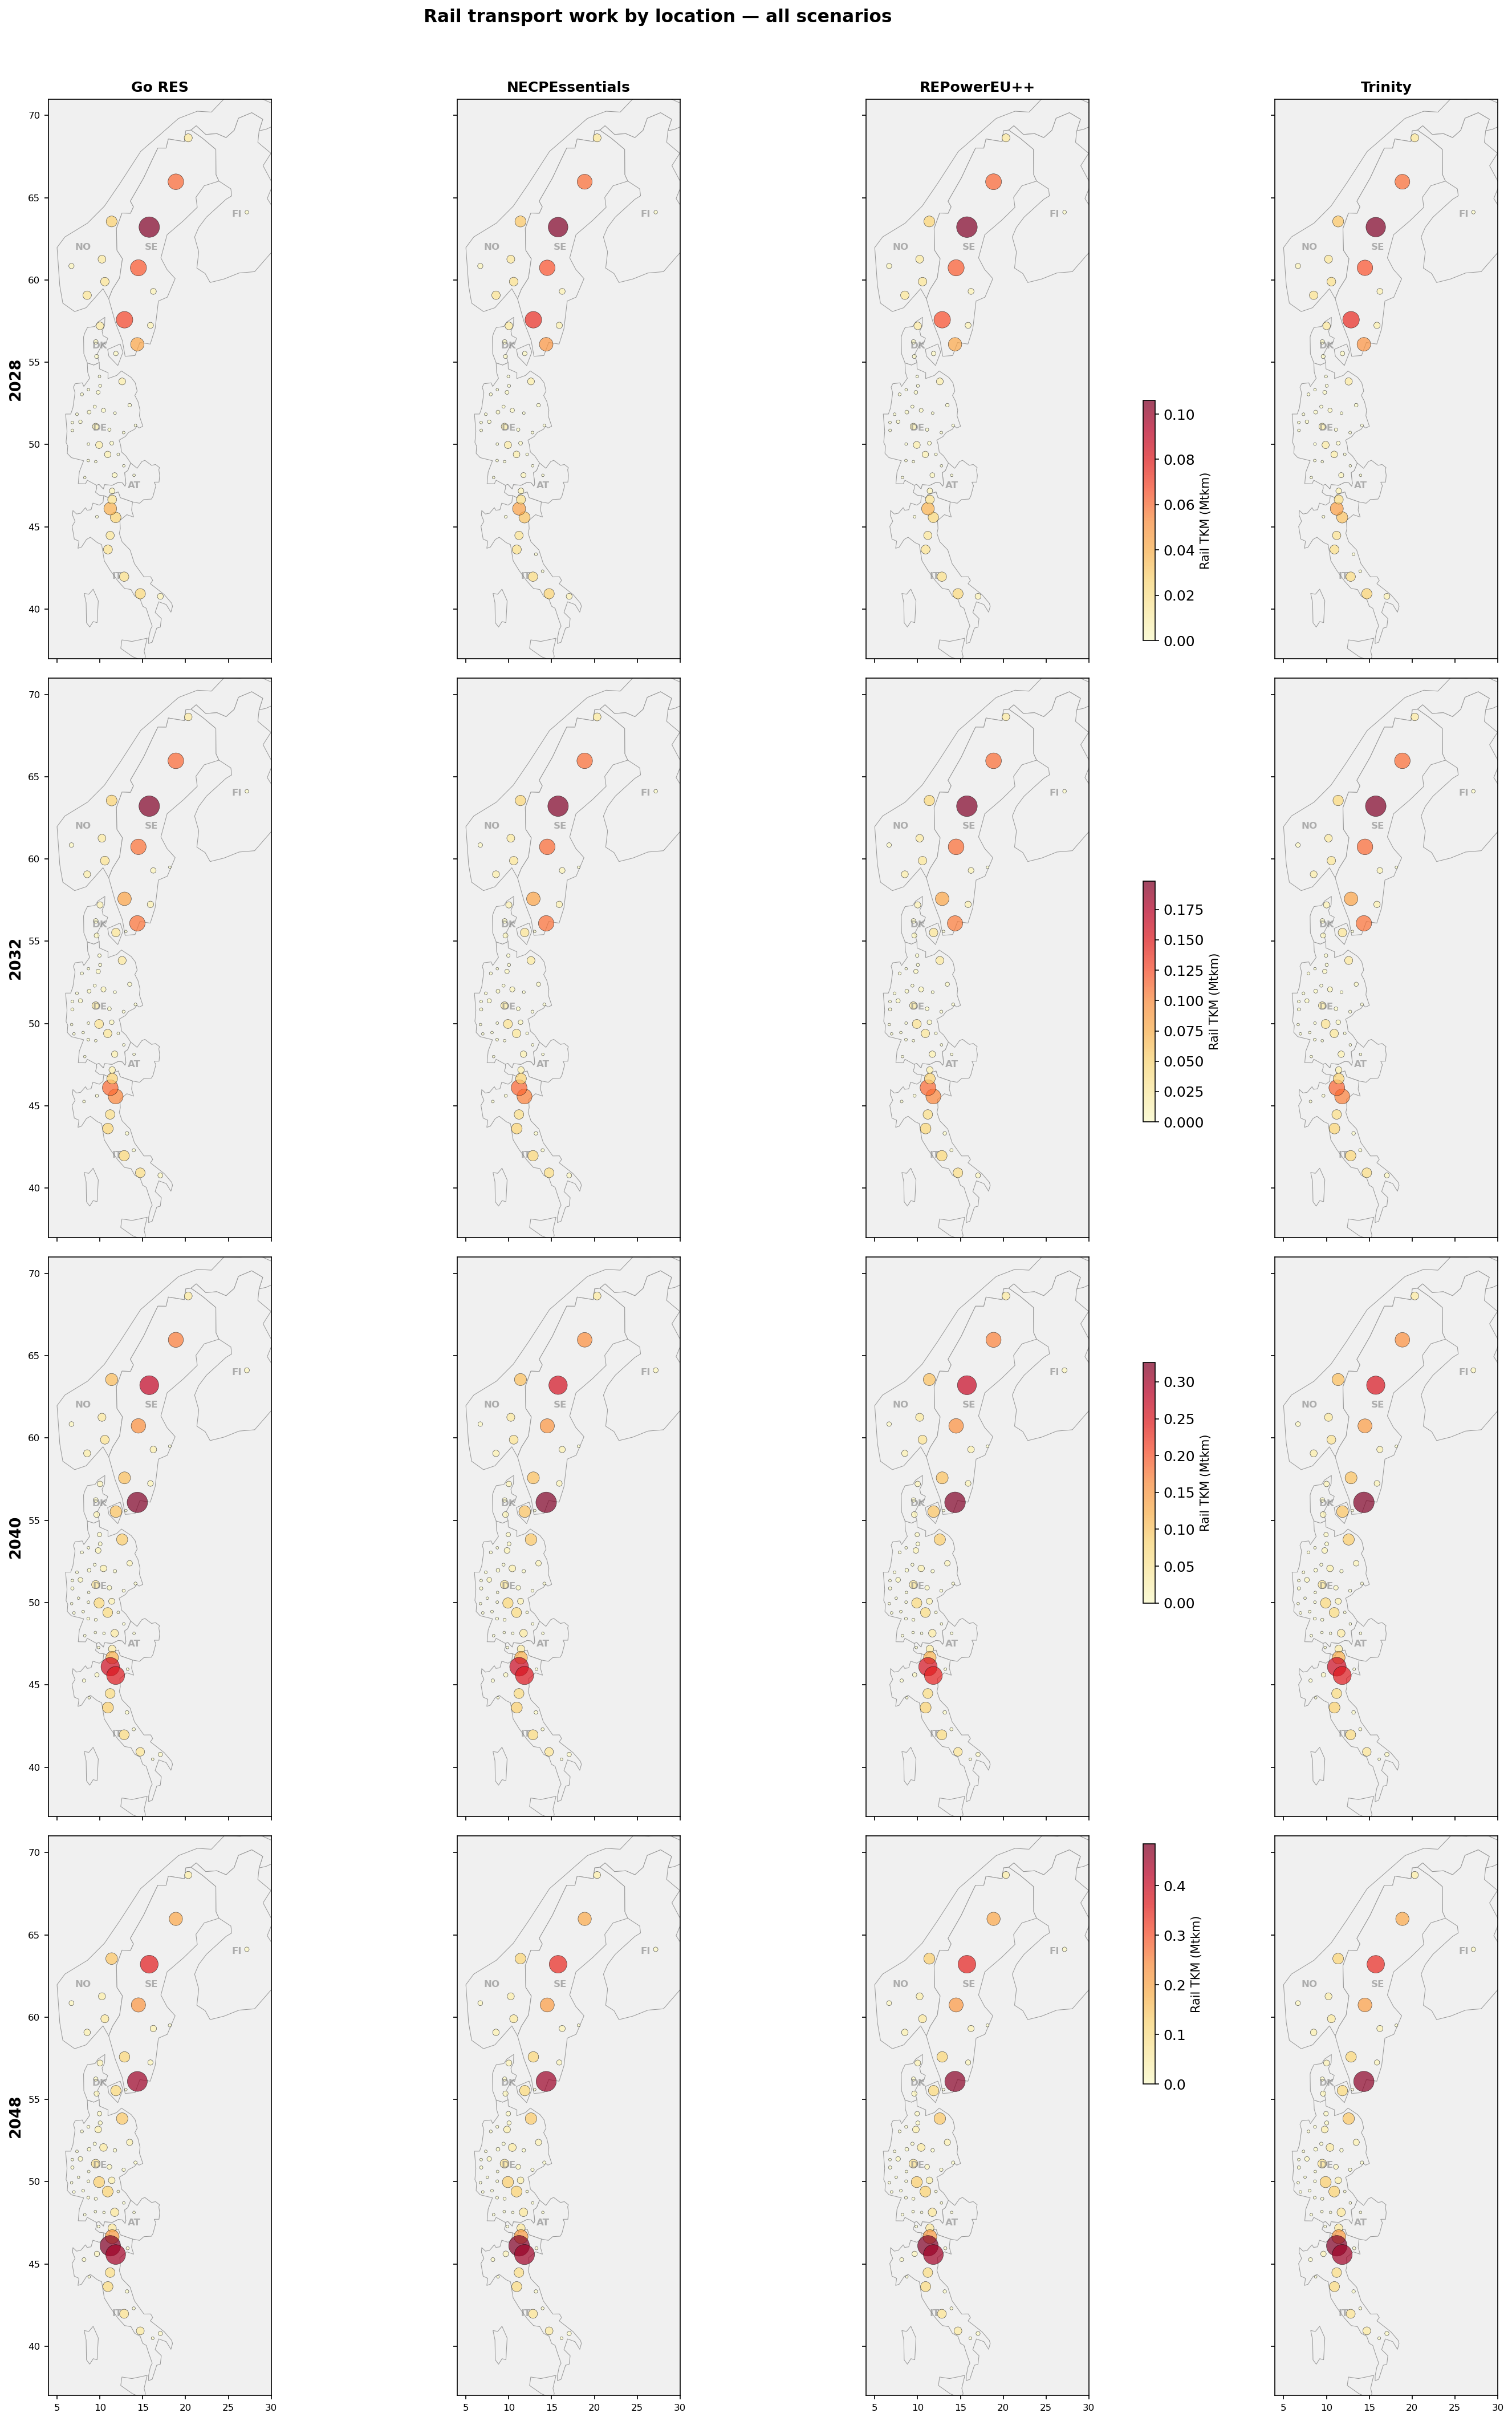

Saved: figures/rail_tkm_map_scenarios.pdf


In [87]:
# ============================================================
# Figure 11: MAP — Rail TKM by node location
# Uses geopandas for country borders, scatter for nodes
# ============================================================
import geopandas as gpd

# Load country borders
world = gpd.read_file('https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip')
corridor_countries = ['Norway', 'Sweden', 'Finland', 'Denmark', 'Germany', 'Austria', 'Italy']
corridor = world[world['NAME'].isin(corridor_countries)]

PLOT_YEARS_MAP = [2028, 2032, 2040, 2048]

# Re-use rail_tkm_by_node_latitude from cell 24 (already defined)
# Compute for all scenarios and years (may already be cached from cell 24)
for scen_name in SCENARIOS:
    if scen_name not in rail_by_node:
        rail_by_node[scen_name] = {}
    for year in PLOT_YEARS_MAP:
        if year not in rail_by_node[scen_name]:
            rail_by_node[scen_name][year] = rail_tkm_by_node_latitude(
                data[scen_name]['rail']['f'],
                data[scen_name]['rail']['input'],
                year
            )

# --- Map: 4 scenarios x 4 years ---
fig, axes = plt.subplots(len(PLOT_YEARS_MAP), 4, figsize=(20, 28))

for yi, year in enumerate(PLOT_YEARS_MAP):
    # Get global max for consistent sizing across scenarios
    all_tkm = []
    for scen_name in SCENARIOS:
        for nd in rail_by_node[scen_name][year].values():
            all_tkm.append(nd['rail_tkm'])
    max_tkm = max(all_tkm) if all_tkm else 1

    for si, scen_name in enumerate(SCENARIOS):
        ax = axes[yi, si]

        # Country borders
        corridor.plot(ax=ax, color='#f0f0f0', edgecolor='#999', linewidth=0.5)

        node_data = rail_by_node[scen_name][year]
        if node_data:
            lats = [nd['lat'] for nd in node_data.values()]
            lons = []
            # Get longitudes from input geo data
            geo_by_id = data[scen_name]['rail']['input']['geo_by_id']
            for geo_id, nd in node_data.items():
                geo = geo_by_id.get(geo_id, {})
                lons.append(geo.get('coordinate_long', 12.0))

            tkm_vals = np.array([nd['rail_tkm'] for nd in node_data.values()])
            sizes = (tkm_vals / max_tkm) * 300 + 5  # scale bubble size

            sc = ax.scatter(lons, lats, s=sizes, c=tkm_vals / 1e6,
                           cmap='YlOrRd', alpha=0.7, edgecolors='black',
                           linewidth=0.3, vmin=0)

        ax.set_xlim(4, 30)
        ax.set_ylim(37, 71)

        if yi == 0:
            ax.set_title(scen_name, fontweight='bold', fontsize=12)
        if si == 0:
            ax.set_ylabel(f'{year}', fontweight='bold', fontsize=13)
        else:
            ax.set_yticklabels([])
        if yi < len(PLOT_YEARS_MAP) - 1:
            ax.set_xticklabels([])

        ax.tick_params(labelsize=8)
        # Country name labels
        for name, (cx, cy) in {"NO": (8,62), "SE": (16,62), "FI": (26,64), "DK": (10,56), "DE": (10,51), "AT": (14,47.5), "IT": (12,42)}.items():
            ax.text(cx, cy, name, fontsize=8, color="gray", fontweight="bold", ha="center", va="center", alpha=0.6)

    # Colorbar per row
    cbar = fig.colorbar(sc, ax=axes[yi, :].tolist(), shrink=0.6, pad=0.02)
    cbar.set_label('Rail TKM (Mtkm)', fontsize=10)

fig.suptitle('Rail transport work by location — all scenarios',
             fontweight='bold', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'rail_tkm_map_scenarios.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'rail_tkm_map_scenarios.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/rail_tkm_map_scenarios.pdf')

BEV spec_cons: 2.06 (2020) -> 1.21 kWh/km (2060)
BEV payload W: 10.9 (2020) -> 14.4 t (2060)
  Go RES baseline 2032: 64 nodes, 282 GWh BEV
  Go RES baseline 2040: 81 nodes, 1,513 GWh BEV
  Go RES baseline 2048: 81 nodes, 2,210 GWh BEV
  Go RES rail 2032: 69 nodes, 317 GWh BEV
  Go RES rail 2040: 78 nodes, 1,728 GWh BEV
  Go RES rail 2048: 77 nodes, 2,677 GWh BEV
  NECPEssentials baseline 2032: 81 nodes, 316 GWh BEV
  NECPEssentials baseline 2040: 81 nodes, 1,078 GWh BEV
  NECPEssentials baseline 2048: 81 nodes, 1,814 GWh BEV
  NECPEssentials rail 2032: 72 nodes, 392 GWh BEV
  NECPEssentials rail 2040: 78 nodes, 1,357 GWh BEV
  NECPEssentials rail 2048: 77 nodes, 2,307 GWh BEV
  REPowerEU++ baseline 2032: 81 nodes, 669 GWh BEV
  REPowerEU++ baseline 2040: 81 nodes, 1,486 GWh BEV
  REPowerEU++ baseline 2048: 81 nodes, 2,195 GWh BEV
  REPowerEU++ rail 2032: 75 nodes, 695 GWh BEV
  REPowerEU++ rail 2040: 78 nodes, 1,691 GWh BEV
  REPowerEU++ rail 2048: 77 nodes, 2,612 GWh BEV


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

  Trinity baseline 2032: 81 nodes, 331 GWh BEV
  Trinity baseline 2040: 81 nodes, 1,053 GWh BEV
  Trinity baseline 2048: 81 nodes, 1,791 GWh BEV
  Trinity rail 2032: 67 nodes, 272 GWh BEV
  Trinity rail 2040: 77 nodes, 1,131 GWh BEV
  Trinity rail 2048: 77 nodes, 2,080 GWh BEV


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

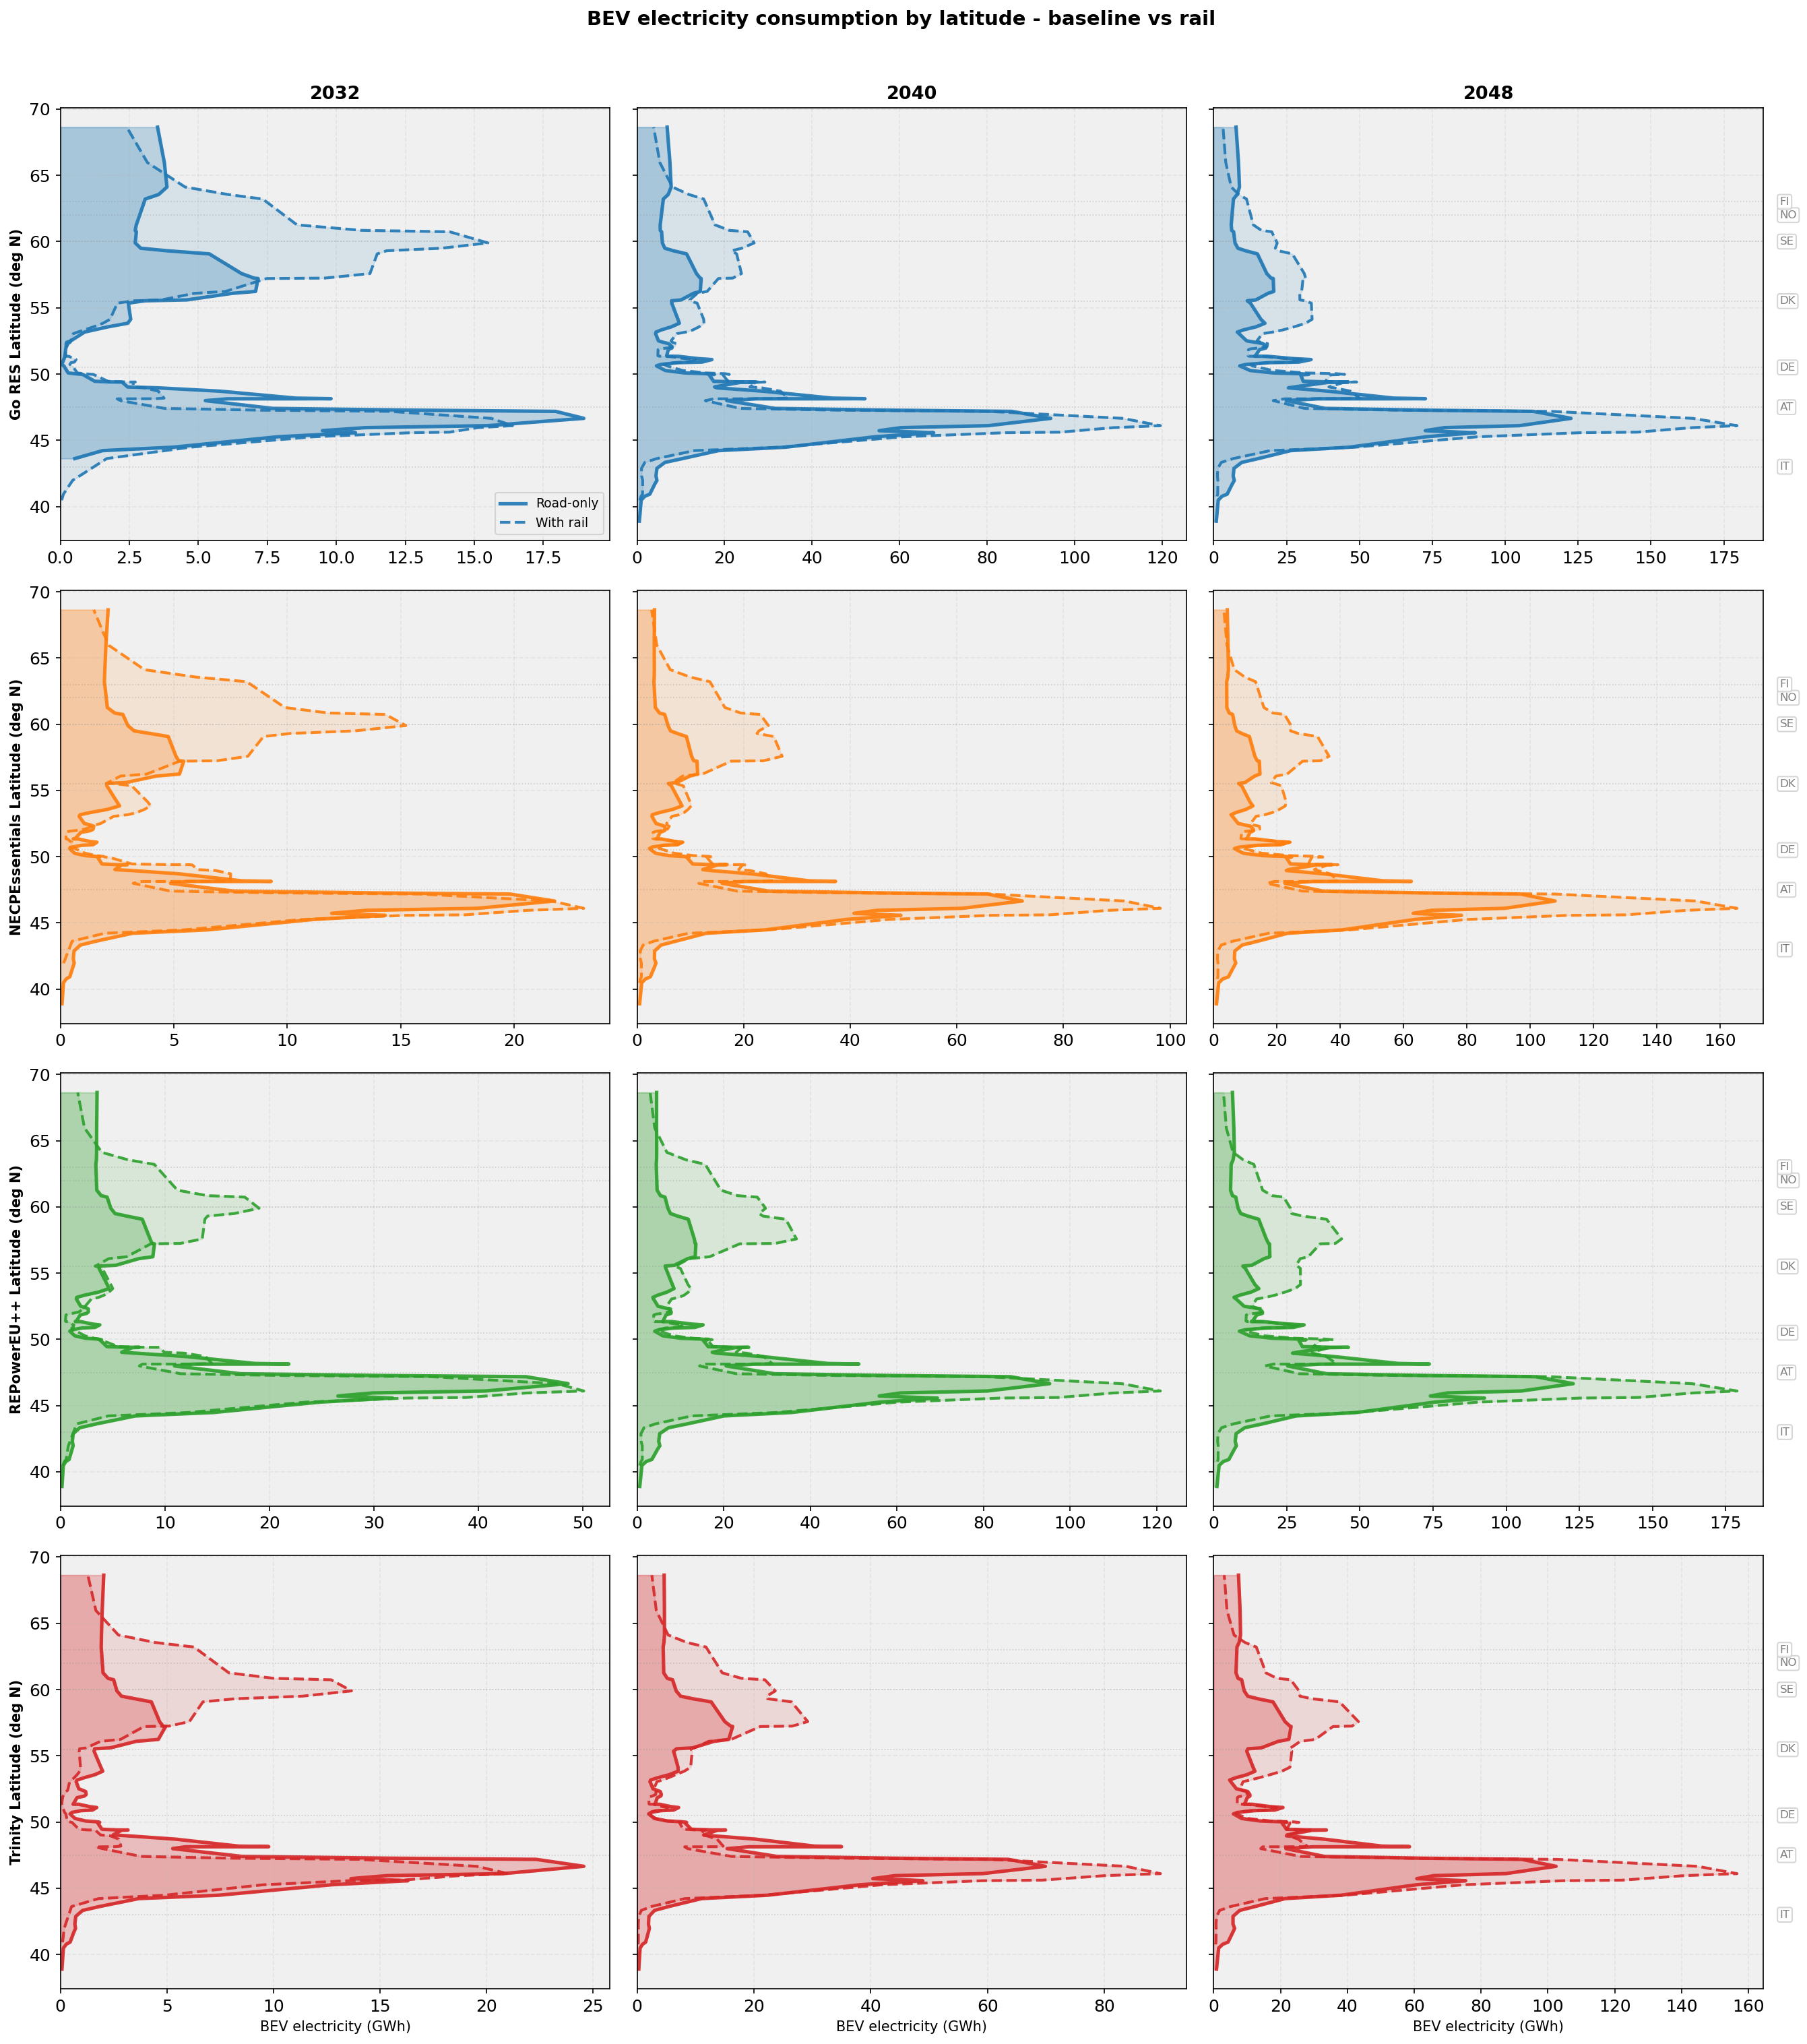

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

Saved: figures/bev_energy_by_latitude_baseline_vs_rail.pdf


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

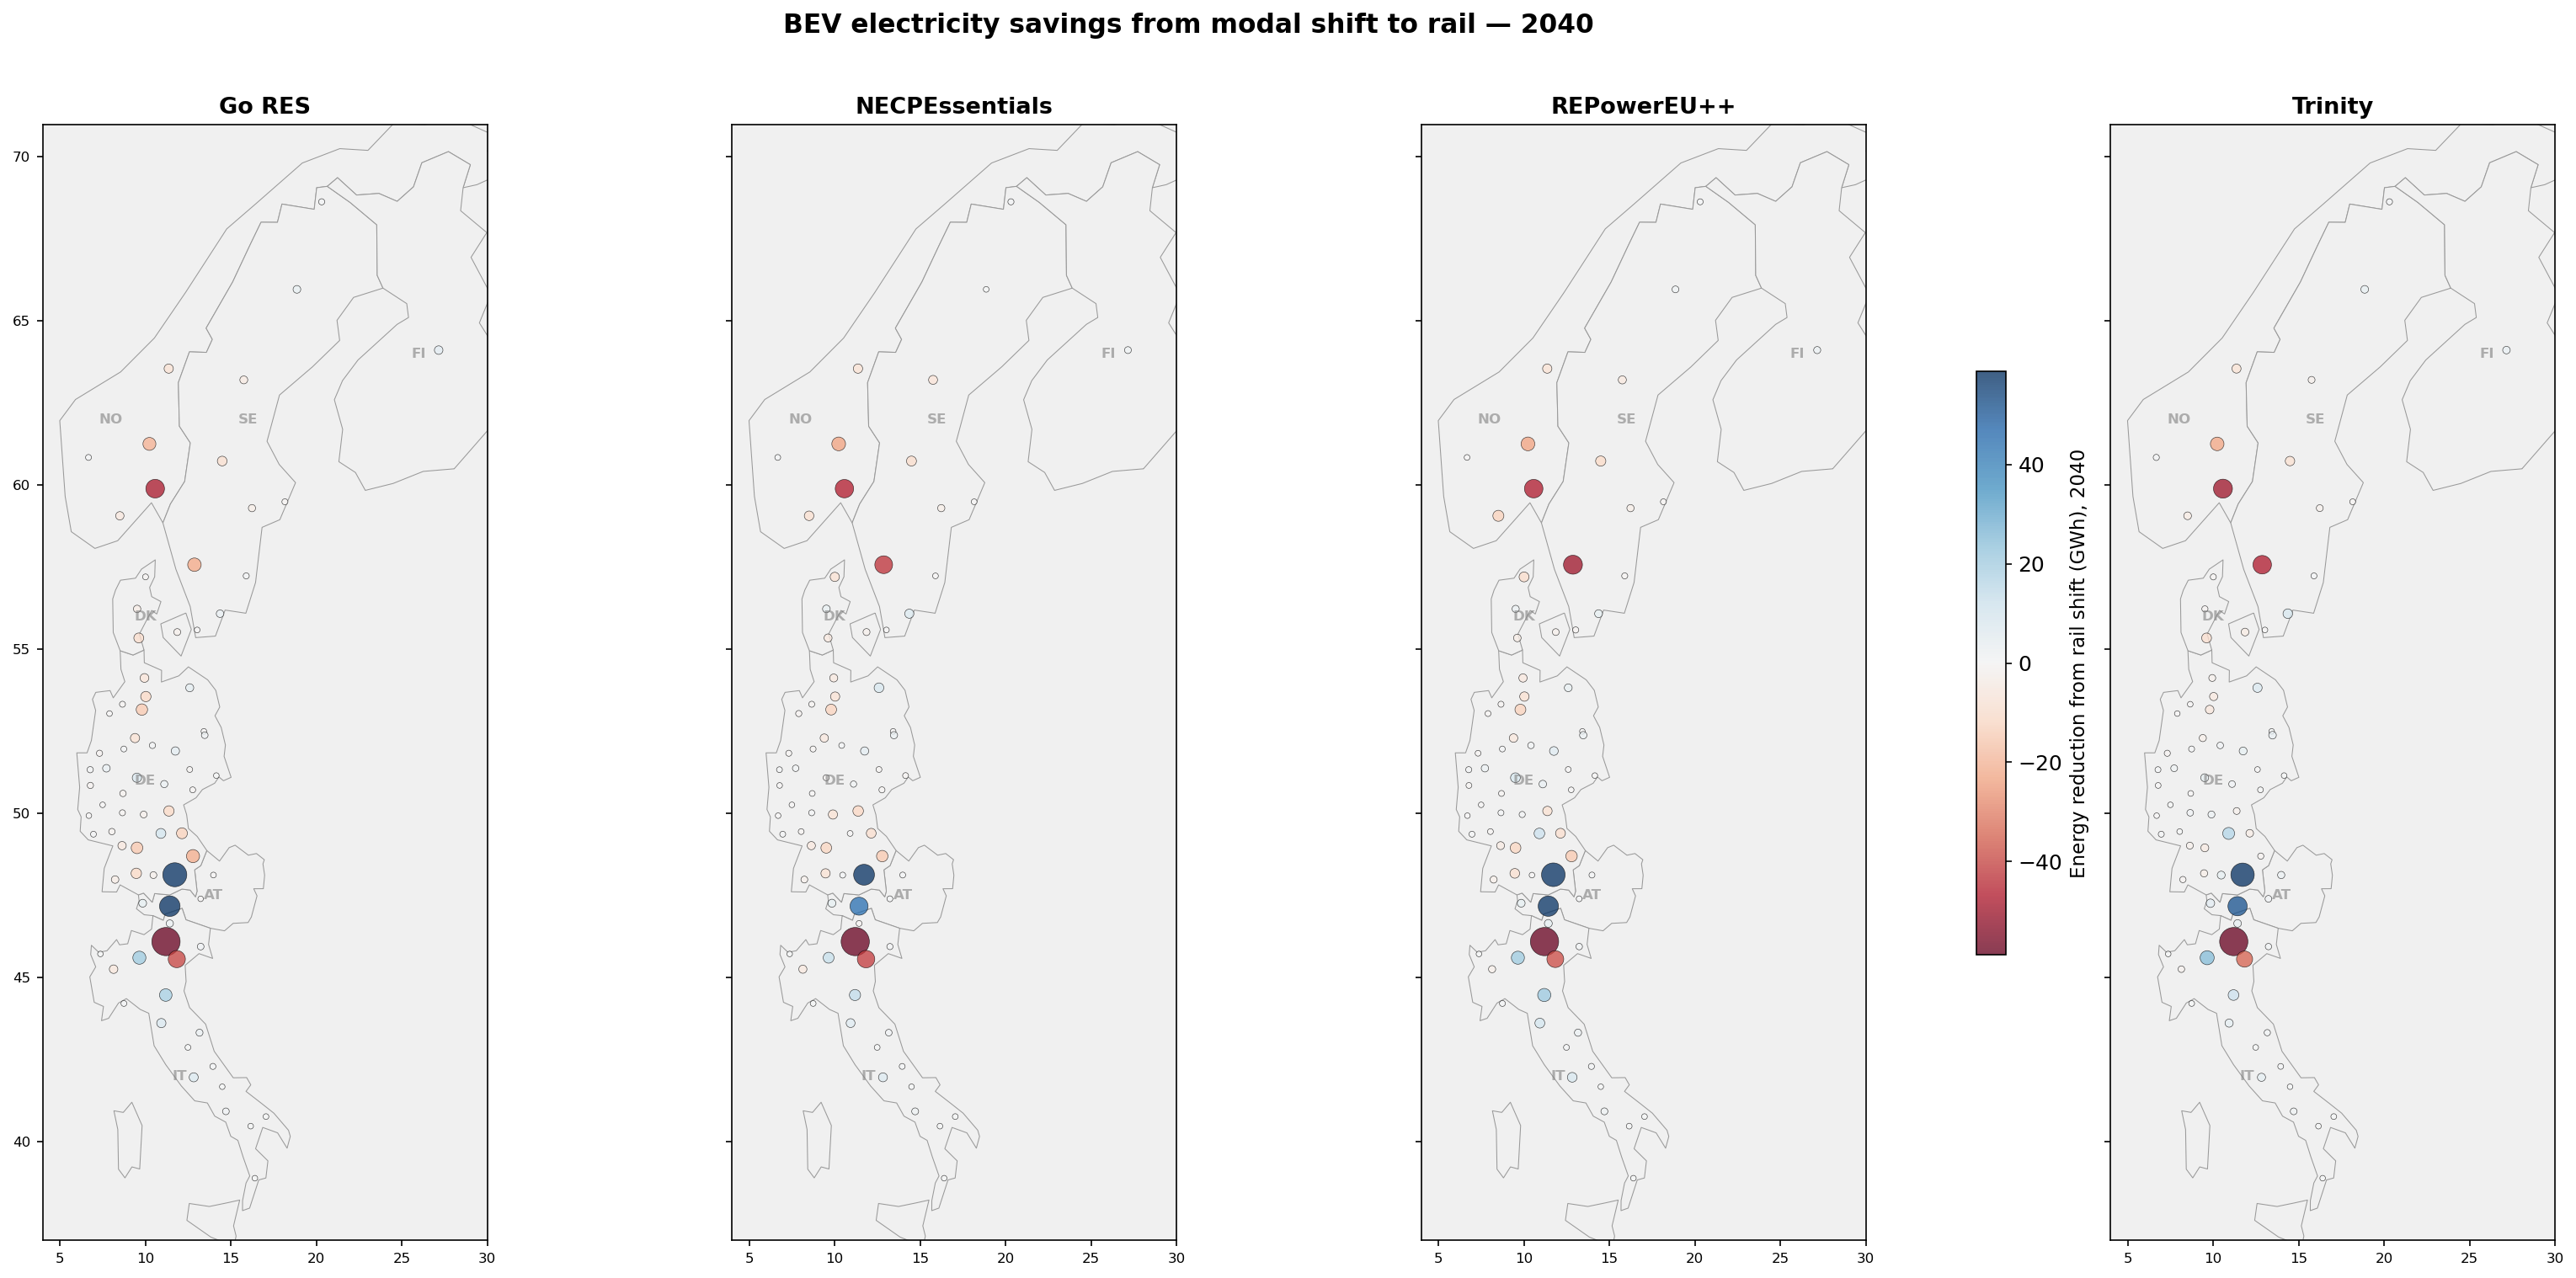

Saved: figures/bev_energy_delta_map_baseline_vs_rail.pdf


In [88]:
# ============================================================
# Figure 12: Charged energy comparison — baseline vs rail
# Estimates BEV electricity consumption by node location
# by walking f_dict flows along path sequences
# ============================================================

# TechVehicle parameters (from input data)
tv_yaml = yaml.safe_load(open(
    BASE_DIR / 'input_data' / 'uncertainty_scenarios' / 'scenario_000' / 'TechVehicle.yaml'
))
SPEC_CONS = {}  # kWh/km by tv_id, indexed by annual year
W_PAYLOAD = {}  # tonnes payload
for tv in tv_yaml:
    SPEC_CONS[tv['id']] = tv['spec_cons']
    W_PAYLOAD[tv['id']] = tv['W']
print(f"BEV spec_cons: {SPEC_CONS[1][0]:.2f} (2020) -> {SPEC_CONS[1][-1]:.2f} kWh/km (2060)")
print(f"BEV payload W: {W_PAYLOAD[1][0]:.1f} (2020) -> {W_PAYLOAD[1][-1]:.1f} t (2060)")


def energy_by_node(f_dict, input_data, target_year, tv_filter=1):
    """
    Estimate electricity consumption at each node by walking BEV flows
    along path sequences.

    For each BEV flow: energy_at_node = (tonnes*1000 / W) * spec_cons * segment_km
    Units: (ktonnes*1000/tonnes) * kWh/km * km = kWh -> convert to MWh

    Returns: {geo_id: {'energy_mwh': float, 'lat': float, 'lon': float, 'country': str}}
    """
    path_by_id = input_data['path_by_id']
    geo_by_id = input_data['geo_by_id']

    result = {}
    for key, tonnes_kt in f_dict.items():
        year = key[0]
        if year != target_year:
            continue
        path_id = key[1][2]
        mode_id = key[2][0]
        tv_id = key[2][1]
        gen = key[3]

        if mode_id != 1:  # road only
            continue
        if tv_id != tv_filter:  # BEV only (tv_id=1)
            continue
        if tonnes_kt <= 0:
            continue

        path_info = path_by_id.get(path_id)
        if path_info is None:
            continue

        # Get spec_cons and W for the generation year
        gen_idx = min(max(gen - 2020, 0), len(SPEC_CONS[tv_id]) - 1)
        sc = SPEC_CONS[tv_id][gen_idx]  # kWh/km
        w = W_PAYLOAD[tv_id][gen_idx]   # tonnes

        sequence = path_info['sequence']
        dist_from_prev = path_info['distance_from_previous']

        for i, node_id in enumerate(sequence):
            geo = geo_by_id.get(node_id)
            if geo is None:
                continue

            segment_km = dist_from_prev[i]
            if segment_km <= 0:
                continue

            # Energy = (ktonnes * 1000 / W) * spec_cons * segment_km / 1000 -> MWh
            energy_mwh = (tonnes_kt * 1000 / w) * sc * segment_km / 1000

            if node_id not in result:
                result[node_id] = {
                    'energy_mwh': 0.0,
                    'lat': geo['coordinate_lat'],
                    'lon': geo.get('coordinate_long', 12.0),
                    'country': geo.get('country', '??'),
                    'NAME': geo.get('NAME', f'geo_{node_id}'),
                }
            result[node_id]['energy_mwh'] += energy_mwh

    return result


# --- Compute for all scenarios, both runs, selected years ---
COMPARE_YEARS = [2032, 2040, 2048]
energy_data = {}  # {scen: {run_type: {year: {geo_id: {...}}}}}

for scen_name in SCENARIOS:
    energy_data[scen_name] = {}
    for run_type in ['baseline', 'rail']:
        energy_data[scen_name][run_type] = {}
        for year in COMPARE_YEARS:
            energy_data[scen_name][run_type][year] = energy_by_node(
                data[scen_name][run_type]['f'],
                data[scen_name][run_type]['input'],
                year, tv_filter=1
            )
            total = sum(v['energy_mwh'] for v in energy_data[scen_name][run_type][year].values())
            n = len(energy_data[scen_name][run_type][year])
            print(f'  {scen_name} {run_type} {year}: {n} nodes, {total/1e3:,.0f} GWh BEV')


# --- Figure 12a: Latitude profile - baseline vs rail, one row per scenario ---
scen_list = list(SCENARIOS.keys())
n_scen = len(scen_list)
n_years = len(COMPARE_YEARS)

fig, axes = plt.subplots(n_scen, n_years, figsize=(6 * n_years, 5 * n_scen), sharey=True)

for si, scen_name in enumerate(scen_list):
    color = SCENARIO_COLORS[scen_name]

    for yi, year in enumerate(COMPARE_YEARS):
        ax = axes[si, yi]

        for run_type, ls, lbl, alpha_fill, lw in [('baseline', '-', 'Road-only', 0.25, 2.5), ('rail', '--', 'With rail', 0.12, 2.0)]:
            nd = energy_data[scen_name][run_type][year]
            if not nd:
                continue
            sorted_nodes = sorted(nd.values(), key=lambda x: x['lat'])
            lats = np.array([n['lat'] for n in sorted_nodes])
            energy_vals = np.array([n['energy_mwh'] for n in sorted_nodes])

            if len(lats) > 3:
                smooth = gaussian_filter1d(energy_vals / 1e3, sigma=1.5)  # GWh
            else:
                smooth = energy_vals / 1e3

            ax.fill_betweenx(lats, 0, smooth, color=color, alpha=alpha_fill)
            ax.plot(smooth, lats, color=color, linewidth=lw, linestyle=ls,
                    label=lbl, alpha=0.9)

        # Country labels
        for country, clat in COUNTRY_LAT_CENTROIDS.items():
            ax.axhline(clat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
            if yi == n_years - 1:
                ax.text(1.03, clat, country, transform=ax.get_yaxis_transform(),
                        va='center', fontsize=8, color='gray',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                                  edgecolor='#ccc', alpha=0.8))

        # Titles and labels
        if si == 0:
            ax.set_title(f'{year}', fontweight='bold', fontsize=13)
        if yi == 0:
            ax.set_ylabel(f'{scen_name} Latitude (deg N)', fontweight='bold', fontsize=10)
        if si == n_scen - 1:
            ax.set_xlabel('BEV electricity (GWh)', fontsize=10)
        if si == 0 and yi == 0:
            ax.legend(fontsize=9, loc='lower right')

        ax.grid(True, alpha=0.2, linestyle='--')
        ax.set_xlim(left=0)

fig.suptitle('BEV electricity consumption by latitude - baseline vs rail',
             fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'bev_energy_by_latitude_baseline_vs_rail.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'bev_energy_by_latitude_baseline_vs_rail.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/bev_energy_by_latitude_baseline_vs_rail.pdf')

# --- Figure 12b: MAP — energy difference (baseline - rail) at each node ---
import geopandas as gpd
world = gpd.read_file('https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip')
corridor_countries = ['Norway', 'Sweden', 'Finland', 'Denmark', 'Germany', 'Austria', 'Italy']
corridor = world[world['NAME'].isin(corridor_countries)]

MAP_YEAR = 2040
fig, axes = plt.subplots(1, 4, figsize=(22, 10))

for si, scen_name in enumerate(SCENARIOS):
    ax = axes[si]
    corridor.plot(ax=ax, color='#f0f0f0', edgecolor='#999', linewidth=0.5)

    base_nodes = energy_data[scen_name]['baseline'][MAP_YEAR]
    rail_nodes = energy_data[scen_name]['rail'][MAP_YEAR]

    # Compute delta at each node
    all_geo_ids = set(base_nodes.keys()) | set(rail_nodes.keys())
    lats, lons, deltas = [], [], []
    for geo_id in all_geo_ids:
        base_e = base_nodes.get(geo_id, {}).get('energy_mwh', 0)
        rail_e = rail_nodes.get(geo_id, {}).get('energy_mwh', 0)
        delta_gwh = (base_e - rail_e) / 1e3  # positive = rail reduces energy

        # Get coordinates
        nd = base_nodes.get(geo_id) or rail_nodes.get(geo_id)
        lats.append(nd['lat'])
        lons.append(nd['lon'])
        deltas.append(delta_gwh)

    deltas = np.array(deltas)
    lats = np.array(lats)
    lons = np.array(lons)

    # Size by absolute delta
    abs_d = np.abs(deltas)
    max_d = max(abs_d.max(), 1)
    sizes = (abs_d / max_d) * 250 + 10

    # Color: blue = rail reduces energy (positive), red = rail increases
    sc = ax.scatter(lons, lats, s=sizes, c=deltas, cmap='RdBu',
                    alpha=0.75, edgecolors='black', linewidth=0.3,
                    vmin=-max_d * 0.5, vmax=max_d * 0.5)

    ax.set_xlim(4, 30)
    ax.set_ylim(37, 71)
    ax.set_title(scen_name, fontweight='bold', fontsize=13)
    if si > 0:
        ax.set_yticklabels([])
    ax.tick_params(labelsize=8)
    # Country name labels
    for name, (cx, cy) in {"NO": (8,62), "SE": (16,62), "FI": (26,64), "DK": (10,56), "DE": (10,51), "AT": (14,47.5), "IT": (12,42)}.items():
        ax.text(cx, cy, name, fontsize=8, color="gray", fontweight="bold", ha="center", va="center", alpha=0.6)

cbar = fig.colorbar(sc, ax=axes.tolist(), shrink=0.6, pad=0.02)
cbar.set_label(f'Energy reduction from rail shift (GWh), {MAP_YEAR}', fontsize=11)

fig.suptitle(f'BEV electricity savings from modal shift to rail — {MAP_YEAR}',
             fontweight='bold', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'bev_energy_delta_map_baseline_vs_rail.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'bev_energy_delta_map_baseline_vs_rail.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/bev_energy_delta_map_baseline_vs_rail.pdf')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

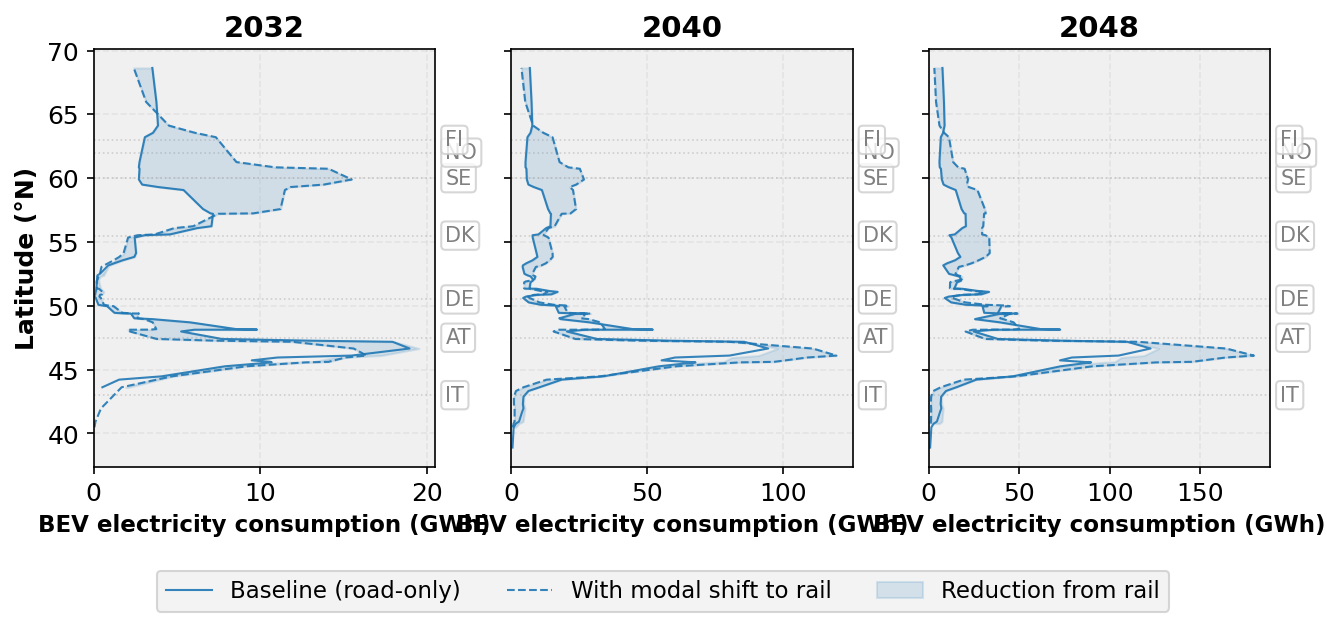

Saved: figures/bev_energy_by_latitude_GoRES_only.pdf


In [89]:
# ============================================================
# Figure 12b: BEV electricity consumption by latitude — Go RES only
# Single row: 3 columns (2032, 2040, 2048), baseline vs rail
# ============================================================

GORES_SCEN = 'Go RES'
GORES_COLOR = SCENARIO_COLORS[GORES_SCEN]

fig, axes = plt.subplots(1, len(COMPARE_YEARS), figsize=(9, 4), sharey=True)

for yi, year in enumerate(COMPARE_YEARS):
    ax = axes[yi]

    for run_type, ls, lw, alpha, label in [
        ('baseline', '-',  1, 0.9, 'Baseline (road-only)'),
        ('rail',     '--', 1, 0.9, 'With modal shift to rail'),
    ]:
        nd = energy_data[GORES_SCEN][run_type][year]
        if not nd:
            continue
        sorted_nodes = sorted(nd.values(), key=lambda x: x['lat'])
        lats = np.array([n['lat'] for n in sorted_nodes])
        energy_vals = np.array([n['energy_mwh'] for n in sorted_nodes])

        if len(lats) > 3:
            smooth = gaussian_filter1d(energy_vals / 1e3, sigma=1.5)  # GWh
        else:
            smooth = energy_vals / 1e3

        ax.plot(smooth, lats, color=GORES_COLOR, linewidth=lw, linestyle=ls,
                label=label if yi == 0 else None, alpha=alpha)

    # Fill between baseline and rail to highlight difference
    base_nd = energy_data[GORES_SCEN]['baseline'][year]
    rail_nd = energy_data[GORES_SCEN]['rail'][year]
    if base_nd and rail_nd:
        # Merge on common latitudes
        all_nodes = set(base_nd.keys()) | set(rail_nd.keys())
        lat_base, lat_rail = {}, {}
        for nid in all_nodes:
            if nid in base_nd:
                lat_base[base_nd[nid]['lat']] = lat_base.get(base_nd[nid]['lat'], 0) + base_nd[nid]['energy_mwh']
            if nid in rail_nd:
                lat_rail[rail_nd[nid]['lat']] = lat_rail.get(rail_nd[nid]['lat'], 0) + rail_nd[nid]['energy_mwh']

        common_lats = sorted(set(lat_base.keys()) & set(lat_rail.keys()))
        if len(common_lats) > 3:
            cl = np.array(common_lats)
            bv = gaussian_filter1d(np.array([lat_base[l] for l in common_lats]) / 1e3, sigma=1.5)
            rv = gaussian_filter1d(np.array([lat_rail[l] for l in common_lats]) / 1e3, sigma=1.5)
            ax.fill_betweenx(cl, rv, bv, alpha=0.15, color=GORES_COLOR,
                             label='Reduction from rail' if yi == 0 else None)

    # Country labels
    for country, clat in COUNTRY_LAT_CENTROIDS.items():
        ax.axhline(clat, color='gray', linestyle=':', alpha=0.3, linewidth=0.8)
        ax.text(1.03, clat, country, transform=ax.get_yaxis_transform(),
                va='center', fontsize=10, color='gray',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                          edgecolor='#ccc', alpha=0.8))

    ax.set_title(f'{year}', fontweight='bold', fontsize=14)
    ax.set_xlabel('BEV electricity consumption (GWh)', fontweight='bold', fontsize=11)
    if yi == 0:
        ax.set_ylabel('Latitude (\u00b0N)', fontweight='bold', fontsize=12)
    ax.grid(True, alpha=0.2, linestyle='--')
    ax.set_xlim(left=0)

# Legend below
fig.legend(loc='lower center', bbox_to_anchor=(0.5, -0.06), ncol=3,
           fontsize=11, frameon=True, edgecolor='#ccc')
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(FIG_DIR / 'bev_energy_by_latitude_GoRES_only.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'bev_energy_by_latitude_GoRES_only.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/bev_energy_by_latitude_GoRES_only.pdf')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

Go RES 2040: total reduction = -214.4 GWh, 37 nodes reduced, 44 nodes increased


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

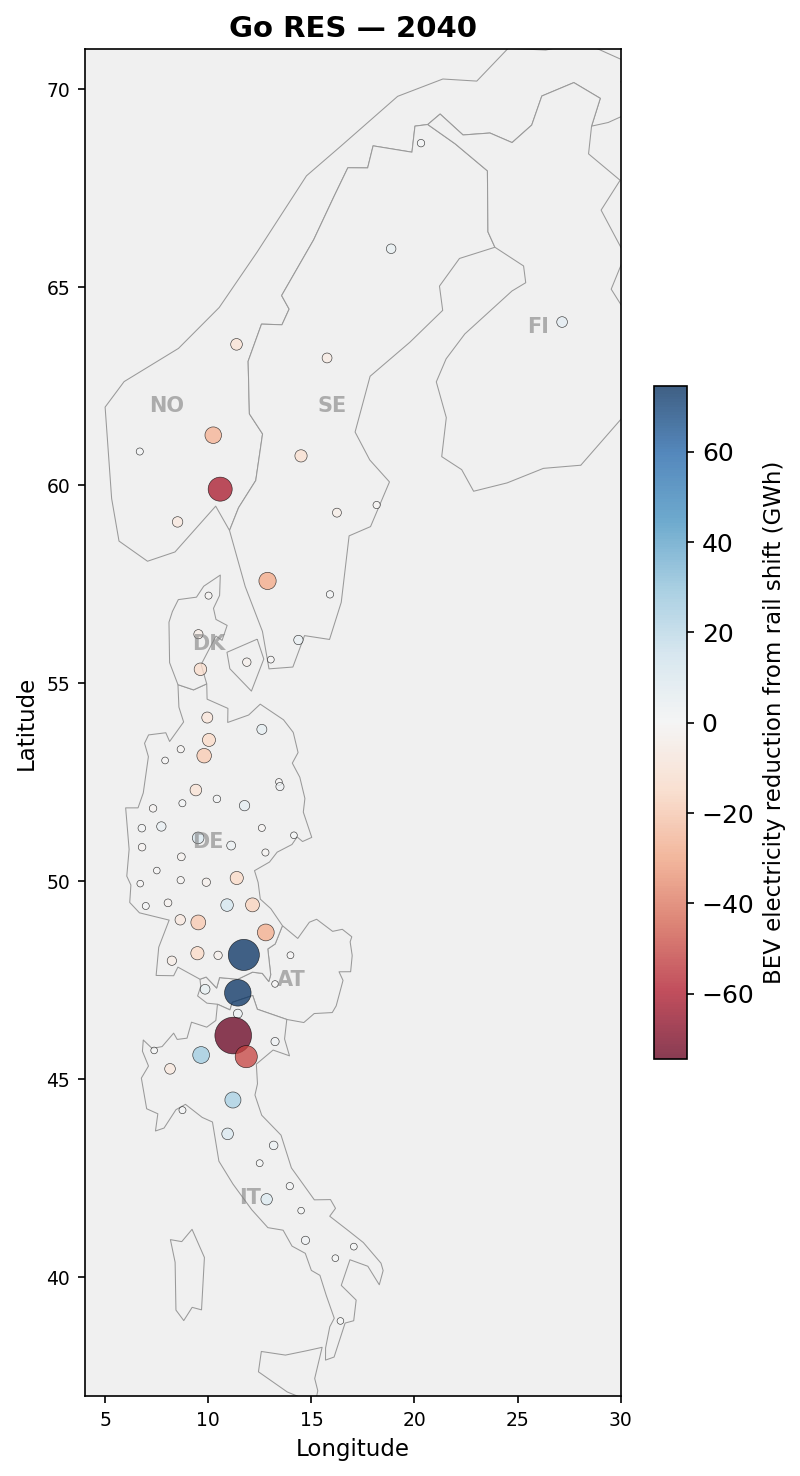

Saved: figures/bev_energy_delta_map_GoRES_only.pdf


In [90]:
# ============================================================
# Figure 12c: MAP — Go RES only — BEV electricity delta (baseline - rail)
# Single-panel version for manuscript
# ============================================================
import geopandas as gpd

world = gpd.read_file('https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip')
corridor_countries = ['Norway', 'Sweden', 'Finland', 'Denmark', 'Germany', 'Austria', 'Italy']
corridor = world[world['NAME'].isin(corridor_countries)]

MAP_YEAR = 2040
scen_name = 'Go RES'

fig, ax = plt.subplots(1, 1, figsize=(6, 10))
corridor.plot(ax=ax, color='#f0f0f0', edgecolor='#999', linewidth=0.5)

base_nodes = energy_data[scen_name]['baseline'][MAP_YEAR]
rail_nodes = energy_data[scen_name]['rail'][MAP_YEAR]

# Compute delta at each node
all_geo_ids = set(base_nodes.keys()) | set(rail_nodes.keys())
lats, lons, deltas = [], [], []
for geo_id in all_geo_ids:
    base_e = base_nodes.get(geo_id, {}).get('energy_mwh', 0)
    rail_e = rail_nodes.get(geo_id, {}).get('energy_mwh', 0)
    delta_gwh = (base_e - rail_e) / 1e3  # positive = rail reduces energy
    nd = base_nodes.get(geo_id) or rail_nodes.get(geo_id)
    lats.append(nd['lat'])
    lons.append(nd['lon'])
    deltas.append(delta_gwh)

deltas = np.array(deltas)
lats = np.array(lats)
lons = np.array(lons)

# Size by absolute delta
abs_d = np.abs(deltas)
max_d = max(abs_d.max(), 1)
sizes = (abs_d / max_d) * 300 + 10

# Color: blue = rail reduces energy (positive), red = rail increases
sc = ax.scatter(lons, lats, s=sizes, c=deltas, cmap='RdBu',
                alpha=0.75, edgecolors='black', linewidth=0.3,
                vmin=-max_d * 0.5, vmax=max_d * 0.5)

ax.set_xlim(4, 30)
ax.set_ylim(37, 71)
ax.set_title(f'Go RES — {MAP_YEAR}', fontweight='bold', fontsize=14)
ax.set_xlabel('Longitude', fontsize=11)
ax.set_ylabel('Latitude', fontsize=11)
ax.tick_params(labelsize=9)

# Country name labels
for name, (cx, cy) in {"NO": (8,62), "SE": (16,62), "FI": (26,64),
                        "DK": (10,56), "DE": (10,51), "AT": (14,47.5), "IT": (12,42)}.items():
    ax.text(cx, cy, name, fontsize=10, color="gray", fontweight="bold",
            ha="center", va="center", alpha=0.6)

cbar = fig.colorbar(sc, ax=ax, shrink=0.5, pad=0.04)
cbar.set_label(f'BEV electricity reduction from rail shift (GWh)', fontsize=11)

# Print summary stats
total_reduction = deltas.sum()
n_positive = (deltas > 0).sum()
n_negative = (deltas < 0).sum()
print(f'Go RES {MAP_YEAR}: total reduction = {total_reduction:.1f} GWh, '
      f'{n_positive} nodes reduced, {n_negative} nodes increased')

plt.tight_layout()
plt.savefig(FIG_DIR / 'bev_energy_delta_map_GoRES_only.pdf', bbox_inches='tight')
plt.savefig(FIG_DIR / 'bev_energy_delta_map_GoRES_only.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: figures/bev_energy_delta_map_GoRES_only.pdf')